In [12]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [13]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2019/UROLOGÍA.pdf'

In [14]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [15]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [16]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 11 questions
Page 1, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=109.8, y1=109.2
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 124
Page 1, Q1, A: Yellow percentage: 0.0%


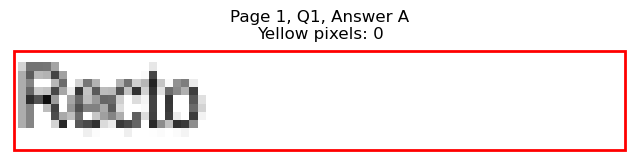

Page 1, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=116.5, y1=121.3
Page 1, Q1, B: Yellow pixels: 0
Page 1, Q1, B: Total non-white pixels: 137
Page 1, Q1, B: Yellow percentage: 0.0%


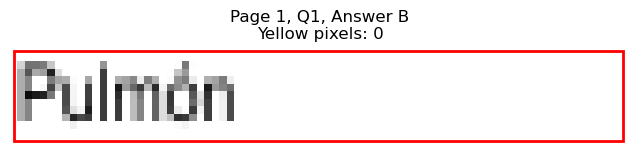

Page 1, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=111.3, y1=133.3
Page 1, Q1, C: Yellow pixels: 0
Page 1, Q1, C: Total non-white pixels: 138
Page 1, Q1, C: Yellow percentage: 0.0%


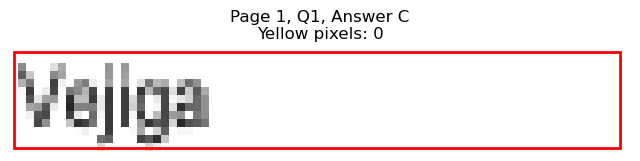

Page 1, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=366.8, y1=109.2
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 170
Page 1, Q1, D: Yellow percentage: 0.0%


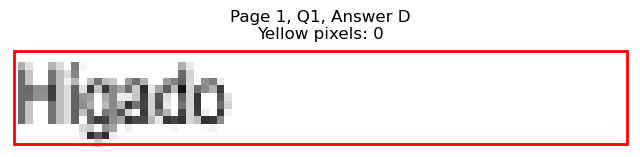

Page 1, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=363.9, y1=121.3
Page 1, Q1, E: Yellow pixels: 824
Page 1, Q1, E: Total non-white pixels: 1014
Page 1, Q1, E: Yellow percentage: 81.3%


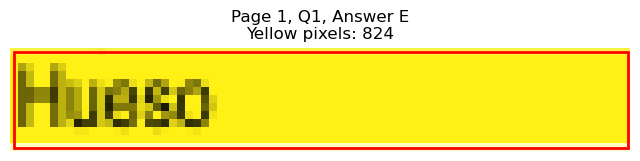


Page 1, Q1 - Selected Answer: E (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=85.0, y0=157.3, x1=153.5, y1=169.4
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 340
Page 1, Q2, A: Yellow percentage: 0.0%


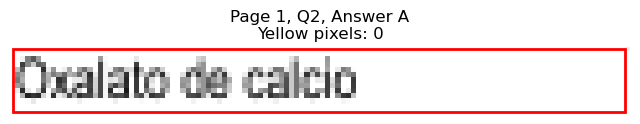

Page 1, Q2 - B: Detected box: x0=85.0, y0=169.4, x1=152.5, y1=181.5
Page 1, Q2, B: Yellow pixels: 119
Page 1, Q2, B: Total non-white pixels: 453
Page 1, Q2, B: Yellow percentage: 26.3%


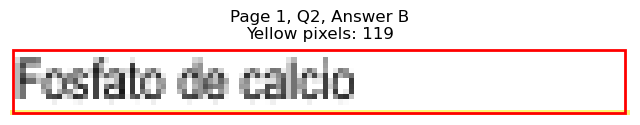

Page 1, Q2 - C: Detected box: x0=85.0, y0=181.4, x1=120.9, y1=193.5
Page 1, Q2, C: Yellow pixels: 986
Page 1, Q2, C: Total non-white pixels: 1131
Page 1, Q2, C: Yellow percentage: 87.2%


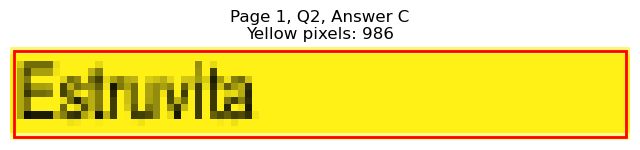

Page 1, Q2 - D: Detected box: x0=336.7, y0=157.3, x1=381.7, y1=169.4
Page 1, Q2, D: Yellow pixels: 0
Page 1, Q2, D: Total non-white pixels: 208
Page 1, Q2, D: Yellow percentage: 0.0%


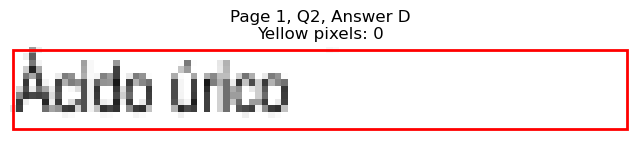

Page 1, Q2 - E: Detected box: x0=336.7, y0=169.4, x1=365.4, y1=181.5
Page 1, Q2, E: Yellow pixels: 0
Page 1, Q2, E: Total non-white pixels: 145
Page 1, Q2, E: Yellow percentage: 0.0%


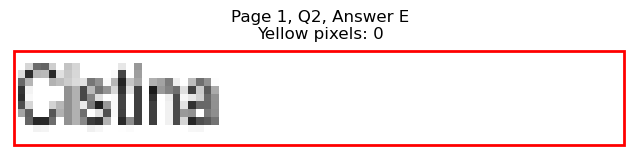


Page 1, Q2 - Selected Answer: C (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=99.3, y0=217.5, x1=127.6, y1=229.7
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 128
Page 1, Q3, A: Yellow percentage: 0.0%


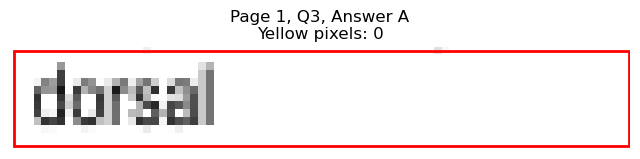

Page 1, Q3 - B: Detected box: x0=96.0, y0=229.7, x1=124.8, y1=241.8
Page 1, Q3, B: Yellow pixels: 0
Page 1, Q3, B: Total non-white pixels: 142
Page 1, Q3, B: Yellow percentage: 0.0%


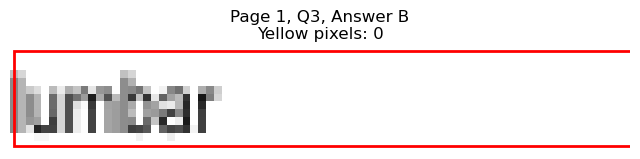

Page 1, Q3 - C: Detected box: x0=94.5, y0=241.7, x1=123.3, y1=253.8
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 129
Page 1, Q3, C: Yellow percentage: 0.0%


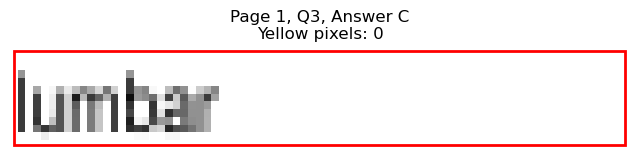

Page 1, Q3 - D: Detected box: x0=351.0, y0=217.5, x1=376.9, y1=229.7
Page 1, Q3, D: Yellow pixels: 902
Page 1, Q3, D: Total non-white pixels: 1001
Page 1, Q3, D: Yellow percentage: 90.1%


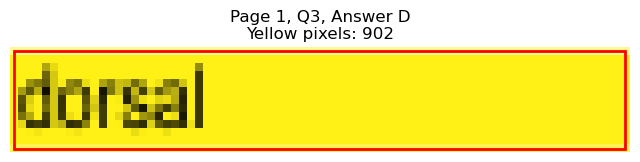

Page 1, Q3 - E: Detected box: x0=346.1, y0=229.7, x1=375.0, y1=241.8
Page 1, Q3, E: Yellow pixels: 79
Page 1, Q3, E: Total non-white pixels: 226
Page 1, Q3, E: Yellow percentage: 35.0%


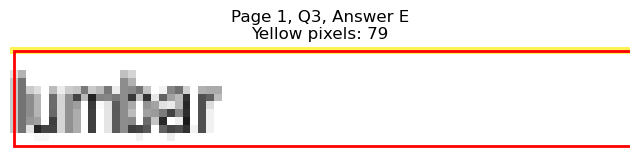


Page 1, Q3 - Selected Answer: D (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=70.8, y0=301.9, x1=79.0, y1=314.0
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 48
Page 1, Q4, A: Yellow percentage: 0.0%


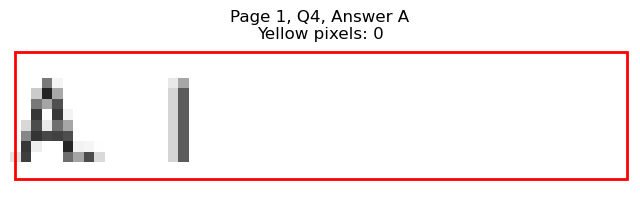

Page 1, Q4 - B: Detected box: x0=85.0, y0=313.9, x1=94.6, y1=326.0
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 48
Page 1, Q4, B: Yellow percentage: 0.0%


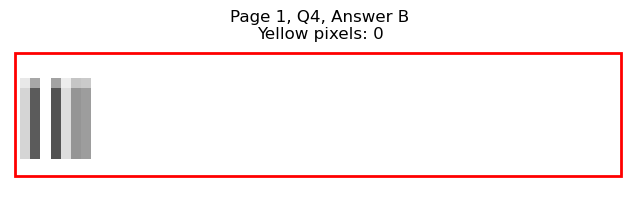

Page 1, Q4 - C: Detected box: x0=85.0, y0=326.1, x1=95.6, y1=338.2
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 42
Page 1, Q4, C: Yellow percentage: 0.0%


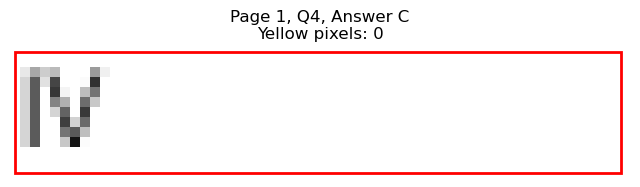

Page 1, Q4 - D: Detected box: x0=322.5, y0=301.9, x1=331.2, y1=314.0
Page 1, Q4, D: Yellow pixels: 60
Page 1, Q4, D: Total non-white pixels: 181
Page 1, Q4, D: Yellow percentage: 33.1%


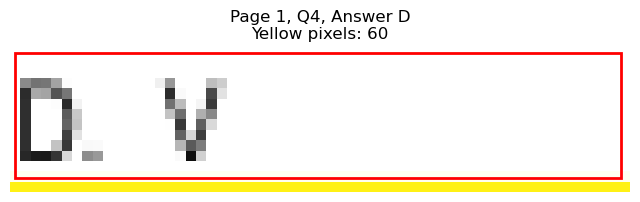

Page 1, Q4 - E: Detected box: x0=322.5, y0=313.9, x1=330.7, y1=326.0
Page 1, Q4, E: Yellow pixels: 649
Page 1, Q4, E: Total non-white pixels: 826
Page 1, Q4, E: Yellow percentage: 78.6%


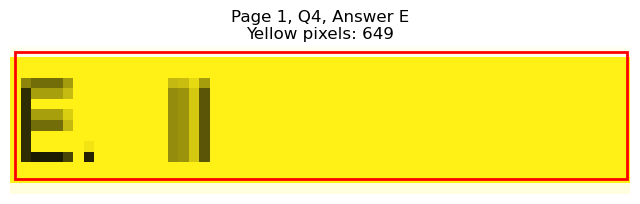


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=85.0, y0=362.2, x1=132.9, y1=374.3
Page 1, Q5, A: Yellow pixels: 99
Page 1, Q5, A: Total non-white pixels: 368
Page 1, Q5, A: Yellow percentage: 26.9%


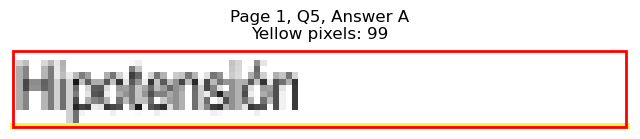

Page 1, Q5 - B: Detected box: x0=85.0, y0=374.2, x1=129.0, y1=386.3
Page 1, Q5, B: Yellow pixels: 964
Page 1, Q5, B: Total non-white pixels: 1248
Page 1, Q5, B: Yellow percentage: 77.2%


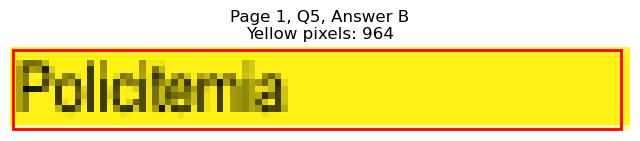

Page 1, Q5 - C: Detected box: x0=85.0, y0=386.3, x1=140.5, y1=398.4
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 393
Page 1, Q5, C: Yellow percentage: 0.0%


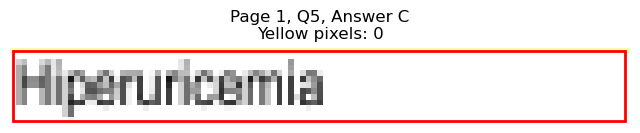

Page 1, Q5 - D: Detected box: x0=336.7, y0=362.2, x1=390.8, y1=374.3
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 280
Page 1, Q5, D: Yellow percentage: 0.0%


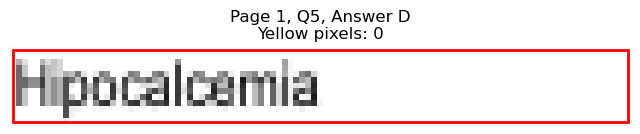

Page 1, Q5 - E: Detected box: x0=336.7, y0=374.2, x1=367.8, y1=386.3
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 167
Page 1, Q5, E: Yellow percentage: 0.0%


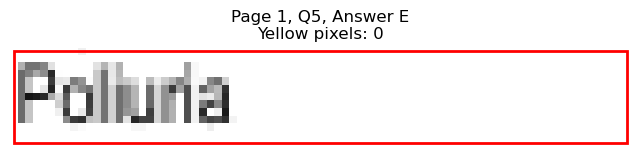


Page 1, Q5 - Selected Answer: B (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=85.0, y0=422.4, x1=186.0, y1=434.5
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 522
Page 1, Q6, A: Yellow percentage: 0.0%


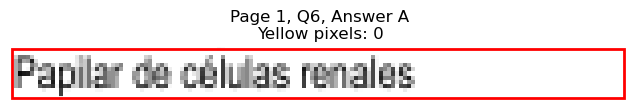

Page 1, Q6 - B: Detected box: x0=85.0, y0=434.4, x1=201.3, y1=446.5
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 573
Page 1, Q6, B: Yellow percentage: 0.0%


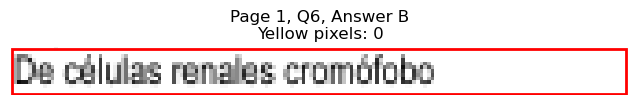

Page 1, Q6 - C: Detected box: x0=85.0, y0=446.6, x1=158.7, y1=458.7
Page 1, Q6, C: Yellow pixels: 0
Page 1, Q6, C: Total non-white pixels: 364
Page 1, Q6, C: Yellow percentage: 0.0%


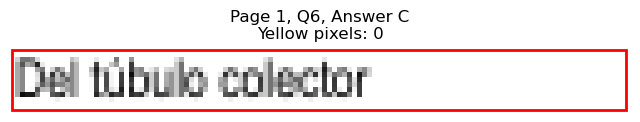

Page 1, Q6 - D: Detected box: x0=336.7, y0=422.4, x1=404.6, y1=434.5
Page 1, Q6, D: Yellow pixels: 1266
Page 1, Q6, D: Total non-white pixels: 1547
Page 1, Q6, D: Yellow percentage: 81.8%


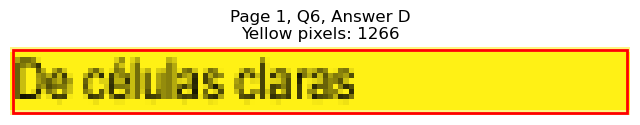

Page 1, Q6 - E: Detected box: x0=336.7, y0=434.4, x1=395.1, y1=446.5
Page 1, Q6, E: Yellow pixels: 110
Page 1, Q6, E: Total non-white pixels: 401
Page 1, Q6, E: Yellow percentage: 27.4%


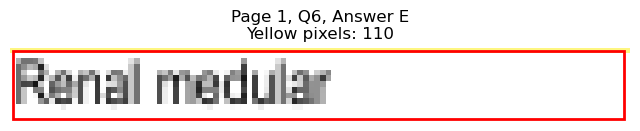


Page 1, Q6 - Selected Answer: D (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=85.0, y0=494.7, x1=156.7, y1=506.8
Page 1, Q7, A: Yellow pixels: 0
Page 1, Q7, A: Total non-white pixels: 383
Page 1, Q7, A: Yellow percentage: 0.0%


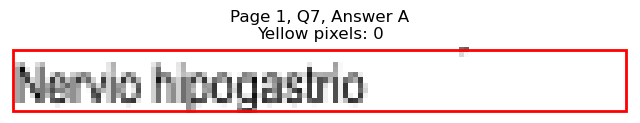

Page 1, Q7 - B: Detected box: x0=85.0, y0=506.8, x1=155.8, y1=518.9
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 480
Page 1, Q7, B: Yellow percentage: 0.0%


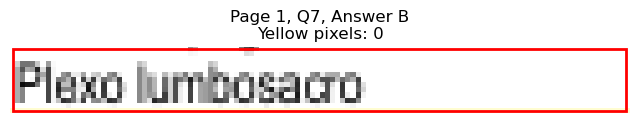

Page 1, Q7 - C: Detected box: x0=85.0, y0=518.8, x1=146.8, y1=530.9
Page 1, Q7, C: Yellow pixels: 1099
Page 1, Q7, C: Total non-white pixels: 1469
Page 1, Q7, C: Yellow percentage: 74.8%


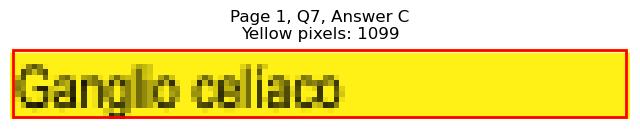

Page 1, Q7 - D: Detected box: x0=336.7, y0=494.7, x1=406.5, y1=506.8
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 375
Page 1, Q7, D: Yellow percentage: 0.0%


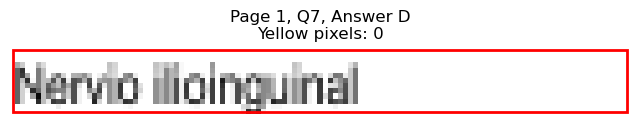

Page 1, Q7 - E: Detected box: x0=336.7, y0=506.8, x1=403.2, y1=518.9
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 347
Page 1, Q7, E: Yellow percentage: 0.0%


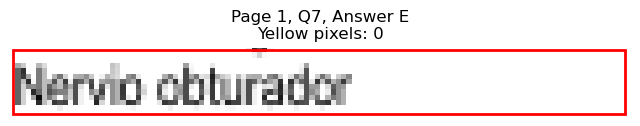


Page 1, Q7 - Selected Answer: C (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=85.0, y0=554.9, x1=191.8, y1=567.0
Page 1, Q8, A: Yellow pixels: 0
Page 1, Q8, A: Total non-white pixels: 526
Page 1, Q8, A: Yellow percentage: 0.0%


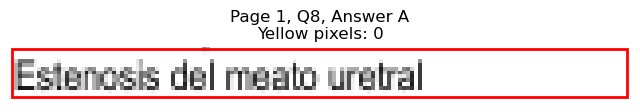

Page 1, Q8 - B: Detected box: x0=85.0, y0=567.1, x1=193.3, y1=579.2
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 526
Page 1, Q8, B: Yellow percentage: 0.0%


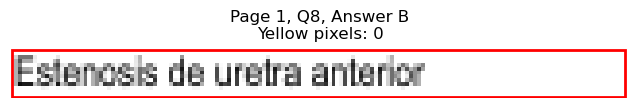

Page 1, Q8 - C: Detected box: x0=85.0, y0=579.1, x1=195.2, y1=591.2
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 607
Page 1, Q8, C: Yellow percentage: 0.0%


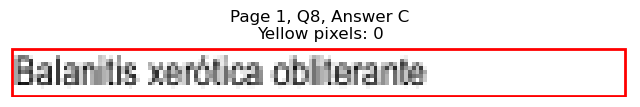

Page 1, Q8 - D: Detected box: x0=336.7, y0=554.9, x1=420.4, y1=567.0
Page 1, Q8, D: Yellow pixels: 1285
Page 1, Q8, D: Total non-white pixels: 1890
Page 1, Q8, D: Yellow percentage: 68.0%


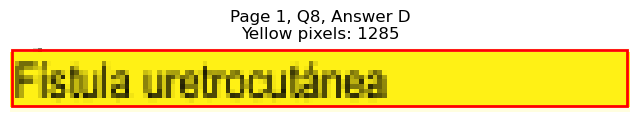

Page 1, Q8 - E: Detected box: x0=336.7, y0=567.1, x1=398.4, y1=579.2
Page 1, Q8, E: Yellow pixels: 0
Page 1, Q8, E: Total non-white pixels: 441
Page 1, Q8, E: Yellow percentage: 0.0%


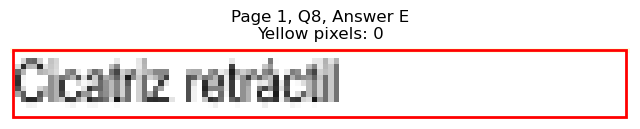


Page 1, Q8 - Selected Answer: D (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=85.0, y0=627.3, x1=162.0, y1=639.4
Page 1, Q9, A: Yellow pixels: 129
Page 1, Q9, A: Total non-white pixels: 538
Page 1, Q9, A: Yellow percentage: 24.0%


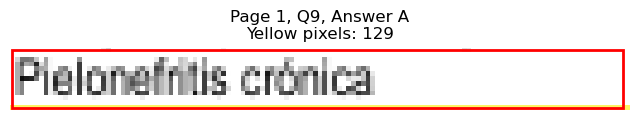

Page 1, Q9 - B: Detected box: x0=85.0, y0=639.3, x1=212.3, y1=651.4
Page 1, Q9, B: Yellow pixels: 1761
Page 1, Q9, B: Total non-white pixels: 2327
Page 1, Q9, B: Yellow percentage: 75.7%


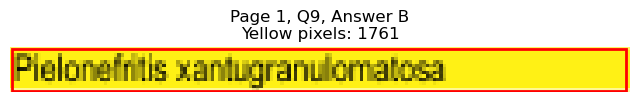

Page 1, Q9 - C: Detected box: x0=85.0, y0=651.4, x1=175.5, y1=663.5
Page 1, Q9, C: Yellow pixels: 142
Page 1, Q9, C: Total non-white pixels: 615
Page 1, Q9, C: Yellow percentage: 23.1%


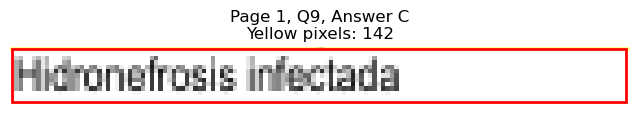

Page 1, Q9 - D: Detected box: x0=336.7, y0=627.3, x1=437.2, y1=639.4
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 541
Page 1, Q9, D: Yellow percentage: 0.0%


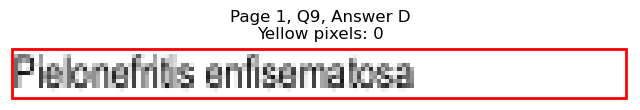

Page 1, Q9 - E: Detected box: x0=336.7, y0=639.3, x1=447.2, y1=651.4
Page 1, Q9, E: Yellow pixels: 0
Page 1, Q9, E: Total non-white pixels: 601
Page 1, Q9, E: Yellow percentage: 0.0%


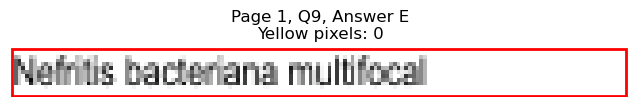


Page 1, Q9 - Selected Answer: B (based on yellow pixel count)




Page 1, Q10 - A: Detected box: x0=85.0, y0=687.5, x1=249.2, y1=699.7
Page 1, Q10, A: Yellow pixels: 0
Page 1, Q10, A: Total non-white pixels: 794
Page 1, Q10, A: Yellow percentage: 0.0%


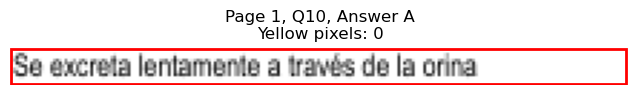

Page 1, Q10 - B: Detected box: x0=85.0, y0=699.5, x1=229.1, y1=711.7
Page 1, Q10, B: Yellow pixels: 0
Page 1, Q10, B: Total non-white pixels: 702
Page 1, Q10, B: Yellow percentage: 0.0%


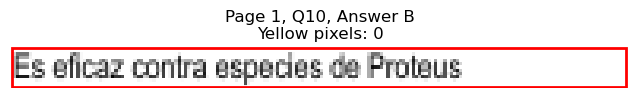

Page 1, Q10 - C: Detected box: x0=85.0, y0=711.7, x1=266.0, y1=723.8
Page 1, Q10, C: Yellow pixels: 0
Page 1, Q10, C: Total non-white pixels: 915
Page 1, Q10, C: Yellow percentage: 0.0%


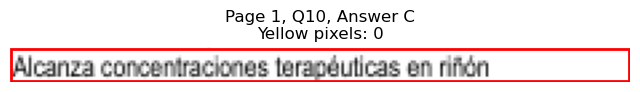

Page 1, Q10 - D: Detected box: x0=336.7, y0=687.5, x1=512.4, y1=699.7
Page 1, Q10, D: Yellow pixels: 1774
Page 1, Q10, D: Total non-white pixels: 2470
Page 1, Q10, D: Yellow percentage: 71.8%


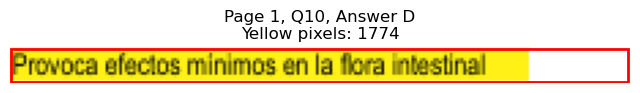

Page 1, Q10 - E: Detected box: x0=336.7, y0=699.5, x1=491.3, y1=711.7
Page 1, Q10, E: Yellow pixels: 190
Page 1, Q10, E: Total non-white pixels: 952
Page 1, Q10, E: Yellow percentage: 20.0%


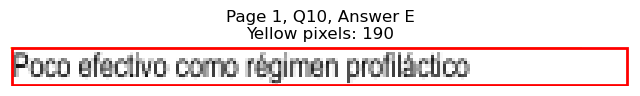


Page 1, Q10 - Selected Answer: D (based on yellow pixel count)




Page 1, Q11 - A: Detected box: x0=85.0, y0=747.8, x1=197.9, y1=759.9
Page 1, Q11, A: Yellow pixels: 1505
Page 1, Q11, A: Total non-white pixels: 2132
Page 1, Q11, A: Yellow percentage: 70.6%


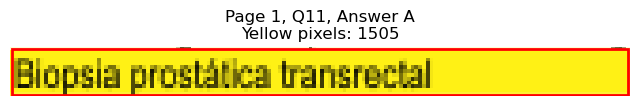

Page 1, Q11 - B: Detected box: x0=85.0, y0=759.8, x1=167.3, y1=771.9
Page 1, Q11, B: Yellow pixels: 132
Page 1, Q11, B: Total non-white pixels: 565
Page 1, Q11, B: Yellow percentage: 23.4%


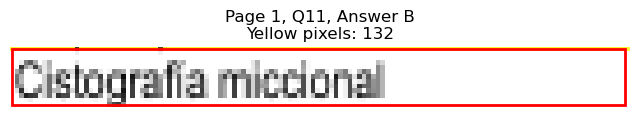

Page 1, Q11 - C: Detected box: x0=85.0, y0=771.9, x1=200.3, y1=784.0
Page 1, Q11, C: Yellow pixels: 0
Page 1, Q11, C: Total non-white pixels: 647
Page 1, Q11, C: Yellow percentage: 0.0%


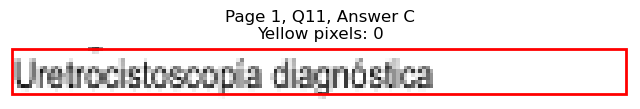

Page 1, Q11 - D: Detected box: x0=336.7, y0=747.8, x1=417.1, y1=759.9
Page 1, Q11, D: Yellow pixels: 0
Page 1, Q11, D: Total non-white pixels: 431
Page 1, Q11, D: Yellow percentage: 0.0%


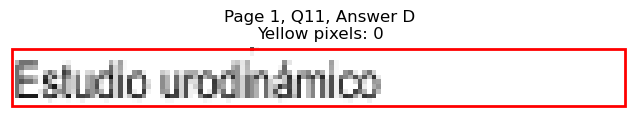

Page 1, Q11 - E: Detected box: x0=336.7, y0=759.8, x1=421.0, y1=771.9
Page 1, Q11, E: Yellow pixels: 0
Page 1, Q11, E: Total non-white pixels: 444
Page 1, Q11, E: Yellow percentage: 0.0%


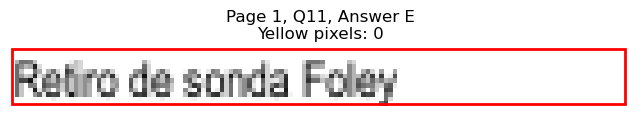


Page 1, Q11 - Selected Answer: A (based on yellow pixel count)





Page 2: Found 10 questions
Page 2, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=208.5, y1=109.2
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 666
Page 2, Q1, A: Yellow percentage: 0.0%


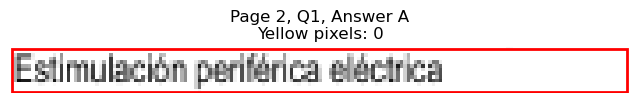

Page 2, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=151.1, y1=121.3
Page 2, Q1, B: Yellow pixels: 118
Page 2, Q1, B: Total non-white pixels: 457
Page 2, Q1, B: Yellow percentage: 25.8%


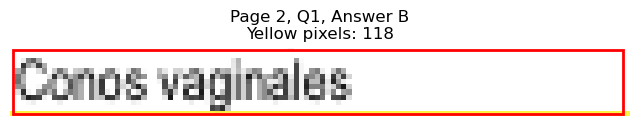

Page 2, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=160.6, y1=133.3
Page 2, Q1, C: Yellow pixels: 1210
Page 2, Q1, C: Total non-white pixels: 1651
Page 2, Q1, C: Yellow percentage: 73.3%


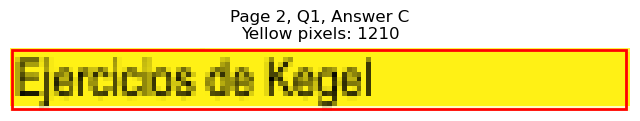

Page 2, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=430.0, y1=109.2
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 507
Page 2, Q1, D: Yellow percentage: 0.0%


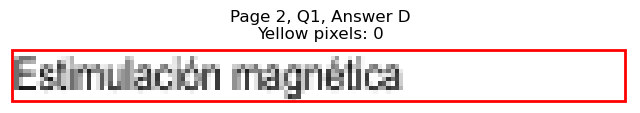

Page 2, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=458.3, y1=121.3
Page 2, Q1, E: Yellow pixels: 0
Page 2, Q1, E: Total non-white pixels: 641
Page 2, Q1, E: Yellow percentage: 0.0%


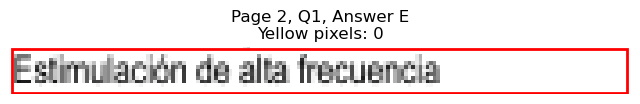


Page 2, Q1 - Selected Answer: C (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=85.0, y0=157.3, x1=130.5, y1=169.4
Page 2, Q2, A: Yellow pixels: 0
Page 2, Q2, A: Total non-white pixels: 243
Page 2, Q2, A: Yellow percentage: 0.0%


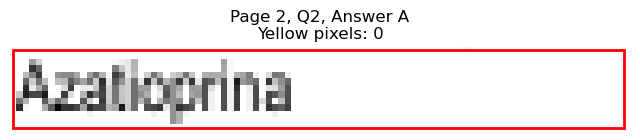

Page 2, Q2 - B: Detected box: x0=85.0, y0=169.4, x1=122.8, y1=181.5
Page 2, Q2, B: Yellow pixels: 1000
Page 2, Q2, B: Total non-white pixels: 1157
Page 2, Q2, B: Yellow percentage: 86.4%


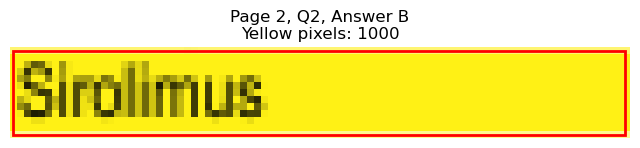

Page 2, Q2 - C: Detected box: x0=85.0, y0=181.4, x1=129.5, y1=193.5
Page 2, Q2, C: Yellow pixels: 96
Page 2, Q2, C: Total non-white pixels: 323
Page 2, Q2, C: Yellow percentage: 29.7%


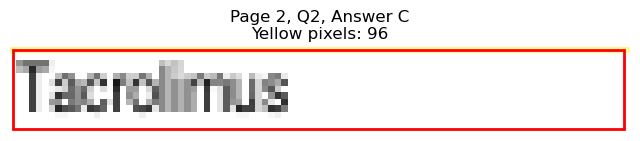

Page 2, Q2 - D: Detected box: x0=336.7, y0=157.3, x1=377.4, y1=169.4
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 229
Page 2, Q2, D: Yellow percentage: 0.0%


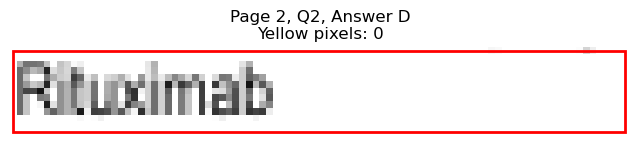

Page 2, Q2 - E: Detected box: x0=336.7, y0=169.4, x1=385.0, y1=181.5
Page 2, Q2, E: Yellow pixels: 0
Page 2, Q2, E: Total non-white pixels: 239
Page 2, Q2, E: Yellow percentage: 0.0%


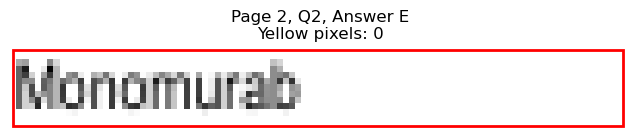


Page 2, Q2 - Selected Answer: B (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=85.0, y0=241.7, x1=202.3, y1=253.8
Page 2, Q3, A: Yellow pixels: 0
Page 2, Q3, A: Total non-white pixels: 610
Page 2, Q3, A: Yellow percentage: 0.0%


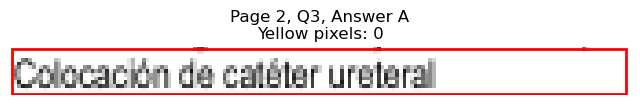

Page 2, Q3 - B: Detected box: x0=85.0, y0=253.7, x1=196.6, y1=265.8
Page 2, Q3, B: Yellow pixels: 0
Page 2, Q3, B: Total non-white pixels: 605
Page 2, Q3, B: Yellow percentage: 0.0%


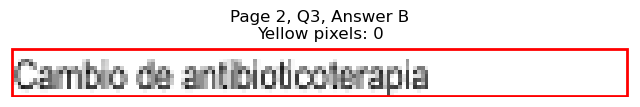

Page 2, Q3 - C: Detected box: x0=85.0, y0=265.8, x1=169.2, y1=277.9
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 418
Page 2, Q3, C: Yellow percentage: 0.0%


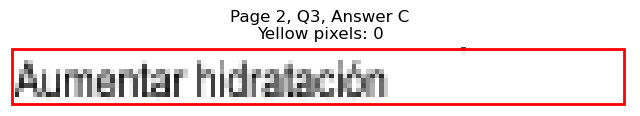

Page 2, Q3 - D: Detected box: x0=336.7, y0=241.7, x1=429.6, y1=253.8
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 608
Page 2, Q3, D: Yellow percentage: 0.0%


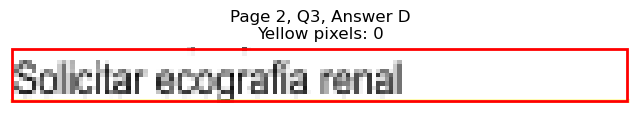

Page 2, Q3 - E: Detected box: x0=336.7, y0=253.7, x1=445.3, y1=265.8
Page 2, Q3, E: Yellow pixels: 1444
Page 2, Q3, E: Total non-white pixels: 2080
Page 2, Q3, E: Yellow percentage: 69.4%


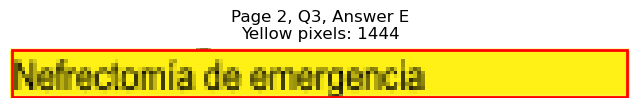


Page 2, Q3 - Selected Answer: E (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=85.0, y0=301.9, x1=115.6, y1=314.0
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 120
Page 2, Q4, A: Yellow percentage: 0.0%


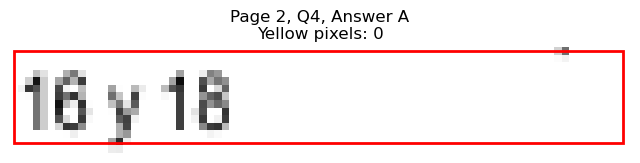

Page 2, Q4 - B: Detected box: x0=85.0, y0=313.9, x1=115.6, y1=326.0
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 128
Page 2, Q4, B: Yellow percentage: 0.0%


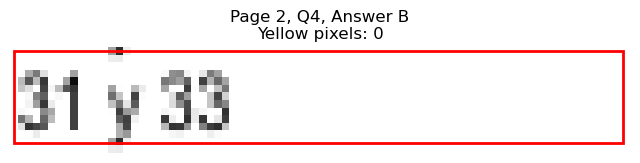

Page 2, Q4 - C: Detected box: x0=85.0, y0=326.1, x1=115.6, y1=338.2
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 147
Page 2, Q4, C: Yellow percentage: 0.0%


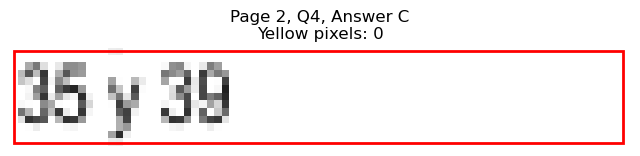

Page 2, Q4 - D: Detected box: x0=336.7, y0=301.9, x1=362.6, y1=314.0
Page 2, Q4, D: Yellow pixels: 857
Page 2, Q4, D: Total non-white pixels: 1003
Page 2, Q4, D: Yellow percentage: 85.4%


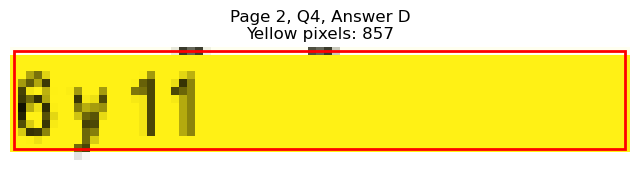

Page 2, Q4 - E: Detected box: x0=336.7, y0=313.9, x1=367.3, y1=326.0
Page 2, Q4, E: Yellow pixels: 80
Page 2, Q4, E: Total non-white pixels: 212
Page 2, Q4, E: Yellow percentage: 37.7%


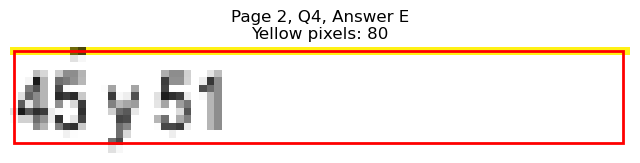


Page 2, Q4 - Selected Answer: D (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=85.0, y0=362.2, x1=170.7, y1=374.3
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 463
Page 2, Q5, A: Yellow percentage: 0.0%


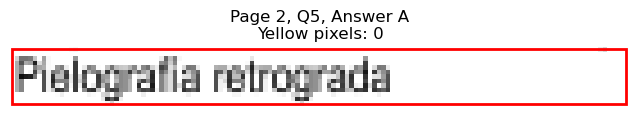

Page 2, Q5 - B: Detected box: x0=85.0, y0=374.2, x1=203.7, y1=386.3
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 589
Page 2, Q5, B: Yellow percentage: 0.0%


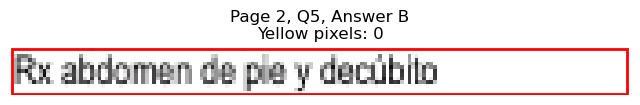

Page 2, Q5 - C: Detected box: x0=85.0, y0=386.3, x1=182.2, y1=398.4
Page 2, Q5, C: Yellow pixels: 1385
Page 2, Q5, C: Total non-white pixels: 1937
Page 2, Q5, C: Yellow percentage: 71.5%


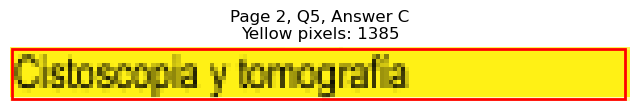

Page 2, Q5 - D: Detected box: x0=336.7, y0=362.2, x1=441.4, y1=374.3
Page 2, Q5, D: Yellow pixels: 0
Page 2, Q5, D: Total non-white pixels: 556
Page 2, Q5, D: Yellow percentage: 0.0%


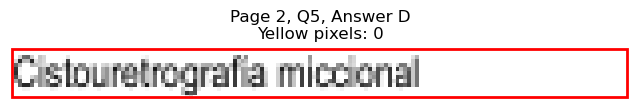

Page 2, Q5 - E: Detected box: x0=336.7, y0=374.2, x1=433.9, y1=386.3
Page 2, Q5, E: Yellow pixels: 0
Page 2, Q5, E: Total non-white pixels: 476
Page 2, Q5, E: Yellow percentage: 0.0%


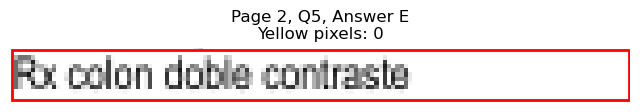


Page 2, Q5 - Selected Answer: C (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=85.0, y0=422.4, x1=112.7, y1=434.5
Page 2, Q6, A: Yellow pixels: 924
Page 2, Q6, A: Total non-white pixels: 1027
Page 2, Q6, A: Yellow percentage: 90.0%


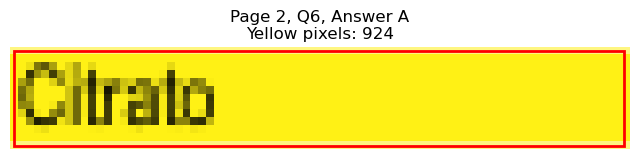

Page 2, Q6 - B: Detected box: x0=85.0, y0=434.4, x1=124.7, y1=446.5
Page 2, Q6, B: Yellow pixels: 91
Page 2, Q6, B: Total non-white pixels: 311
Page 2, Q6, B: Yellow percentage: 29.3%


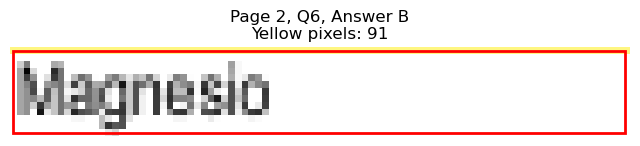

Page 2, Q6 - C: Detected box: x0=85.0, y0=446.6, x1=148.2, y1=458.7
Page 2, Q6, C: Yellow pixels: 0
Page 2, Q6, C: Total non-white pixels: 338
Page 2, Q6, C: Yellow percentage: 0.0%


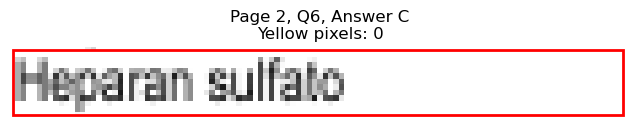

Page 2, Q6 - D: Detected box: x0=336.7, y0=422.4, x1=380.2, y1=434.5
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 235
Page 2, Q6, D: Yellow percentage: 0.0%


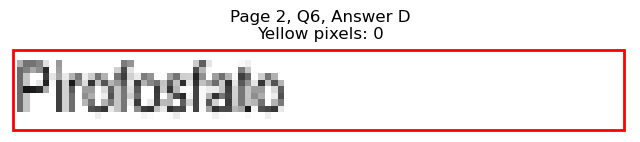

Page 2, Q6 - E: Detected box: x0=336.7, y0=434.4, x1=355.4, y1=446.5
Page 2, Q6, E: Yellow pixels: 0
Page 2, Q6, E: Total non-white pixels: 82
Page 2, Q6, E: Yellow percentage: 0.0%


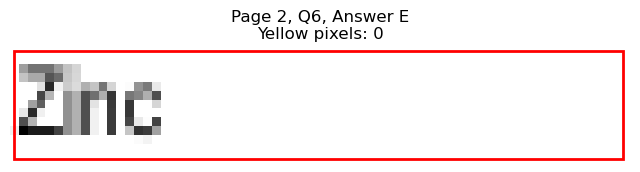


Page 2, Q6 - Selected Answer: A (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=85.0, y0=494.7, x1=197.0, y1=506.8
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 562
Page 2, Q7, A: Yellow percentage: 0.0%


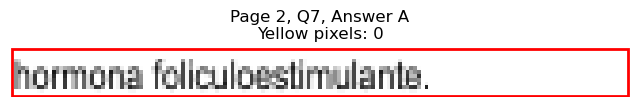

Page 2, Q7 - B: Detected box: x0=85.0, y0=506.8, x1=163.0, y1=518.9
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 409
Page 2, Q7, B: Yellow percentage: 0.0%


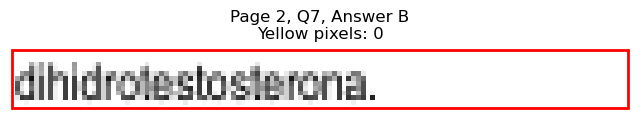

Page 2, Q7 - C: Detected box: x0=85.0, y0=518.8, x1=136.2, y1=530.9
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 247
Page 2, Q7, C: Yellow percentage: 0.0%


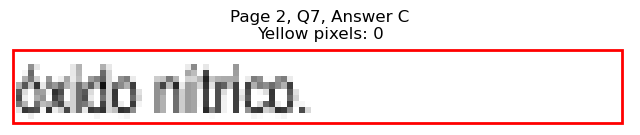

Page 2, Q7 - D: Detected box: x0=336.7, y0=494.7, x1=421.4, y1=506.8
Page 2, Q7, D: Yellow pixels: 1271
Page 2, Q7, D: Total non-white pixels: 1768
Page 2, Q7, D: Yellow percentage: 71.9%


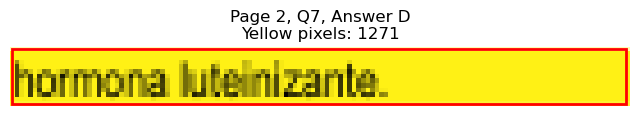

Page 2, Q7 - E: Detected box: x0=336.7, y0=506.8, x1=407.5, y1=518.9
Page 2, Q7, E: Yellow pixels: 122
Page 2, Q7, E: Total non-white pixels: 492
Page 2, Q7, E: Yellow percentage: 24.8%


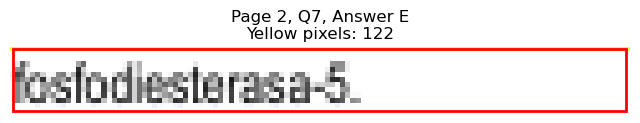


Page 2, Q7 - Selected Answer: D (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=85.0, y0=554.9, x1=231.4, y1=567.0
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 719
Page 2, Q8, A: Yellow percentage: 0.0%


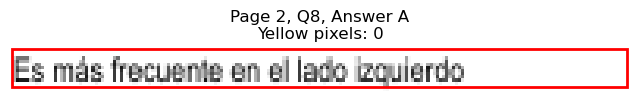

Page 2, Q8 - B: Detected box: x0=85.0, y0=567.1, x1=223.4, y1=579.2
Page 2, Q8, B: Yellow pixels: 0
Page 2, Q8, B: Total non-white pixels: 652
Page 2, Q8, B: Yellow percentage: 0.0%


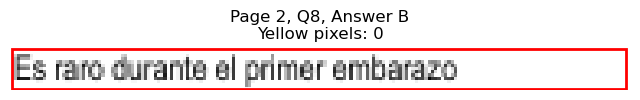

Page 2, Q8 - C: Detected box: x0=85.0, y0=579.1, x1=215.2, y1=591.2
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 676
Page 2, Q8, C: Yellow percentage: 0.0%


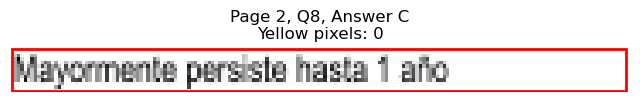

Page 2, Q8 - D: Detected box: x0=336.7, y0=554.9, x1=449.1, y1=567.0
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 538
Page 2, Q8, D: Yellow percentage: 0.0%


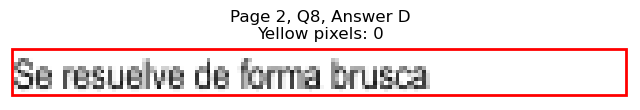

Page 2, Q8 - E: Detected box: x0=336.7, y0=567.1, x1=476.0, y1=579.2
Page 2, Q8, E: Yellow pixels: 1708
Page 2, Q8, E: Total non-white pixels: 2470
Page 2, Q8, E: Yellow percentage: 69.1%


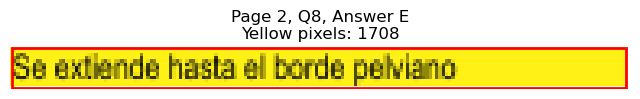


Page 2, Q8 - Selected Answer: E (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=85.0, y0=651.4, x1=165.9, y1=663.5
Page 2, Q9, A: Yellow pixels: 132
Page 2, Q9, A: Total non-white pixels: 541
Page 2, Q9, A: Yellow percentage: 24.4%


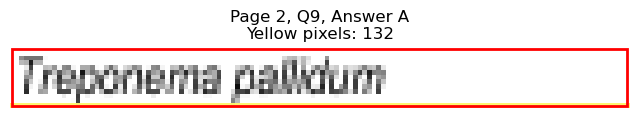

Page 2, Q9 - B: Detected box: x0=85.0, y0=663.4, x1=167.8, y1=675.5
Page 2, Q9, B: Yellow pixels: 1405
Page 2, Q9, B: Total non-white pixels: 1742
Page 2, Q9, B: Yellow percentage: 80.7%


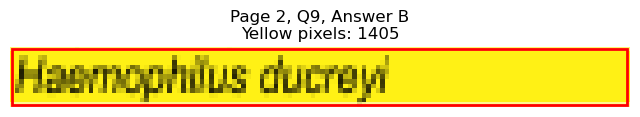

Page 2, Q9 - C: Detected box: x0=85.0, y0=675.4, x1=163.0, y1=687.5
Page 2, Q9, C: Yellow pixels: 129
Page 2, Q9, C: Total non-white pixels: 526
Page 2, Q9, C: Yellow percentage: 24.5%


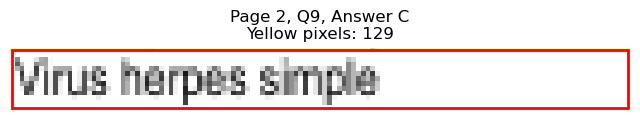

Page 2, Q9 - D: Detected box: x0=336.7, y0=651.4, x1=426.7, y1=663.5
Page 2, Q9, D: Yellow pixels: 0
Page 2, Q9, D: Total non-white pixels: 476
Page 2, Q9, D: Yellow percentage: 0.0%


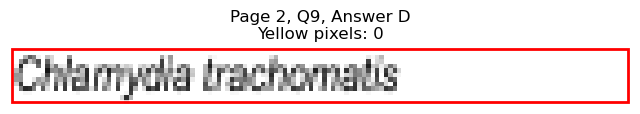

Page 2, Q9 - E: Detected box: x0=336.7, y0=663.4, x1=429.6, y1=675.5
Page 2, Q9, E: Yellow pixels: 0
Page 2, Q9, E: Total non-white pixels: 465
Page 2, Q9, E: Yellow percentage: 0.0%


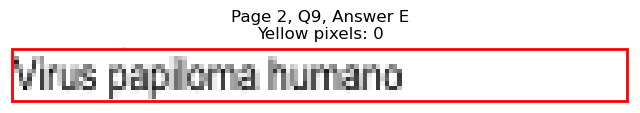


Page 2, Q9 - Selected Answer: B (based on yellow pixel count)




Page 2, Q10 - A: Detected box: x0=85.0, y0=711.7, x1=198.4, y1=723.8
Page 2, Q10, A: Yellow pixels: 0
Page 2, Q10, A: Total non-white pixels: 605
Page 2, Q10, A: Yellow percentage: 0.0%


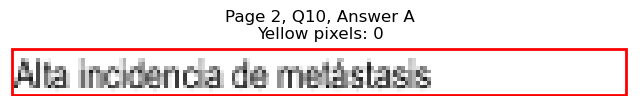

Page 2, Q10 - B: Detected box: x0=85.0, y0=723.7, x1=205.6, y1=735.8
Page 2, Q10, B: Yellow pixels: 0
Page 2, Q10, B: Total non-white pixels: 618
Page 2, Q10, B: Yellow percentage: 0.0%


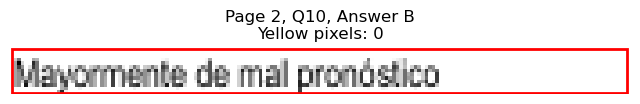

Page 2, Q10 - C: Detected box: x0=85.0, y0=735.8, x1=195.7, y1=747.9
Page 2, Q10, C: Yellow pixels: 1510
Page 2, Q10, C: Total non-white pixels: 2106
Page 2, Q10, C: Yellow percentage: 71.7%


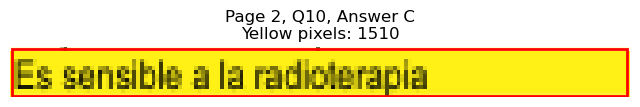

Page 2, Q10 - D: Detected box: x0=336.7, y0=711.7, x1=495.6, y1=723.8
Page 2, Q10, D: Yellow pixels: 0
Page 2, Q10, D: Total non-white pixels: 807
Page 2, Q10, D: Yellow percentage: 0.0%


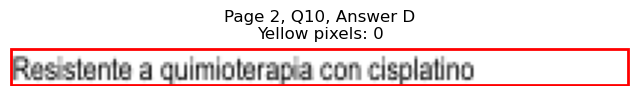

Page 2, Q10 - E: Detected box: x0=336.7, y0=723.7, x1=481.8, y1=735.8
Page 2, Q10, E: Yellow pixels: 0
Page 2, Q10, E: Total non-white pixels: 724
Page 2, Q10, E: Yellow percentage: 0.0%


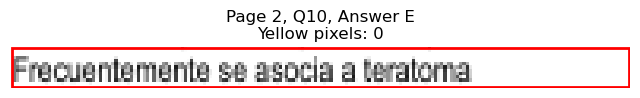


Page 2, Q10 - Selected Answer: C (based on yellow pixel count)





Page 3: Found 10 questions
Page 3, Q1 - A: Detected box: x0=85.0, y0=109.2, x1=125.7, y1=121.3
Page 3, Q1, A: Yellow pixels: 938
Page 3, Q1, A: Total non-white pixels: 1196
Page 3, Q1, A: Yellow percentage: 78.4%


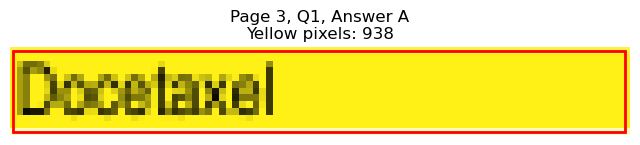

Page 3, Q1 - B: Detected box: x0=85.0, y0=121.2, x1=137.2, y1=133.3
Page 3, Q1, B: Yellow pixels: 0
Page 3, Q1, B: Total non-white pixels: 377
Page 3, Q1, B: Yellow percentage: 0.0%


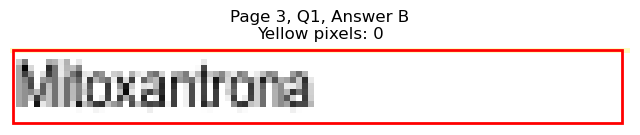

Page 3, Q1 - C: Detected box: x0=85.0, y0=133.2, x1=130.9, y1=145.3
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 236
Page 3, Q1, C: Yellow percentage: 0.0%


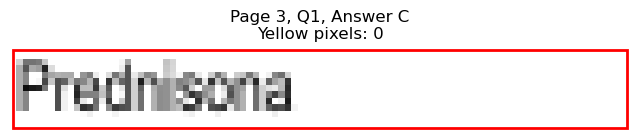

Page 3, Q1 - D: Detected box: x0=336.7, y0=109.2, x1=389.4, y1=121.3
Page 3, Q1, D: Yellow pixels: 0
Page 3, Q1, D: Total non-white pixels: 276
Page 3, Q1, D: Yellow percentage: 0.0%


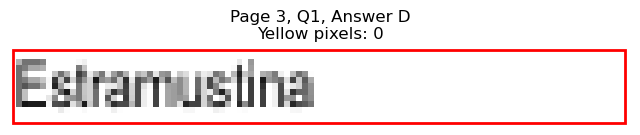

Page 3, Q1 - E: Detected box: x0=336.7, y0=121.2, x1=384.1, y1=133.3
Page 3, Q1, E: Yellow pixels: 0
Page 3, Q1, E: Total non-white pixels: 255
Page 3, Q1, E: Yellow percentage: 0.0%


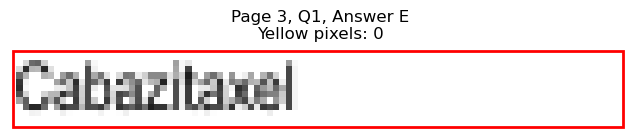


Page 3, Q1 - Selected Answer: A (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=85.0, y0=169.4, x1=175.0, y1=181.5
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 461
Page 3, Q2, A: Yellow percentage: 0.0%


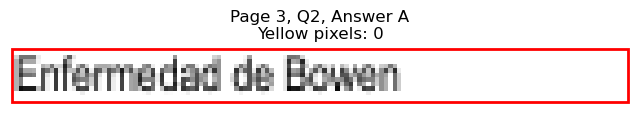

Page 3, Q2 - B: Detected box: x0=85.0, y0=181.4, x1=172.1, y1=193.5
Page 3, Q2, B: Yellow pixels: 139
Page 3, Q2, B: Total non-white pixels: 582
Page 3, Q2, B: Yellow percentage: 23.9%


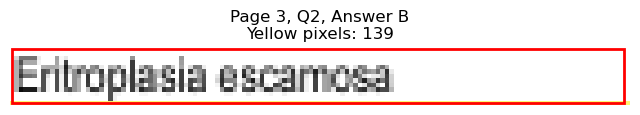

Page 3, Q2 - C: Detected box: x0=85.0, y0=193.4, x1=175.5, y1=205.5
Page 3, Q2, C: Yellow pixels: 1471
Page 3, Q2, C: Total non-white pixels: 1846
Page 3, Q2, C: Yellow percentage: 79.7%


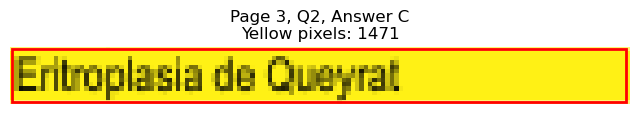

Page 3, Q2 - D: Detected box: x0=336.7, y0=169.4, x1=422.4, y1=181.5
Page 3, Q2, D: Yellow pixels: 0
Page 3, Q2, D: Total non-white pixels: 425
Page 3, Q2, D: Yellow percentage: 0.0%


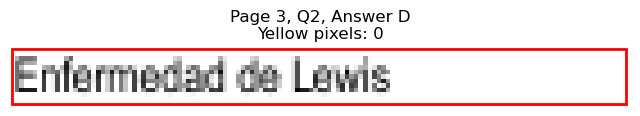

Page 3, Q2 - E: Detected box: x0=336.7, y0=181.4, x1=431.5, y1=193.5
Page 3, Q2, E: Yellow pixels: 0
Page 3, Q2, E: Total non-white pixels: 474
Page 3, Q2, E: Yellow percentage: 0.0%


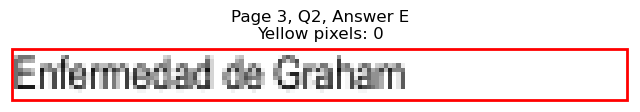


Page 3, Q2 - Selected Answer: C (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=85.0, y0=253.7, x1=163.5, y1=265.8
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 445
Page 3, Q3, A: Yellow percentage: 0.0%


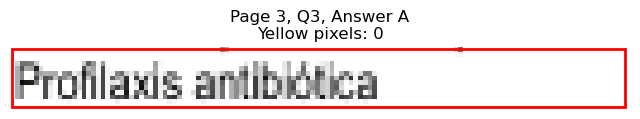

Page 3, Q3 - B: Detected box: x0=85.0, y0=265.8, x1=202.3, y1=277.9
Page 3, Q3, B: Yellow pixels: 0
Page 3, Q3, B: Total non-white pixels: 597
Page 3, Q3, B: Yellow percentage: 0.0%


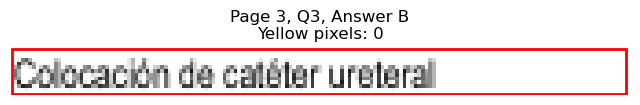

Page 3, Q3 - C: Detected box: x0=85.0, y0=277.8, x1=179.8, y1=289.9
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 495
Page 3, Q3, C: Yellow percentage: 0.0%


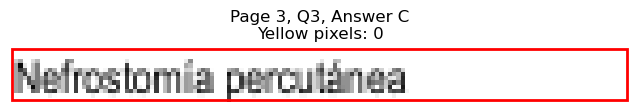

Page 3, Q3 - D: Detected box: x0=336.7, y0=253.7, x1=430.0, y1=265.8
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 500
Page 3, Q3, D: Yellow percentage: 0.0%


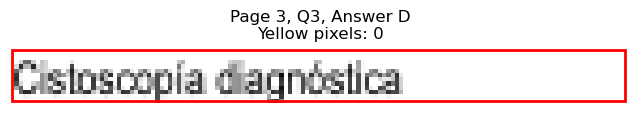

Page 3, Q3 - E: Detected box: x0=336.7, y0=265.8, x1=423.3, y1=277.9
Page 3, Q3, E: Yellow pixels: 1268
Page 3, Q3, E: Total non-white pixels: 1794
Page 3, Q3, E: Yellow percentage: 70.7%


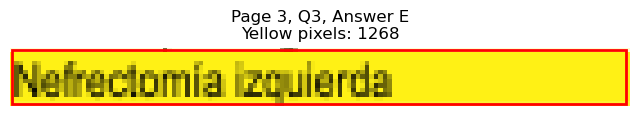


Page 3, Q3 - Selected Answer: E (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=85.0, y0=313.9, x1=362.6, y1=326.0
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 1444
Page 3, Q4, A: Yellow percentage: 0.0%


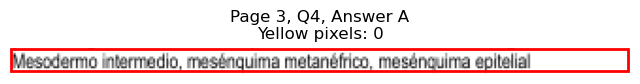

Page 3, Q4 - B: Detected box: x0=85.0, y0=326.1, x1=421.0, y1=338.2
Page 3, Q4, B: Yellow pixels: 3293
Page 3, Q4, B: Total non-white pixels: 5044
Page 3, Q4, B: Yellow percentage: 65.3%


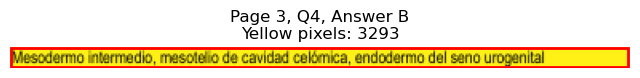

Page 3, Q4 - C: Detected box: x0=85.0, y0=338.1, x1=390.0, y1=350.2
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 1866
Page 3, Q4, C: Yellow percentage: 0.0%


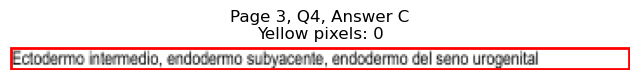

Page 3, Q4 - D: Detected box: x0=85.0, y0=350.2, x1=393.3, y1=362.3
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 1622
Page 3, Q4, D: Yellow percentage: 0.0%


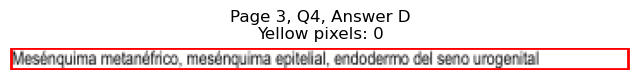

Page 3, Q4 - E: Detected box: x0=85.0, y0=362.2, x1=413.8, y1=374.3
Page 3, Q4, E: Yellow pixels: 0
Page 3, Q4, E: Total non-white pixels: 1636
Page 3, Q4, E: Yellow percentage: 0.0%


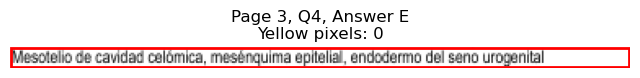


Page 3, Q4 - Selected Answer: B (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=85.0, y0=398.3, x1=163.5, y1=410.4
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 421
Page 3, Q5, A: Yellow percentage: 0.0%


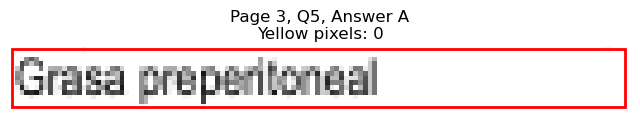

Page 3, Q5 - B: Detected box: x0=85.0, y0=410.4, x1=163.0, y1=422.5
Page 3, Q5, B: Yellow pixels: 1367
Page 3, Q5, B: Total non-white pixels: 1677
Page 3, Q5, B: Yellow percentage: 81.5%


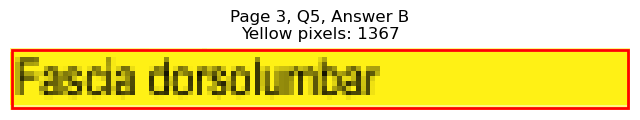

Page 3, Q5 - C: Detected box: x0=85.0, y0=422.4, x1=160.1, y1=434.5
Page 3, Q5, C: Yellow pixels: 127
Page 3, Q5, C: Total non-white pixels: 533
Page 3, Q5, C: Yellow percentage: 23.8%


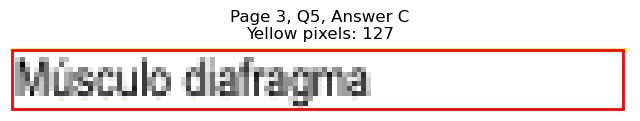

Page 3, Q5 - D: Detected box: x0=336.7, y0=398.3, x1=422.4, y1=410.4
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 439
Page 3, Q5, D: Yellow percentage: 0.0%


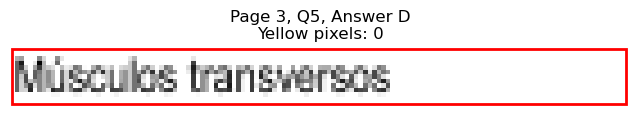

Page 3, Q5 - E: Detected box: x0=336.7, y0=410.4, x1=407.5, y1=422.5
Page 3, Q5, E: Yellow pixels: 0
Page 3, Q5, E: Total non-white pixels: 366
Page 3, Q5, E: Yellow percentage: 0.0%


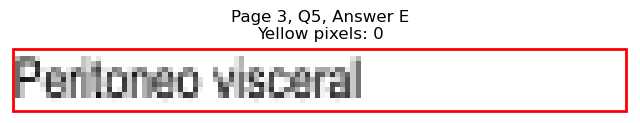


Page 3, Q5 - Selected Answer: B (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=85.0, y0=470.7, x1=124.2, y1=482.8
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 201
Page 3, Q6, A: Yellow percentage: 0.0%


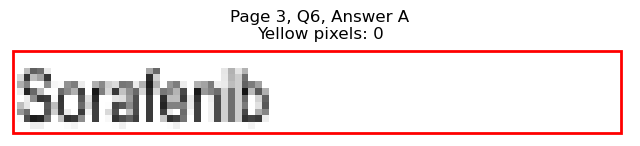

Page 3, Q6 - B: Detected box: x0=85.0, y0=482.7, x1=128.1, y1=494.8
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 223
Page 3, Q6, B: Yellow percentage: 0.0%


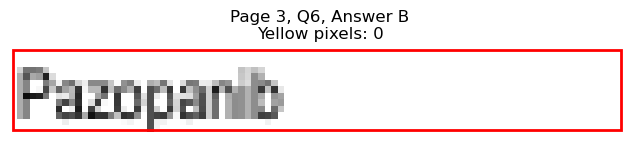

Page 3, Q6 - C: Detected box: x0=85.0, y0=494.7, x1=124.2, y1=506.8
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 196
Page 3, Q6, C: Yellow percentage: 0.0%


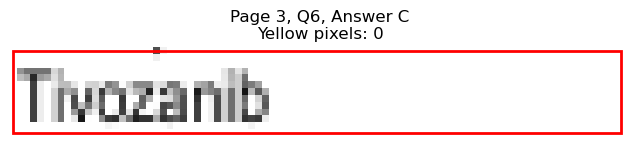

Page 3, Q6 - D: Detected box: x0=336.7, y0=470.7, x1=366.8, y1=482.8
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 249
Page 3, Q6, D: Yellow percentage: 0.0%


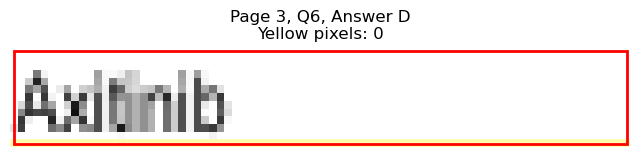

Page 3, Q6 - E: Detected box: x0=336.7, y0=482.7, x1=372.1, y1=494.8
Page 3, Q6, E: Yellow pixels: 871
Page 3, Q6, E: Total non-white pixels: 1131
Page 3, Q6, E: Yellow percentage: 77.0%


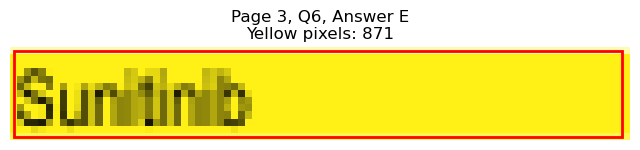


Page 3, Q6 - Selected Answer: E (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=85.0, y0=542.9, x1=147.3, y1=555.0
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 331
Page 3, Q7, A: Yellow percentage: 0.0%


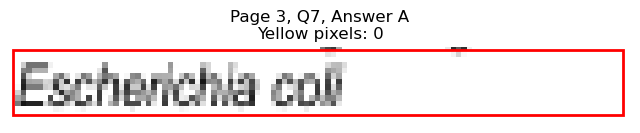

Page 3, Q7 - B: Detected box: x0=85.0, y0=554.9, x1=185.5, y1=567.0
Page 3, Q7, B: Yellow pixels: 0
Page 3, Q7, B: Total non-white pixels: 533
Page 3, Q7, B: Yellow percentage: 0.0%


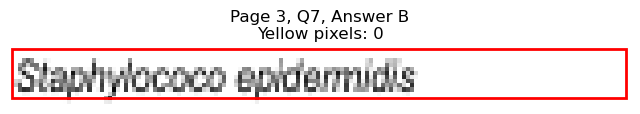

Page 3, Q7 - C: Detected box: x0=85.0, y0=567.1, x1=183.1, y1=579.2
Page 3, Q7, C: Yellow pixels: 0
Page 3, Q7, C: Total non-white pixels: 503
Page 3, Q7, C: Yellow percentage: 0.0%


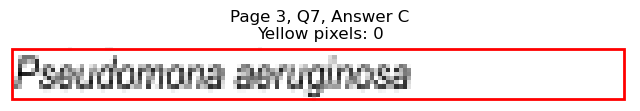

Page 3, Q7 - D: Detected box: x0=336.7, y0=542.9, x1=402.7, y1=555.0
Page 3, Q7, D: Yellow pixels: 1143
Page 3, Q7, D: Total non-white pixels: 1521
Page 3, Q7, D: Yellow percentage: 75.1%


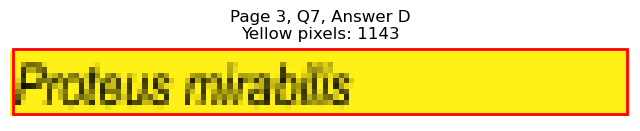

Page 3, Q7 - E: Detected box: x0=336.7, y0=554.9, x1=408.0, y1=567.0
Page 3, Q7, E: Yellow pixels: 122
Page 3, Q7, E: Total non-white pixels: 500
Page 3, Q7, E: Yellow percentage: 24.4%


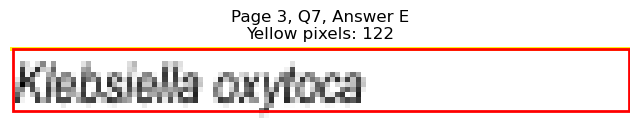


Page 3, Q7 - Selected Answer: D (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=85.0, y0=627.3, x1=151.0, y1=639.4
Page 3, Q8, A: Yellow pixels: 1107
Page 3, Q8, A: Total non-white pixels: 1521
Page 3, Q8, A: Yellow percentage: 72.8%


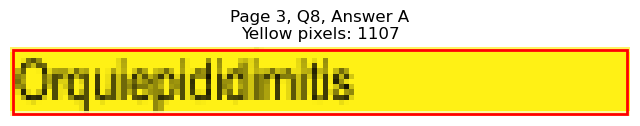

Page 3, Q8 - B: Detected box: x0=85.0, y0=639.3, x1=149.1, y1=651.4
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 441
Page 3, Q8, B: Yellow percentage: 0.0%


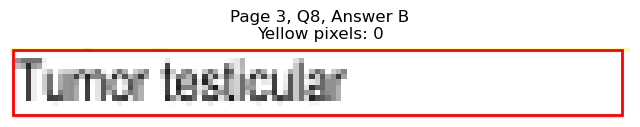

Page 3, Q8 - C: Detected box: x0=85.0, y0=651.4, x1=144.9, y1=663.5
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 314
Page 3, Q8, C: Yellow percentage: 0.0%


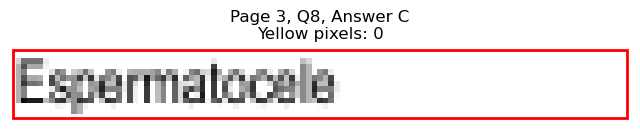

Page 3, Q8 - D: Detected box: x0=336.7, y0=627.3, x1=379.3, y1=639.4
Page 3, Q8, D: Yellow pixels: 0
Page 3, Q8, D: Total non-white pixels: 220
Page 3, Q8, D: Yellow percentage: 0.0%


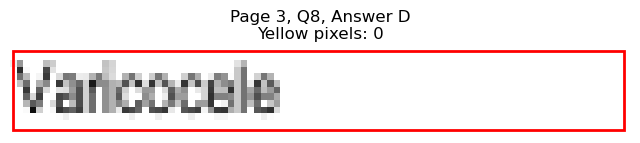

Page 3, Q8 - E: Detected box: x0=336.7, y0=639.3, x1=415.6, y1=651.4
Page 3, Q8, E: Yellow pixels: 0
Page 3, Q8, E: Total non-white pixels: 368
Page 3, Q8, E: Yellow percentage: 0.0%


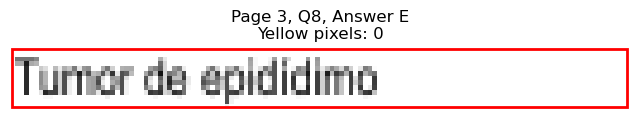


Page 3, Q8 - Selected Answer: A (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=85.0, y0=699.5, x1=210.4, y1=711.7
Page 3, Q9, A: Yellow pixels: 1764
Page 3, Q9, A: Total non-white pixels: 2301
Page 3, Q9, A: Yellow percentage: 76.7%


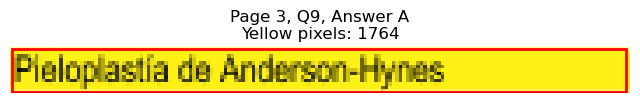

Page 3, Q9 - B: Detected box: x0=85.0, y0=711.7, x1=215.7, y1=723.8
Page 3, Q9, B: Yellow pixels: 182
Page 3, Q9, B: Total non-white pixels: 831
Page 3, Q9, B: Yellow percentage: 21.9%


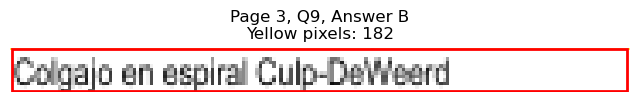

Page 3, Q9 - C: Detected box: x0=85.0, y0=723.7, x1=209.0, y1=735.8
Page 3, Q9, C: Yellow pixels: 0
Page 3, Q9, C: Total non-white pixels: 642
Page 3, Q9, C: Yellow percentage: 0.0%


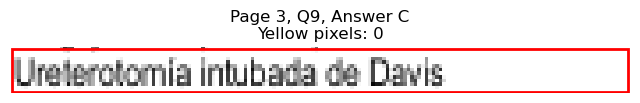

Page 3, Q9 - D: Detected box: x0=336.7, y0=699.5, x1=446.3, y1=711.7
Page 3, Q9, D: Yellow pixels: 0
Page 3, Q9, D: Total non-white pixels: 554
Page 3, Q9, D: Yellow percentage: 0.0%


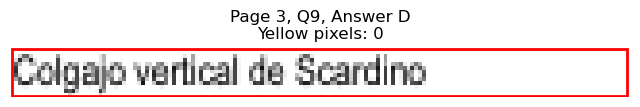

Page 3, Q9 - E: Detected box: x0=336.7, y0=711.7, x1=429.6, y1=723.8
Page 3, Q9, E: Yellow pixels: 0
Page 3, Q9, E: Total non-white pixels: 439
Page 3, Q9, E: Yellow percentage: 0.0%


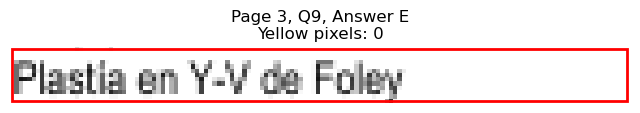


Page 3, Q9 - Selected Answer: A (based on yellow pixel count)




Page 3, Q10 - A: Detected box: x0=85.0, y0=759.8, x1=125.7, y1=771.9
Page 3, Q10, A: Yellow pixels: 942
Page 3, Q10, A: Total non-white pixels: 1196
Page 3, Q10, A: Yellow percentage: 78.8%


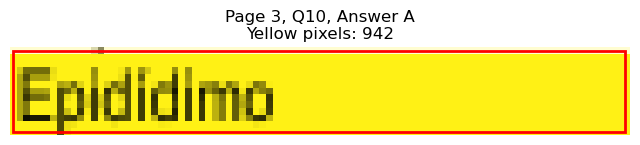

Page 3, Q10 - B: Detected box: x0=85.0, y0=771.9, x1=156.3, y1=784.0
Page 3, Q10, B: Yellow pixels: 122
Page 3, Q10, B: Total non-white pixels: 482
Page 3, Q10, B: Yellow percentage: 25.3%


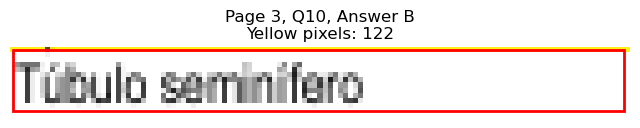

Page 3, Q10 - C: Detected box: x0=336.7, y0=759.8, x1=414.7, y1=771.9
Page 3, Q10, C: Yellow pixels: 0
Page 3, Q10, C: Total non-white pixels: 409
Page 3, Q10, C: Yellow percentage: 0.0%


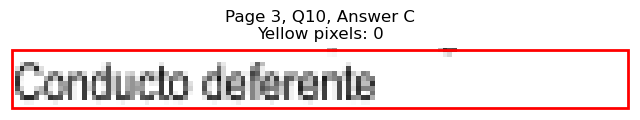

Page 3, Q10 - D: Detected box: x0=336.7, y0=771.9, x1=401.8, y1=784.0
Page 3, Q10, D: Yellow pixels: 0
Page 3, Q10, D: Total non-white pixels: 340
Page 3, Q10, D: Yellow percentage: 0.0%


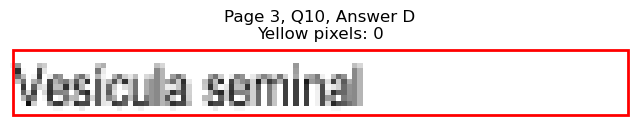


Page 3, Q10 - Selected Answer: A (based on yellow pixel count)





Page 4: Found 11 questions
Page 4, Q1 - A: Detected box: x0=85.0, y0=133.2, x1=232.5, y1=145.3
Page 4, Q1, A: Yellow pixels: 1714
Page 4, Q1, A: Total non-white pixels: 2483
Page 4, Q1, A: Yellow percentage: 69.0%


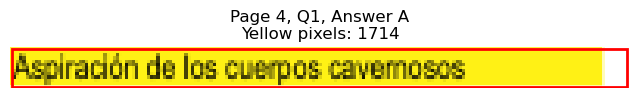

Page 4, Q1 - B: Detected box: x0=85.0, y0=145.3, x1=232.9, y1=157.4
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 931
Page 4, Q1, B: Yellow percentage: 0.0%


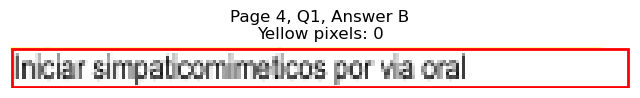

Page 4, Q1 - C: Detected box: x0=85.0, y0=157.3, x1=196.0, y1=169.4
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 591
Page 4, Q1, C: Yellow percentage: 0.0%


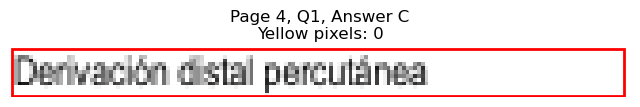

Page 4, Q1 - D: Detected box: x0=336.7, y0=133.2, x1=443.4, y1=145.3
Page 4, Q1, D: Yellow pixels: 0
Page 4, Q1, D: Total non-white pixels: 519
Page 4, Q1, D: Yellow percentage: 0.0%


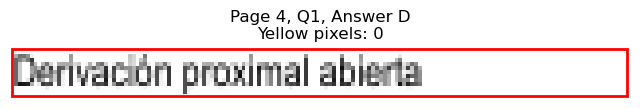

Page 4, Q1 - E: Detected box: x0=85.0, y0=85.1, x1=119.4, y1=97.2
Page 4, Q1, E: Yellow pixels: 0
Page 4, Q1, E: Total non-white pixels: 186
Page 4, Q1, E: Yellow percentage: 0.0%


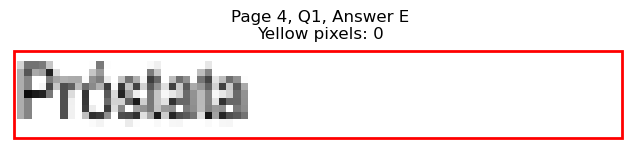


Page 4, Q1 - Selected Answer: A (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=85.0, y0=205.5, x1=150.6, y1=217.7
Page 4, Q2, A: Yellow pixels: 117
Page 4, Q2, A: Total non-white pixels: 430
Page 4, Q2, A: Yellow percentage: 27.2%


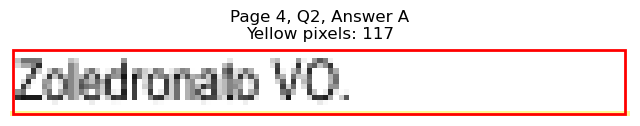

Page 4, Q2 - B: Detected box: x0=85.0, y0=217.5, x1=161.5, y1=229.7
Page 4, Q2, B: Yellow pixels: 1361
Page 4, Q2, B: Total non-white pixels: 1664
Page 4, Q2, B: Yellow percentage: 81.8%


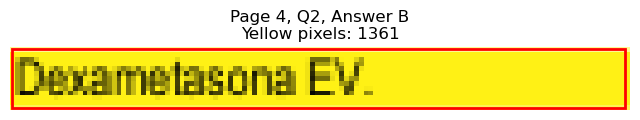

Page 4, Q2 - C: Detected box: x0=85.0, y0=229.7, x1=141.0, y1=241.8
Page 4, Q2, C: Yellow pixels: 108
Page 4, Q2, C: Total non-white pixels: 412
Page 4, Q2, C: Yellow percentage: 26.2%


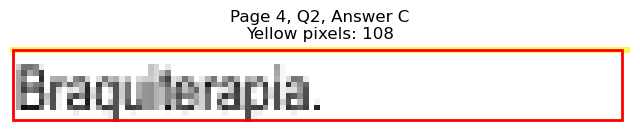

Page 4, Q2 - D: Detected box: x0=336.7, y0=205.5, x1=395.1, y1=217.7
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 317
Page 4, Q2, D: Yellow percentage: 0.0%


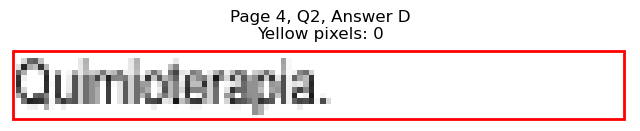

Page 4, Q2 - E: Detected box: x0=336.7, y0=145.3, x1=488.4, y1=157.4
Page 4, Q2, E: Yellow pixels: 0
Page 4, Q2, E: Total non-white pixels: 749
Page 4, Q2, E: Yellow percentage: 0.0%


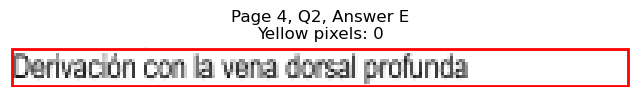


Page 4, Q2 - Selected Answer: B (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=85.0, y0=277.8, x1=130.0, y1=289.9
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 234
Page 4, Q3, A: Yellow percentage: 0.0%


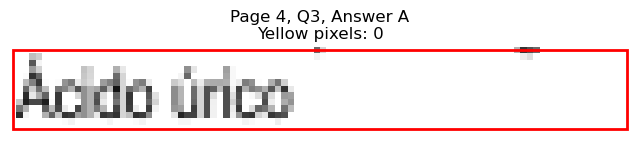

Page 4, Q3 - B: Detected box: x0=85.0, y0=289.9, x1=153.5, y1=302.0
Page 4, Q3, B: Yellow pixels: 1165
Page 4, Q3, B: Total non-white pixels: 1560
Page 4, Q3, B: Yellow percentage: 74.7%


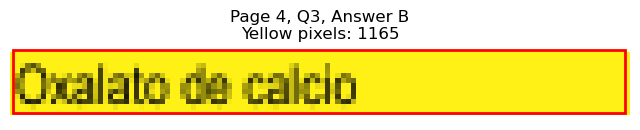

Page 4, Q3 - C: Detected box: x0=85.0, y0=301.9, x1=140.1, y1=314.0
Page 4, Q3, C: Yellow pixels: 107
Page 4, Q3, C: Total non-white pixels: 415
Page 4, Q3, C: Yellow percentage: 25.8%


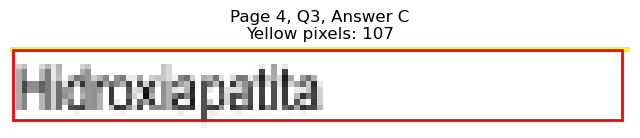

Page 4, Q3 - D: Detected box: x0=336.7, y0=277.8, x1=372.6, y1=289.9
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 193
Page 4, Q3, D: Yellow percentage: 0.0%


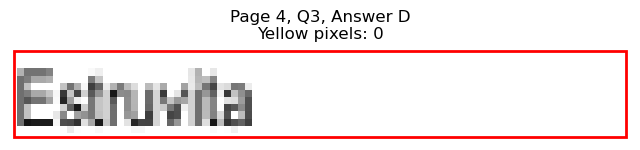

Page 4, Q3 - E: Detected box: x0=336.7, y0=217.5, x1=402.8, y1=229.7
Page 4, Q3, E: Yellow pixels: 0
Page 4, Q3, E: Total non-white pixels: 313
Page 4, Q3, E: Yellow percentage: 0.0%


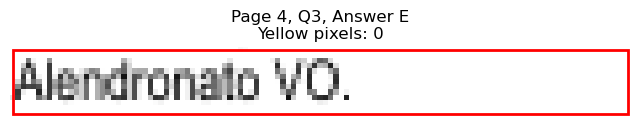


Page 4, Q3 - Selected Answer: B (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=85.0, y0=350.2, x1=189.4, y1=362.3
Page 4, Q4, A: Yellow pixels: 0
Page 4, Q4, A: Total non-white pixels: 568
Page 4, Q4, A: Yellow percentage: 0.0%


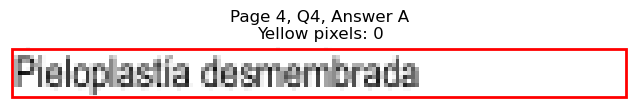

Page 4, Q4 - B: Detected box: x0=85.0, y0=362.2, x1=188.4, y1=374.3
Page 4, Q4, B: Yellow pixels: 0
Page 4, Q4, B: Total non-white pixels: 505
Page 4, Q4, B: Yellow percentage: 0.0%


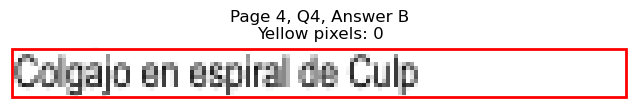

Page 4, Q4 - C: Detected box: x0=85.0, y0=374.2, x1=194.6, y1=386.3
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 582
Page 4, Q4, C: Yellow percentage: 0.0%


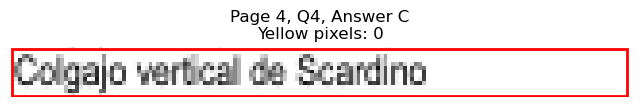

Page 4, Q4 - D: Detected box: x0=336.7, y0=350.2, x1=447.2, y1=362.3
Page 4, Q4, D: Yellow pixels: 162
Page 4, Q4, D: Total non-white pixels: 702
Page 4, Q4, D: Yellow percentage: 23.1%


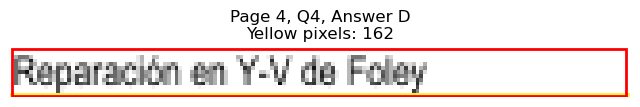

Page 4, Q4 - E: Detected box: x0=336.7, y0=289.9, x1=442.5, y1=302.0
Page 4, Q4, E: Yellow pixels: 0
Page 4, Q4, E: Total non-white pixels: 525
Page 4, Q4, E: Yellow percentage: 0.0%


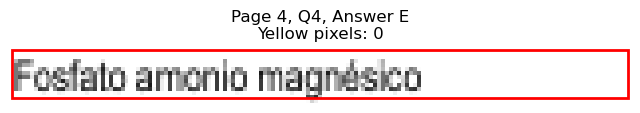


Page 4, Q4 - Selected Answer: D (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=85.0, y0=410.4, x1=152.9, y1=422.5
Page 4, Q5, A: Yellow pixels: 119
Page 4, Q5, A: Total non-white pixels: 457
Page 4, Q5, A: Yellow percentage: 26.0%


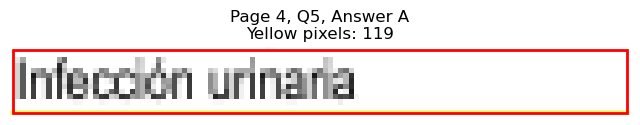

Page 4, Q5 - B: Detected box: x0=85.0, y0=422.4, x1=132.4, y1=434.5
Page 4, Q5, B: Yellow pixels: 1075
Page 4, Q5, B: Total non-white pixels: 1287
Page 4, Q5, B: Yellow percentage: 83.5%


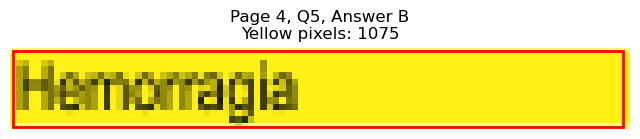

Page 4, Q5 - C: Detected box: x0=85.0, y0=434.4, x1=114.1, y1=446.5
Page 4, Q5, C: Yellow pixels: 81
Page 4, Q5, C: Total non-white pixels: 236
Page 4, Q5, C: Yellow percentage: 34.3%


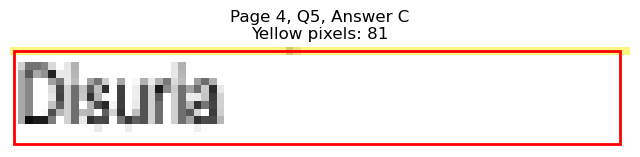

Page 4, Q5 - D: Detected box: x0=336.7, y0=410.4, x1=408.9, y1=422.5
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 382
Page 4, Q5, D: Yellow percentage: 0.0%


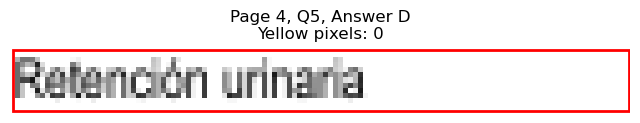

Page 4, Q5 - E: Detected box: x0=336.7, y0=362.2, x1=438.2, y1=374.3
Page 4, Q5, E: Yellow pixels: 1423
Page 4, Q5, E: Total non-white pixels: 1989
Page 4, Q5, E: Yellow percentage: 71.5%


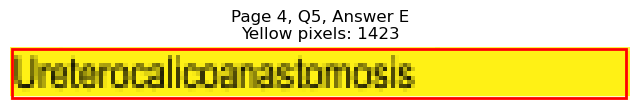


Page 4, Q5 - Selected Answer: E (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=85.0, y0=470.7, x1=178.3, y1=482.8
Page 4, Q6, A: Yellow pixels: 0
Page 4, Q6, A: Total non-white pixels: 480
Page 4, Q6, A: Yellow percentage: 0.0%


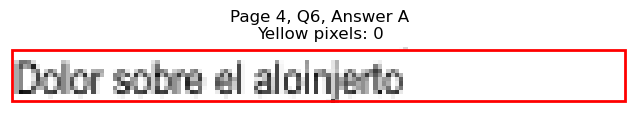

Page 4, Q6 - B: Detected box: x0=85.0, y0=482.7, x1=175.5, y1=494.8
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 634
Page 4, Q6, B: Yellow percentage: 0.0%


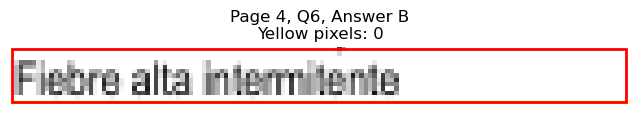

Page 4, Q6 - C: Detected box: x0=85.0, y0=494.7, x1=226.7, y1=506.8
Page 4, Q6, C: Yellow pixels: 1677
Page 4, Q6, C: Total non-white pixels: 2483
Page 4, Q6, C: Yellow percentage: 67.5%


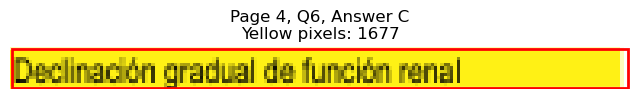

Page 4, Q6 - D: Detected box: x0=336.7, y0=470.7, x1=467.9, y1=482.8
Page 4, Q6, D: Yellow pixels: 0
Page 4, Q6, D: Total non-white pixels: 644
Page 4, Q6, D: Yellow percentage: 0.0%


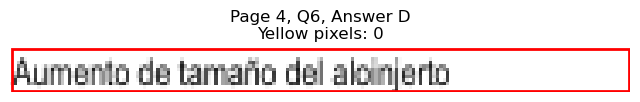

Page 4, Q6 - E: Detected box: x0=336.7, y0=422.4, x1=391.8, y1=434.5
Page 4, Q6, E: Yellow pixels: 0
Page 4, Q6, E: Total non-white pixels: 295
Page 4, Q6, E: Yellow percentage: 0.0%


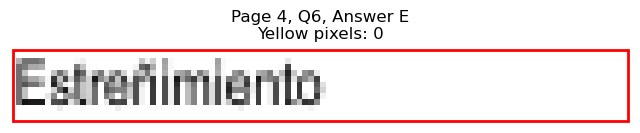


Page 4, Q6 - Selected Answer: C (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=85.0, y0=530.9, x1=169.2, y1=543.0
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 426
Page 4, Q7, A: Yellow percentage: 0.0%


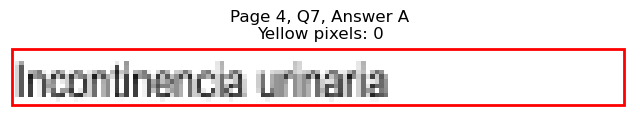

Page 4, Q7 - B: Detected box: x0=85.0, y0=542.9, x1=127.1, y1=555.0
Page 4, Q7, B: Yellow pixels: 0
Page 4, Q7, B: Total non-white pixels: 224
Page 4, Q7, B: Yellow percentage: 0.0%


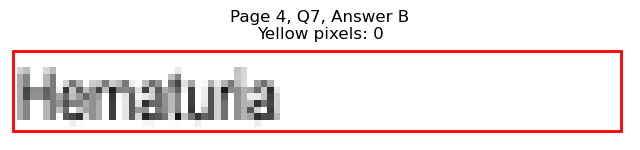

Page 4, Q7 - C: Detected box: x0=85.0, y0=554.9, x1=157.2, y1=567.0
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 375
Page 4, Q7, C: Yellow percentage: 0.0%


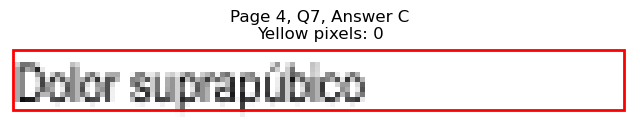

Page 4, Q7 - D: Detected box: x0=336.7, y0=530.9, x1=383.6, y1=543.0
Page 4, Q7, D: Yellow pixels: 986
Page 4, Q7, D: Total non-white pixels: 1274
Page 4, Q7, D: Yellow percentage: 77.4%


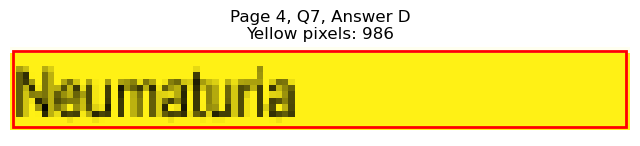

Page 4, Q7 - E: Detected box: x0=336.7, y0=482.7, x1=426.7, y1=494.8
Page 4, Q7, E: Yellow pixels: 0
Page 4, Q7, E: Total non-white pixels: 471
Page 4, Q7, E: Yellow percentage: 0.0%


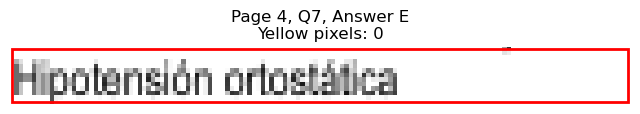


Page 4, Q7 - Selected Answer: D (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=85.0, y0=615.2, x1=153.9, y1=627.3
Page 4, Q8, A: Yellow pixels: 1164
Page 4, Q8, A: Total non-white pixels: 1560
Page 4, Q8, A: Yellow percentage: 74.6%


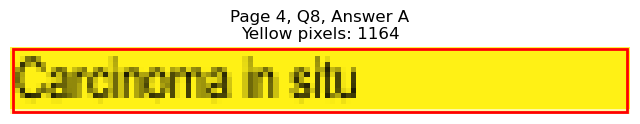

Page 4, Q8 - B: Detected box: x0=85.0, y0=627.3, x1=142.9, y1=639.4
Page 4, Q8, B: Yellow pixels: 0
Page 4, Q8, B: Total non-white pixels: 437
Page 4, Q8, B: Yellow percentage: 0.0%


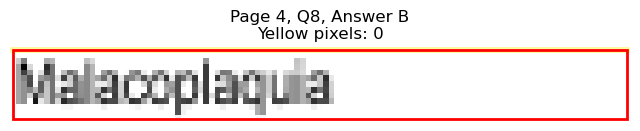

Page 4, Q8 - C: Detected box: x0=85.0, y0=639.3, x1=153.4, y1=651.4
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 386
Page 4, Q8, C: Yellow percentage: 0.0%


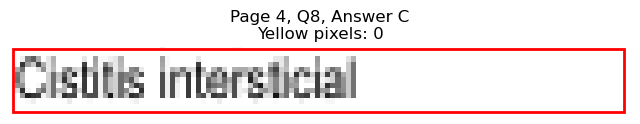

Page 4, Q8 - D: Detected box: x0=336.7, y0=615.2, x1=396.6, y1=627.3
Page 4, Q8, D: Yellow pixels: 0
Page 4, Q8, D: Total non-white pixels: 310
Page 4, Q8, D: Yellow percentage: 0.0%


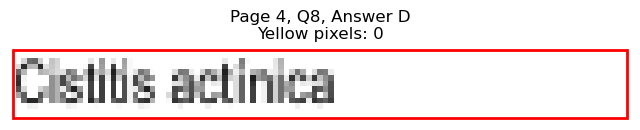

Page 4, Q8 - E: Detected box: x0=336.7, y0=542.9, x1=382.2, y1=555.0
Page 4, Q8, E: Yellow pixels: 97
Page 4, Q8, E: Total non-white pixels: 332
Page 4, Q8, E: Yellow percentage: 29.2%


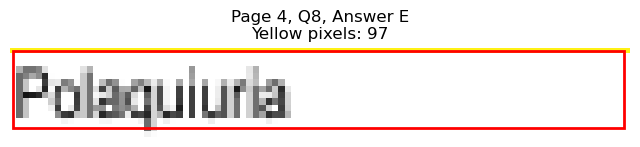


Page 4, Q8 - Selected Answer: A (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=85.0, y0=675.4, x1=144.9, y1=687.5
Page 4, Q9, A: Yellow pixels: 0
Page 4, Q9, A: Total non-white pixels: 281
Page 4, Q9, A: Yellow percentage: 0.0%


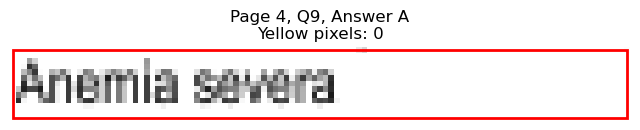

Page 4, Q9 - B: Detected box: x0=85.0, y0=687.5, x1=134.8, y1=699.7
Page 4, Q9, B: Yellow pixels: 0
Page 4, Q9, B: Total non-white pixels: 252
Page 4, Q9, B: Yellow percentage: 0.0%


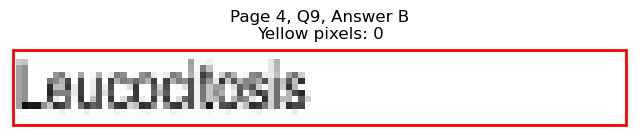

Page 4, Q9 - C: Detected box: x0=85.0, y0=699.5, x1=151.5, y1=711.7
Page 4, Q9, C: Yellow pixels: 0
Page 4, Q9, C: Total non-white pixels: 344
Page 4, Q9, C: Yellow percentage: 0.0%


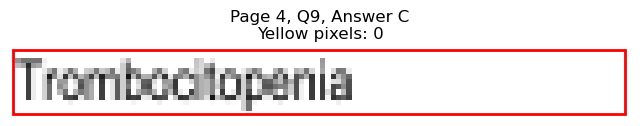

Page 4, Q9 - D: Detected box: x0=336.7, y0=675.4, x1=380.7, y1=687.5
Page 4, Q9, D: Yellow pixels: 0
Page 4, Q9, D: Total non-white pixels: 235
Page 4, Q9, D: Yellow percentage: 0.0%


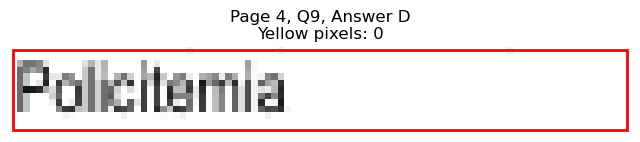

Page 4, Q9 - E: Detected box: x0=336.7, y0=627.3, x1=416.6, y1=639.4
Page 4, Q9, E: Yellow pixels: 0
Page 4, Q9, E: Total non-white pixels: 389
Page 4, Q9, E: Yellow percentage: 0.0%


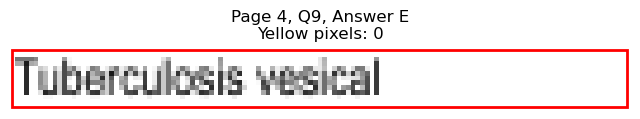

Page 4, Q10 - A: Detected box: x0=85.0, y0=735.8, x1=102.3, y1=747.9
Page 4, Q10, A: Yellow pixels: 765
Page 4, Q10, A: Total non-white pixels: 897
Page 4, Q10, A: Yellow percentage: 85.3%


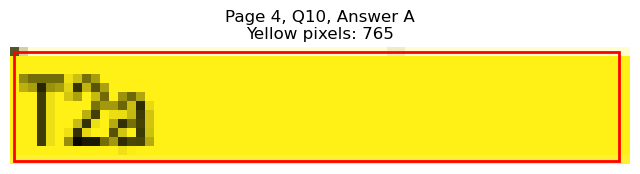

Page 4, Q10 - B: Detected box: x0=85.0, y0=747.8, x1=101.8, y1=759.9
Page 4, Q10, B: Yellow pixels: 68
Page 4, Q10, B: Total non-white pixels: 134
Page 4, Q10, B: Yellow percentage: 50.7%


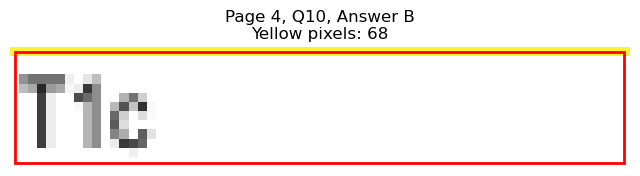

Page 4, Q10 - C: Detected box: x0=85.0, y0=759.8, x1=102.3, y1=771.9
Page 4, Q10, C: Yellow pixels: 0
Page 4, Q10, C: Total non-white pixels: 80
Page 4, Q10, C: Yellow percentage: 0.0%


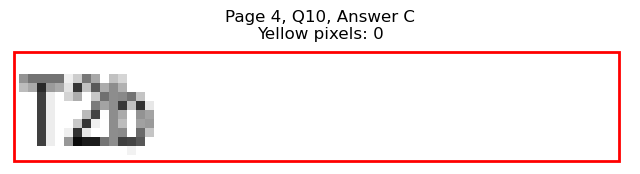

Page 4, Q10 - D: Detected box: x0=336.7, y0=735.8, x1=354.0, y1=747.9
Page 4, Q10, D: Yellow pixels: 0
Page 4, Q10, D: Total non-white pixels: 71
Page 4, Q10, D: Yellow percentage: 0.0%


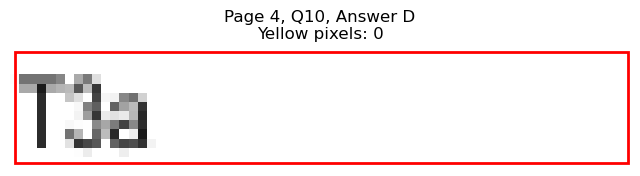

Page 4, Q10 - E: Detected box: x0=336.7, y0=687.5, x1=396.1, y1=699.7
Page 4, Q10, E: Yellow pixels: 1188
Page 4, Q10, E: Total non-white pixels: 1443
Page 4, Q10, E: Yellow percentage: 82.3%


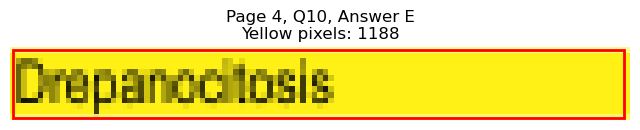


Page 4, Q10 - Selected Answer: E (based on yellow pixel count)




Page 4, Q11 - E: Detected box: x0=336.7, y0=747.8, x1=351.6, y1=759.9
Page 4, Q11, E: Yellow pixels: 0
Page 4, Q11, E: Total non-white pixels: 63
Page 4, Q11, E: Yellow percentage: 0.0%


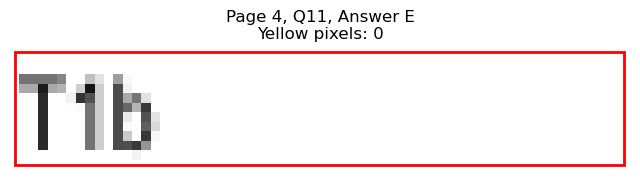


Page 5: Found 11 questions
Page 5, Q1 - A: Detected box: x0=70.8, y0=109.2, x1=79.0, y1=121.3
Page 5, Q1, A: Yellow pixels: 0
Page 5, Q1, A: Total non-white pixels: 51
Page 5, Q1, A: Yellow percentage: 0.0%


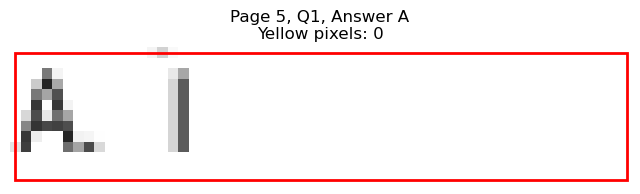

Page 5, Q1 - B: Detected box: x0=85.0, y0=121.2, x1=97.5, y1=133.3
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 60
Page 5, Q1, B: Yellow percentage: 0.0%


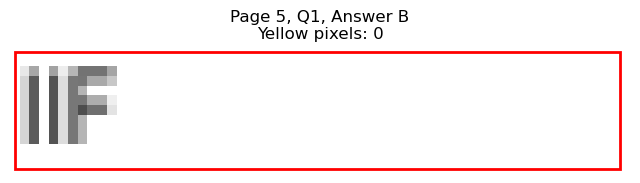

Page 5, Q1 - C: Detected box: x0=85.0, y0=133.2, x1=94.6, y1=145.3
Page 5, Q1, C: Yellow pixels: 0
Page 5, Q1, C: Total non-white pixels: 48
Page 5, Q1, C: Yellow percentage: 0.0%


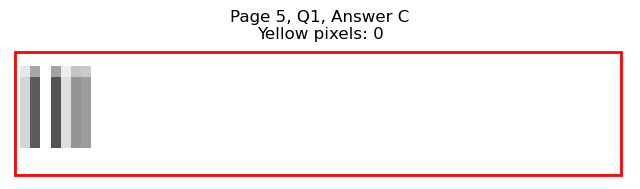

Page 5, Q1 - D: Detected box: x0=322.5, y0=109.2, x1=331.2, y1=121.3
Page 5, Q1, D: Yellow pixels: 661
Page 5, Q1, D: Total non-white pixels: 780
Page 5, Q1, D: Yellow percentage: 84.7%


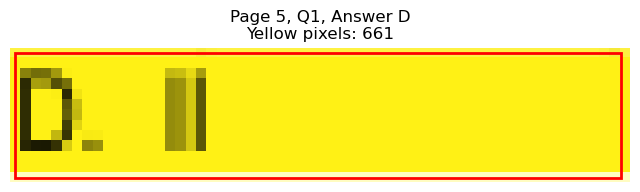

Page 5, Q1 - E: Detected box: x0=336.7, y0=121.2, x1=347.2, y1=133.3
Page 5, Q1, E: Yellow pixels: 0
Page 5, Q1, E: Total non-white pixels: 106
Page 5, Q1, E: Yellow percentage: 0.0%


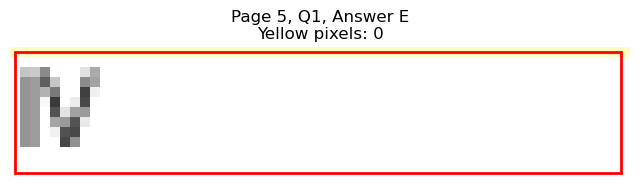


Page 5, Q1 - Selected Answer: D (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=183.1, y1=193.5
Page 5, Q2, A: Yellow pixels: 1543
Page 5, Q2, A: Total non-white pixels: 1950
Page 5, Q2, A: Yellow percentage: 79.1%


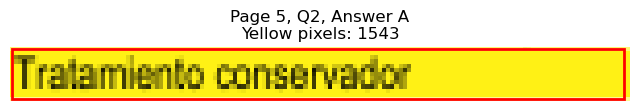

Page 5, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=202.3, y1=205.5
Page 5, Q2, B: Yellow pixels: 169
Page 5, Q2, B: Total non-white pixels: 762
Page 5, Q2, B: Yellow percentage: 22.2%


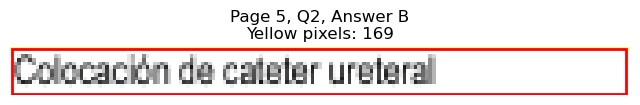

Page 5, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=175.0, y1=217.7
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 495
Page 5, Q2, C: Yellow percentage: 0.0%


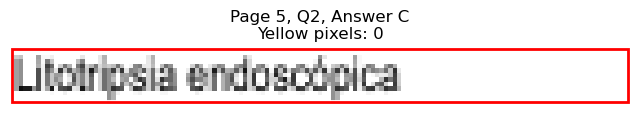

Page 5, Q2 - D: Detected box: x0=336.7, y0=181.4, x1=431.5, y1=193.5
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 482
Page 5, Q2, D: Yellow percentage: 0.0%


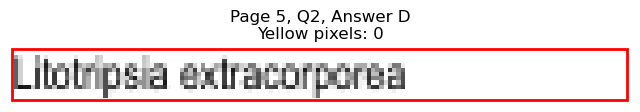

Page 5, Q2 - E: Detected box: x0=336.7, y0=193.4, x1=431.5, y1=205.5
Page 5, Q2, E: Yellow pixels: 0
Page 5, Q2, E: Total non-white pixels: 502
Page 5, Q2, E: Yellow percentage: 0.0%


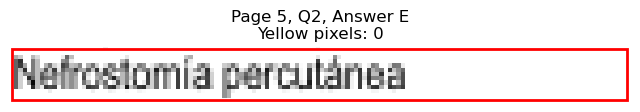


Page 5, Q2 - Selected Answer: A (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=85.0, y0=241.7, x1=150.0, y1=253.8
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 307
Page 5, Q3, A: Yellow percentage: 0.0%


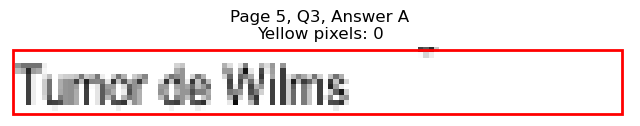

Page 5, Q3 - B: Detected box: x0=85.0, y0=253.7, x1=166.3, y1=265.8
Page 5, Q3, B: Yellow pixels: 0
Page 5, Q3, B: Total non-white pixels: 442
Page 5, Q3, B: Yellow percentage: 0.0%


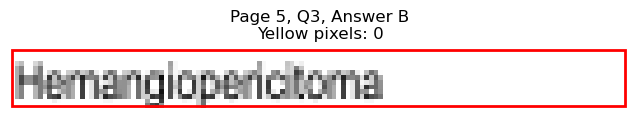

Page 5, Q3 - C: Detected box: x0=85.0, y0=265.8, x1=121.8, y1=277.9
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 183
Page 5, Q3, C: Yellow percentage: 0.0%


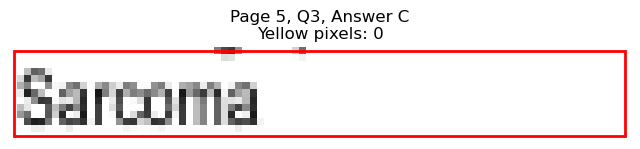

Page 5, Q3 - D: Detected box: x0=336.7, y0=241.7, x1=385.0, y1=253.8
Page 5, Q3, D: Yellow pixels: 1014
Page 5, Q3, D: Total non-white pixels: 1300
Page 5, Q3, D: Yellow percentage: 78.0%


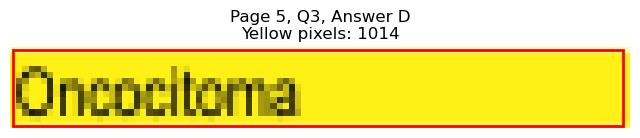

Page 5, Q3 - E: Detected box: x0=336.7, y0=253.7, x1=403.8, y1=265.8
Page 5, Q3, E: Yellow pixels: 118
Page 5, Q3, E: Total non-white pixels: 448
Page 5, Q3, E: Yellow percentage: 26.3%


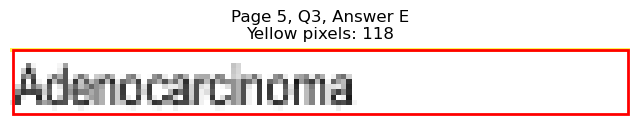


Page 5, Q3 - Selected Answer: D (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=85.0, y0=313.9, x1=166.8, y1=326.0
Page 5, Q4, A: Yellow pixels: 0
Page 5, Q4, A: Total non-white pixels: 422
Page 5, Q4, A: Yellow percentage: 0.0%


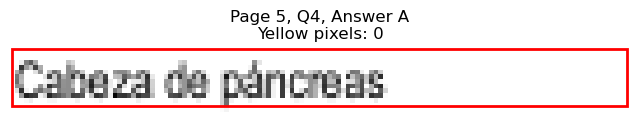

Page 5, Q4 - B: Detected box: x0=85.0, y0=326.1, x1=161.5, y1=338.2
Page 5, Q4, B: Yellow pixels: 0
Page 5, Q4, B: Total non-white pixels: 386
Page 5, Q4, B: Yellow percentage: 0.0%


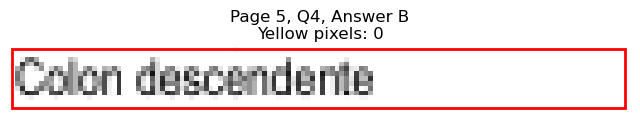

Page 5, Q4 - C: Detected box: x0=85.0, y0=338.1, x1=167.8, y1=350.2
Page 5, Q4, C: Yellow pixels: 0
Page 5, Q4, C: Total non-white pixels: 428
Page 5, Q4, C: Yellow percentage: 0.0%


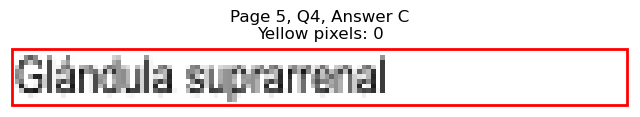

Page 5, Q4 - D: Detected box: x0=336.7, y0=313.9, x1=440.1, y1=326.0
Page 5, Q4, D: Yellow pixels: 1433
Page 5, Q4, D: Total non-white pixels: 2170
Page 5, Q4, D: Yellow percentage: 66.0%


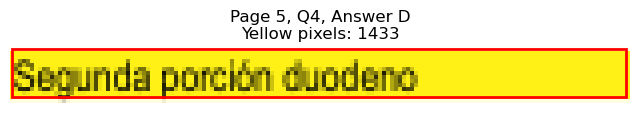

Page 5, Q4 - E: Detected box: x0=336.7, y0=326.1, x1=423.8, y1=338.2
Page 5, Q4, E: Yellow pixels: 0
Page 5, Q4, E: Total non-white pixels: 594
Page 5, Q4, E: Yellow percentage: 0.0%


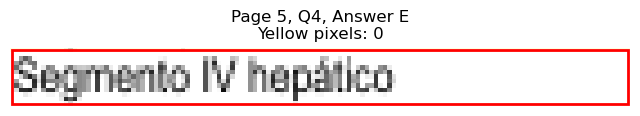


Page 5, Q4 - Selected Answer: D (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=85.0, y0=374.2, x1=124.2, y1=386.3
Page 5, Q5, A: Yellow pixels: 933
Page 5, Q5, A: Total non-white pixels: 1183
Page 5, Q5, A: Yellow percentage: 78.9%


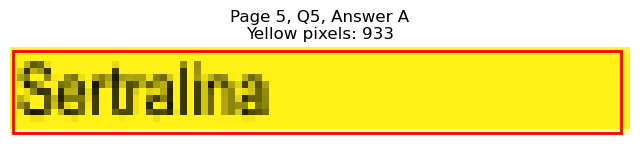

Page 5, Q5 - B: Detected box: x0=85.0, y0=386.3, x1=124.7, y1=398.4
Page 5, Q5, B: Yellow pixels: 0
Page 5, Q5, B: Total non-white pixels: 312
Page 5, Q5, B: Yellow percentage: 0.0%


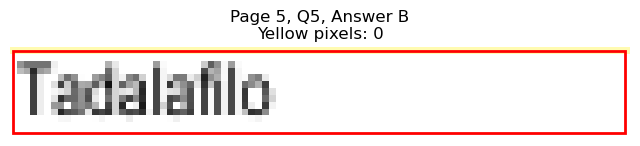

Page 5, Q5 - C: Detected box: x0=85.0, y0=398.3, x1=131.9, y1=410.4
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 270
Page 5, Q5, C: Yellow percentage: 0.0%


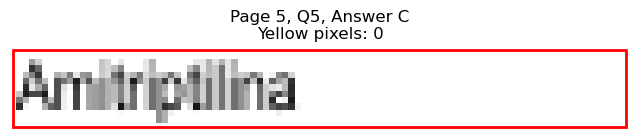

Page 5, Q5 - D: Detected box: x0=336.7, y0=374.2, x1=385.0, y1=386.3
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 271
Page 5, Q5, D: Yellow percentage: 0.0%


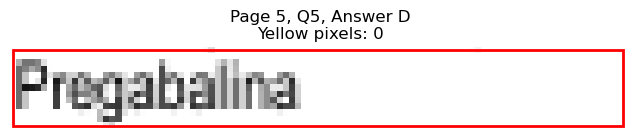

Page 5, Q5 - E: Detected box: x0=336.7, y0=386.3, x1=379.3, y1=398.4
Page 5, Q5, E: Yellow pixels: 0
Page 5, Q5, E: Total non-white pixels: 238
Page 5, Q5, E: Yellow percentage: 0.0%


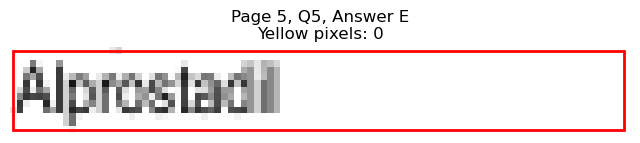


Page 5, Q5 - Selected Answer: A (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=85.0, y0=434.4, x1=110.9, y1=446.5
Page 5, Q6, A: Yellow pixels: 0
Page 5, Q6, A: Total non-white pixels: 98
Page 5, Q6, A: Yellow percentage: 0.0%


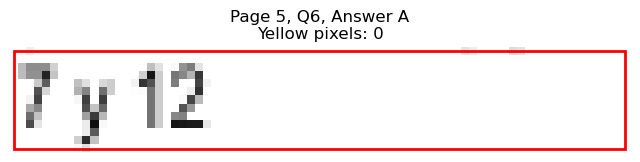

Page 5, Q6 - B: Detected box: x0=85.0, y0=446.6, x1=115.6, y1=458.7
Page 5, Q6, B: Yellow pixels: 983
Page 5, Q6, B: Total non-white pixels: 1066
Page 5, Q6, B: Yellow percentage: 92.2%


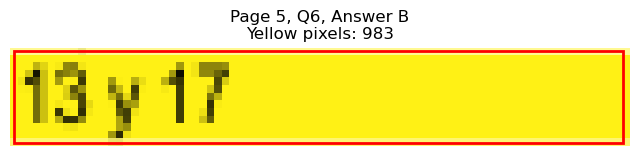

Page 5, Q6 - C: Detected box: x0=85.0, y0=458.6, x1=106.1, y1=470.7
Page 5, Q6, C: Yellow pixels: 73
Page 5, Q6, C: Total non-white pixels: 152
Page 5, Q6, C: Yellow percentage: 48.0%


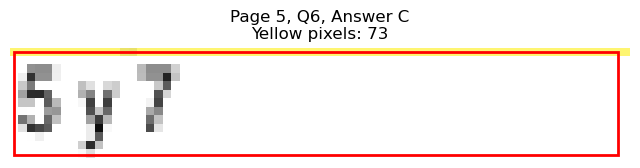

Page 5, Q6 - D: Detected box: x0=336.7, y0=434.4, x1=367.3, y1=446.5
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 112
Page 5, Q6, D: Yellow percentage: 0.0%


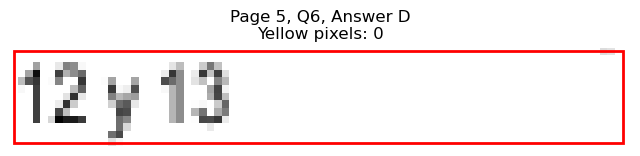

Page 5, Q6 - E: Detected box: x0=336.7, y0=446.6, x1=362.6, y1=458.7
Page 5, Q6, E: Yellow pixels: 0
Page 5, Q6, E: Total non-white pixels: 105
Page 5, Q6, E: Yellow percentage: 0.0%


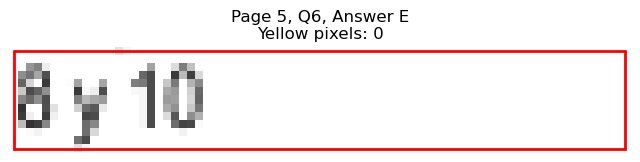


Page 5, Q6 - Selected Answer: B (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=85.0, y0=494.7, x1=119.9, y1=506.8
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 188
Page 5, Q7, A: Yellow percentage: 0.0%


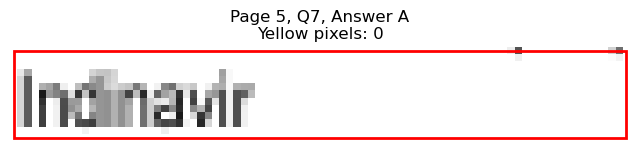

Page 5, Q7 - B: Detected box: x0=85.0, y0=506.8, x1=133.8, y1=518.9
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 351
Page 5, Q7, B: Yellow percentage: 0.0%


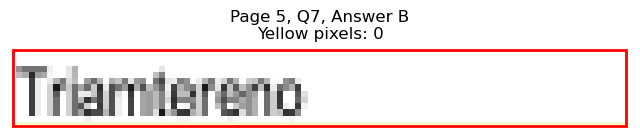

Page 5, Q7 - C: Detected box: x0=85.0, y0=518.8, x1=143.9, y1=530.9
Page 5, Q7, C: Yellow pixels: 1055
Page 5, Q7, C: Total non-white pixels: 1430
Page 5, Q7, C: Yellow percentage: 73.8%


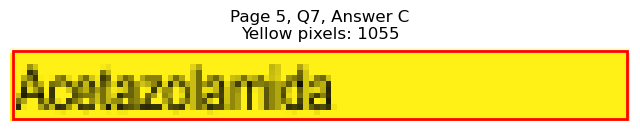

Page 5, Q7 - D: Detected box: x0=336.7, y0=494.7, x1=371.1, y1=506.8
Page 5, Q7, D: Yellow pixels: 0
Page 5, Q7, D: Total non-white pixels: 178
Page 5, Q7, D: Yellow percentage: 0.0%


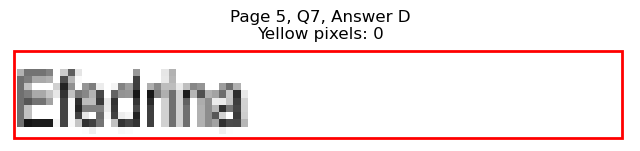

Page 5, Q7 - E: Detected box: x0=336.7, y0=506.8, x1=389.8, y1=518.9
Page 5, Q7, E: Yellow pixels: 0
Page 5, Q7, E: Total non-white pixels: 288
Page 5, Q7, E: Yellow percentage: 0.0%


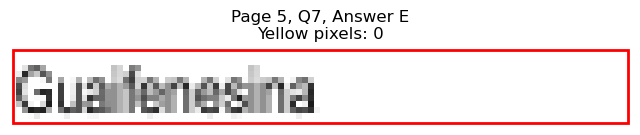


Page 5, Q7 - Selected Answer: C (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=85.0, y0=554.9, x1=128.1, y1=567.0
Page 5, Q8, A: Yellow pixels: 0
Page 5, Q8, A: Total non-white pixels: 260
Page 5, Q8, A: Yellow percentage: 0.0%


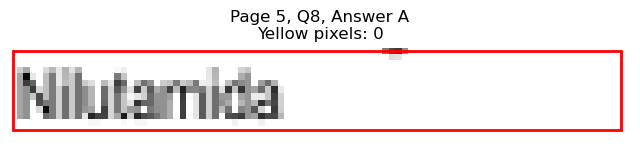

Page 5, Q8 - B: Detected box: x0=85.0, y0=567.1, x1=139.6, y1=579.2
Page 5, Q8, B: Yellow pixels: 0
Page 5, Q8, B: Total non-white pixels: 274
Page 5, Q8, B: Yellow percentage: 0.0%


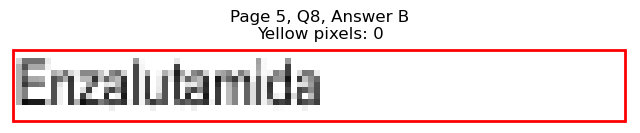

Page 5, Q8 - C: Detected box: x0=85.0, y0=579.1, x1=131.9, y1=591.2
Page 5, Q8, C: Yellow pixels: 0
Page 5, Q8, C: Total non-white pixels: 253
Page 5, Q8, C: Yellow percentage: 0.0%


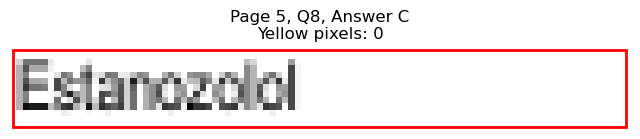

Page 5, Q8 - D: Detected box: x0=336.7, y0=554.9, x1=381.7, y1=567.0
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 239
Page 5, Q8, D: Yellow percentage: 0.0%


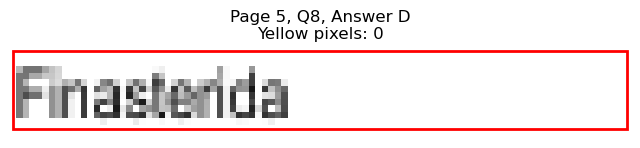

Page 5, Q8 - E: Detected box: x0=336.7, y0=567.1, x1=382.2, y1=579.2
Page 5, Q8, E: Yellow pixels: 976
Page 5, Q8, E: Total non-white pixels: 1261
Page 5, Q8, E: Yellow percentage: 77.4%


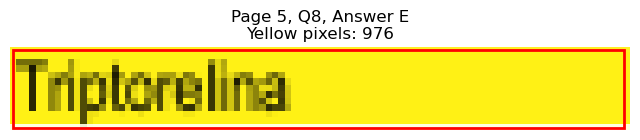


Page 5, Q8 - Selected Answer: E (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=85.0, y0=615.2, x1=126.6, y1=627.3
Page 5, Q9, A: Yellow pixels: 0
Page 5, Q9, A: Total non-white pixels: 253
Page 5, Q9, A: Yellow percentage: 0.0%


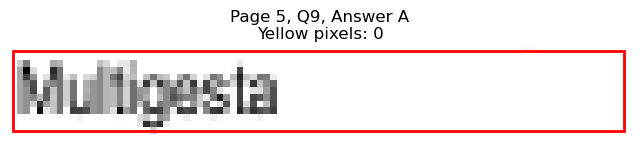

Page 5, Q9 - B: Detected box: x0=85.0, y0=627.3, x1=152.1, y1=639.4
Page 5, Q9, B: Yellow pixels: 0
Page 5, Q9, B: Total non-white pixels: 345
Page 5, Q9, B: Yellow percentage: 0.0%


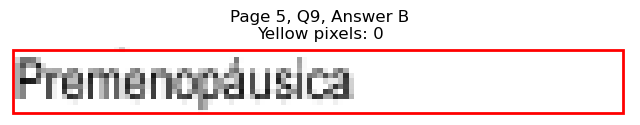

Page 5, Q9 - C: Detected box: x0=85.0, y0=639.3, x1=139.1, y1=651.4
Page 5, Q9, C: Yellow pixels: 0
Page 5, Q9, C: Total non-white pixels: 276
Page 5, Q9, C: Yellow percentage: 0.0%


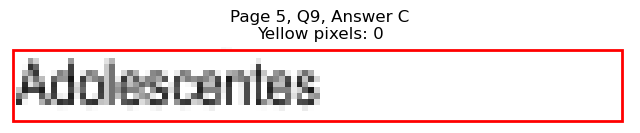

Page 5, Q9 - D: Detected box: x0=336.7, y0=615.2, x1=379.8, y1=627.3
Page 5, Q9, D: Yellow pixels: 0
Page 5, Q9, D: Total non-white pixels: 225
Page 5, Q9, D: Yellow percentage: 0.0%


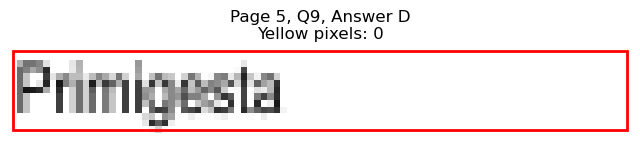

Page 5, Q9 - E: Detected box: x0=336.7, y0=627.3, x1=405.2, y1=639.4
Page 5, Q9, E: Yellow pixels: 1164
Page 5, Q9, E: Total non-white pixels: 1560
Page 5, Q9, E: Yellow percentage: 74.6%


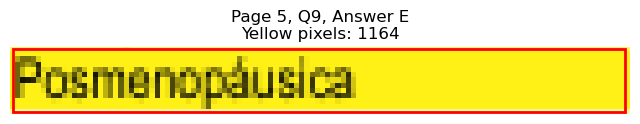


Page 5, Q9 - Selected Answer: E (based on yellow pixel count)




Page 5, Q10 - A: Detected box: x0=85.0, y0=675.4, x1=191.3, y1=687.5
Page 5, Q10, A: Yellow pixels: 0
Page 5, Q10, A: Total non-white pixels: 497
Page 5, Q10, A: Yellow percentage: 0.0%


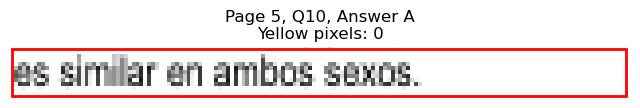

Page 5, Q10 - B: Detected box: x0=85.0, y0=687.5, x1=200.8, y1=699.7
Page 5, Q10, B: Yellow pixels: 1733
Page 5, Q10, B: Total non-white pixels: 2171
Page 5, Q10, B: Yellow percentage: 79.8%


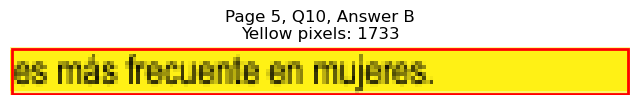

Page 5, Q10 - C: Detected box: x0=85.0, y0=699.5, x1=189.4, y1=711.7
Page 5, Q10, C: Yellow pixels: 156
Page 5, Q10, C: Total non-white pixels: 672
Page 5, Q10, C: Yellow percentage: 23.2%


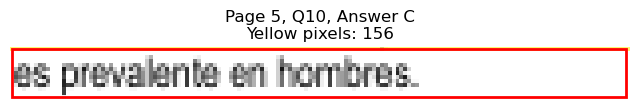

Page 5, Q10 - D: Detected box: x0=336.7, y0=675.4, x1=442.5, y1=687.5
Page 5, Q10, D: Yellow pixels: 0
Page 5, Q10, D: Total non-white pixels: 508
Page 5, Q10, D: Yellow percentage: 0.0%


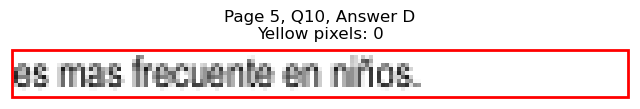

Page 5, Q10 - E: Detected box: x0=336.7, y0=687.5, x1=496.5, y1=699.7
Page 5, Q10, E: Yellow pixels: 0
Page 5, Q10, E: Total non-white pixels: 774
Page 5, Q10, E: Yellow percentage: 0.0%


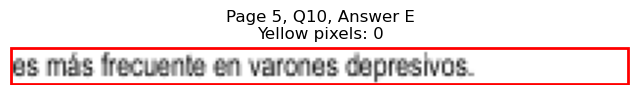


Page 5, Q10 - Selected Answer: B (based on yellow pixel count)




Page 5, Q11 - A: Detected box: x0=85.0, y0=735.8, x1=127.1, y1=747.9
Page 5, Q11, A: Yellow pixels: 0
Page 5, Q11, A: Total non-white pixels: 304
Page 5, Q11, A: Yellow percentage: 0.0%


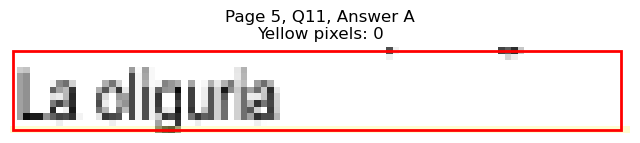

Page 5, Q11 - B: Detected box: x0=85.0, y0=747.8, x1=158.2, y1=759.9
Page 5, Q11, B: Yellow pixels: 1197
Page 5, Q11, B: Total non-white pixels: 1625
Page 5, Q11, B: Yellow percentage: 73.7%


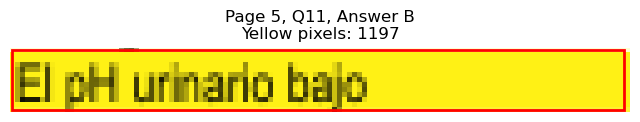

Page 5, Q11 - C: Detected box: x0=85.0, y0=759.8, x1=155.8, y1=771.9
Page 5, Q11, C: Yellow pixels: 118
Page 5, Q11, C: Total non-white pixels: 481
Page 5, Q11, C: Yellow percentage: 24.5%


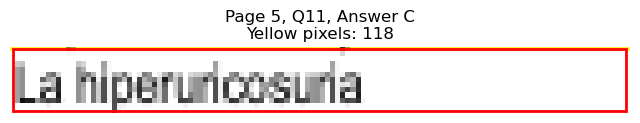

Page 5, Q11 - D: Detected box: x0=336.7, y0=735.8, x1=435.8, y1=747.9
Page 5, Q11, D: Yellow pixels: 0
Page 5, Q11, D: Total non-white pixels: 495
Page 5, Q11, D: Yellow percentage: 0.0%


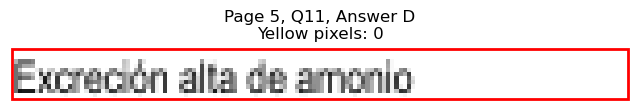

Page 5, Q11 - E: Detected box: x0=336.7, y0=747.8, x1=400.4, y1=759.9
Page 5, Q11, E: Yellow pixels: 0
Page 5, Q11, E: Total non-white pixels: 298
Page 5, Q11, E: Yellow percentage: 0.0%


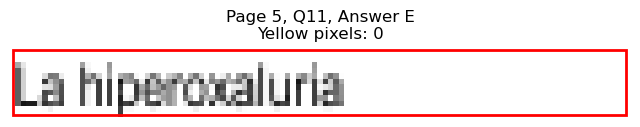


Page 5, Q11 - Selected Answer: B (based on yellow pixel count)





Page 6: Found 10 questions
Page 6, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=125.7, y1=109.2
Page 6, Q1, A: Yellow pixels: 0
Page 6, Q1, A: Total non-white pixels: 233
Page 6, Q1, A: Yellow percentage: 0.0%


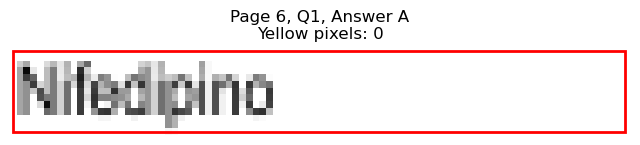

Page 6, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=132.4, y1=121.3
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 236
Page 6, Q1, B: Yellow percentage: 0.0%


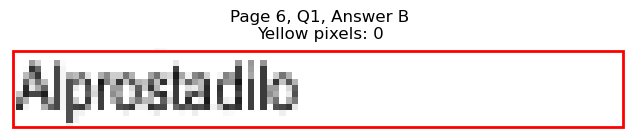

Page 6, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=131.4, y1=133.3
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 226
Page 6, Q1, C: Yellow percentage: 0.0%


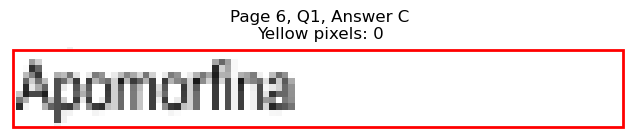

Page 6, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=386.5, y1=109.2
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 251
Page 6, Q1, D: Yellow percentage: 0.0%


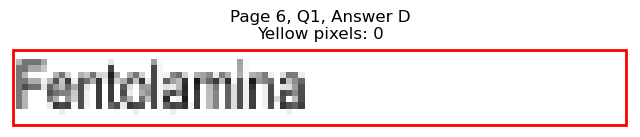

Page 6, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=382.6, y1=121.3
Page 6, Q1, E: Yellow pixels: 980
Page 6, Q1, E: Total non-white pixels: 1261
Page 6, Q1, E: Yellow percentage: 77.7%


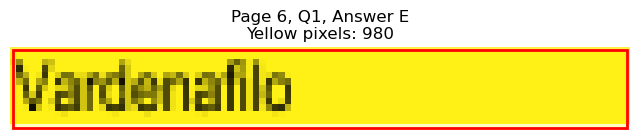


Page 6, Q1 - Selected Answer: E (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=85.0, y0=157.3, x1=111.3, y1=169.4
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 133
Page 6, Q2, A: Yellow percentage: 0.0%


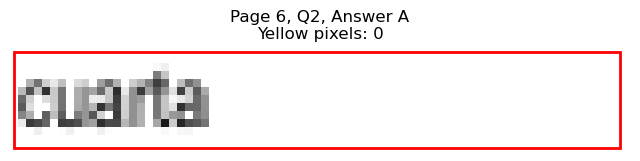

Page 6, Q2 - B: Detected box: x0=85.0, y0=169.4, x1=115.6, y1=181.5
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 141
Page 6, Q2, B: Yellow percentage: 0.0%


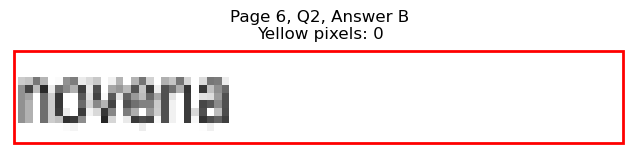

Page 6, Q2 - C: Detected box: x0=85.0, y0=181.4, x1=110.9, y1=193.5
Page 6, Q2, C: Yellow pixels: 0
Page 6, Q2, C: Total non-white pixels: 122
Page 6, Q2, C: Yellow percentage: 0.0%


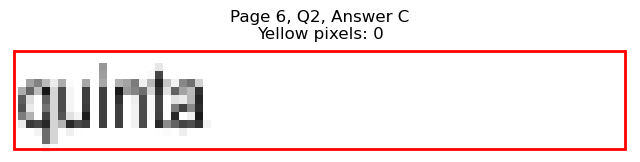

Page 6, Q2 - D: Detected box: x0=336.7, y0=157.3, x1=368.2, y1=169.4
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 160
Page 6, Q2, D: Yellow percentage: 0.0%


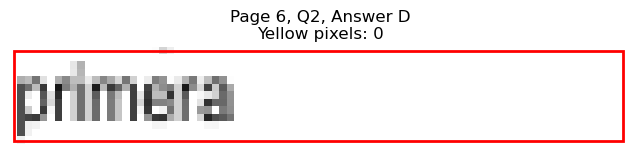

Page 6, Q2 - E: Detected box: x0=336.7, y0=169.4, x1=369.2, y1=181.5
Page 6, Q2, E: Yellow pixels: 952
Page 6, Q2, E: Total non-white pixels: 1092
Page 6, Q2, E: Yellow percentage: 87.2%


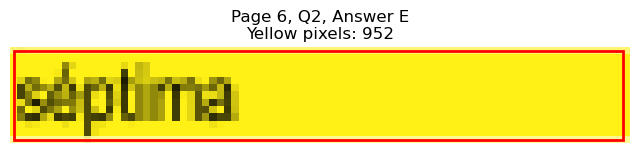


Page 6, Q2 - Selected Answer: E (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=85.0, y0=217.5, x1=331.5, y1=229.7
Page 6, Q3, A: Yellow pixels: 0
Page 6, Q3, A: Total non-white pixels: 1236
Page 6, Q3, A: Yellow percentage: 0.0%


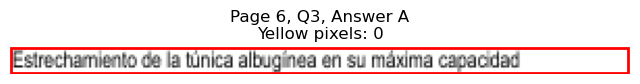

Page 6, Q3 - B: Detected box: x0=85.0, y0=229.7, x1=328.3, y1=241.8
Page 6, Q3, B: Yellow pixels: 2571
Page 6, Q3, B: Total non-white pixels: 3835
Page 6, Q3, B: Yellow percentage: 67.0%


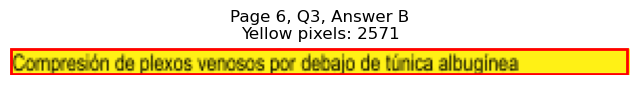

Page 6, Q3 - C: Detected box: x0=85.0, y0=241.7, x1=292.3, y1=253.8
Page 6, Q3, C: Yellow pixels: 249
Page 6, Q3, C: Total non-white pixels: 1257
Page 6, Q3, C: Yellow percentage: 19.8%


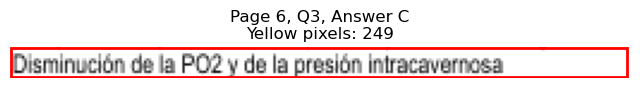

Page 6, Q3 - D: Detected box: x0=85.0, y0=253.7, x1=286.5, y1=265.8
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 993
Page 6, Q3, D: Yellow percentage: 0.0%


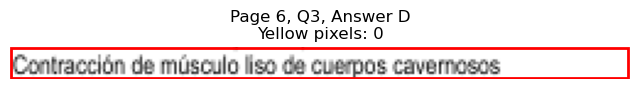

Page 6, Q3 - E: Detected box: x0=85.0, y0=265.8, x1=260.7, y1=277.9
Page 6, Q3, E: Yellow pixels: 0
Page 6, Q3, E: Total non-white pixels: 872
Page 6, Q3, E: Yellow percentage: 0.0%


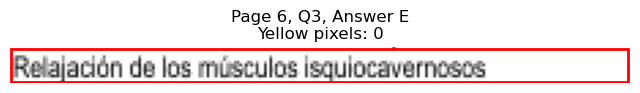


Page 6, Q3 - Selected Answer: B (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=85.0, y0=301.9, x1=125.7, y1=314.0
Page 6, Q4, A: Yellow pixels: 92
Page 6, Q4, A: Total non-white pixels: 410
Page 6, Q4, A: Yellow percentage: 22.4%


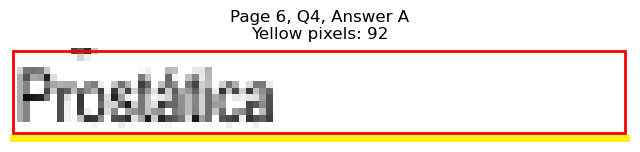

Page 6, Q4 - B: Detected box: x0=85.0, y0=313.9, x1=148.7, y1=326.0
Page 6, Q4, B: Yellow pixels: 1127
Page 6, Q4, B: Total non-white pixels: 1610
Page 6, Q4, B: Yellow percentage: 70.0%


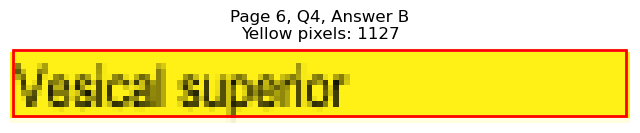

Page 6, Q4 - C: Detected box: x0=85.0, y0=326.1, x1=138.6, y1=338.2
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 376
Page 6, Q4, C: Yellow percentage: 0.0%


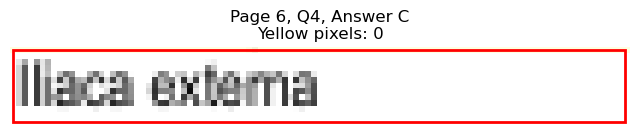

Page 6, Q4 - D: Detected box: x0=336.7, y0=301.9, x1=376.9, y1=314.0
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 205
Page 6, Q4, D: Yellow percentage: 0.0%


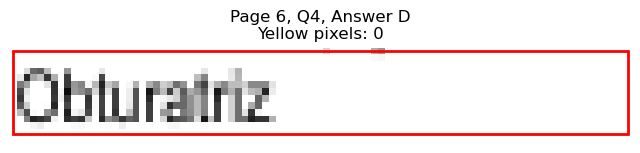

Page 6, Q4 - E: Detected box: x0=336.7, y0=313.9, x1=393.2, y1=326.0
Page 6, Q4, E: Yellow pixels: 0
Page 6, Q4, E: Total non-white pixels: 279
Page 6, Q4, E: Yellow percentage: 0.0%


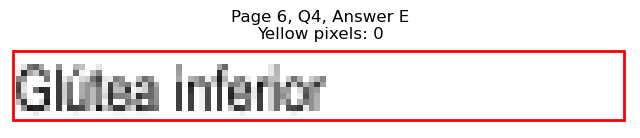


Page 6, Q4 - Selected Answer: B (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=85.0, y0=362.2, x1=125.7, y1=374.3
Page 6, Q5, A: Yellow pixels: 0
Page 6, Q5, A: Total non-white pixels: 200
Page 6, Q5, A: Yellow percentage: 0.0%


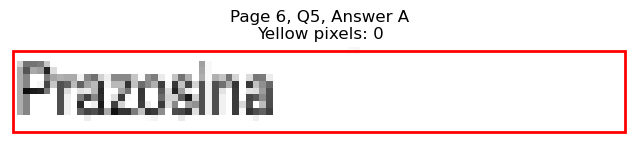

Page 6, Q5 - B: Detected box: x0=85.0, y0=374.2, x1=127.1, y1=386.3
Page 6, Q5, B: Yellow pixels: 0
Page 6, Q5, B: Total non-white pixels: 225
Page 6, Q5, B: Yellow percentage: 0.0%


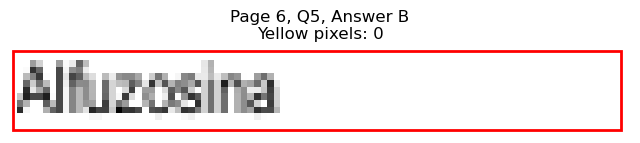

Page 6, Q5 - C: Detected box: x0=85.0, y0=386.3, x1=136.2, y1=398.4
Page 6, Q5, C: Yellow pixels: 1032
Page 6, Q5, C: Total non-white pixels: 1339
Page 6, Q5, C: Yellow percentage: 77.1%


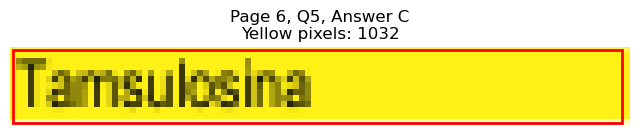

Page 6, Q5 - D: Detected box: x0=336.7, y0=362.2, x1=381.7, y1=374.3
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 211
Page 6, Q5, D: Yellow percentage: 0.0%


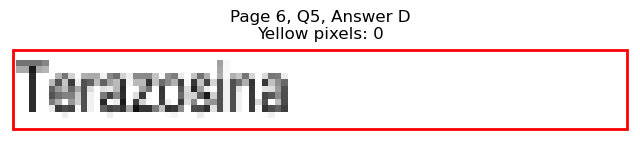

Page 6, Q5 - E: Detected box: x0=336.7, y0=374.2, x1=384.1, y1=386.3
Page 6, Q5, E: Yellow pixels: 0
Page 6, Q5, E: Total non-white pixels: 246
Page 6, Q5, E: Yellow percentage: 0.0%


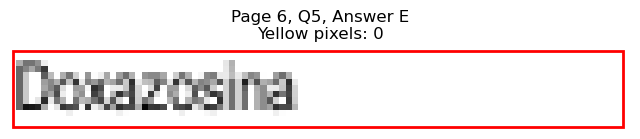


Page 6, Q5 - Selected Answer: C (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=85.0, y0=434.4, x1=151.0, y1=446.5
Page 6, Q6, A: Yellow pixels: 0
Page 6, Q6, A: Total non-white pixels: 371
Page 6, Q6, A: Yellow percentage: 0.0%


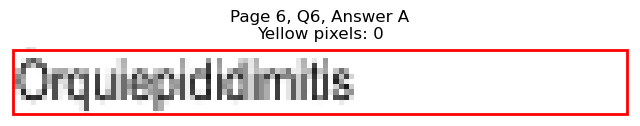

Page 6, Q6 - B: Detected box: x0=85.0, y0=446.6, x1=144.9, y1=458.7
Page 6, Q6, B: Yellow pixels: 0
Page 6, Q6, B: Total non-white pixels: 317
Page 6, Q6, B: Yellow percentage: 0.0%


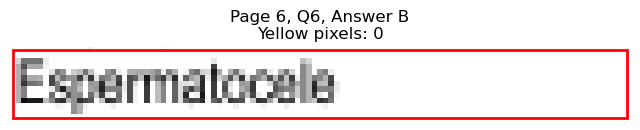

Page 6, Q6 - C: Detected box: x0=85.0, y0=458.6, x1=161.1, y1=470.7
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 399
Page 6, Q6, C: Yellow percentage: 0.0%


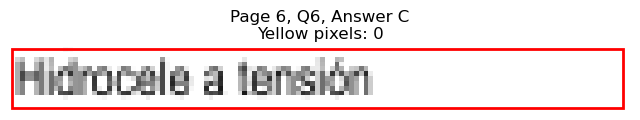

Page 6, Q6 - D: Detected box: x0=336.7, y0=434.4, x1=403.6, y1=446.5
Page 6, Q6, D: Yellow pixels: 1277
Page 6, Q6, D: Total non-white pixels: 1534
Page 6, Q6, D: Yellow percentage: 83.2%


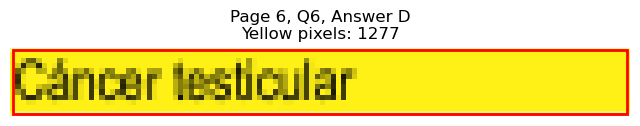

Page 6, Q6 - E: Detected box: x0=336.7, y0=446.6, x1=379.3, y1=458.7
Page 6, Q6, E: Yellow pixels: 94
Page 6, Q6, E: Total non-white pixels: 314
Page 6, Q6, E: Yellow percentage: 29.9%


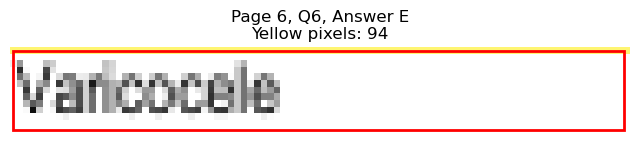


Page 6, Q6 - Selected Answer: D (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=85.0, y0=494.7, x1=135.7, y1=506.8
Page 6, Q7, A: Yellow pixels: 1015
Page 6, Q7, A: Total non-white pixels: 1326
Page 6, Q7, A: Yellow percentage: 76.5%


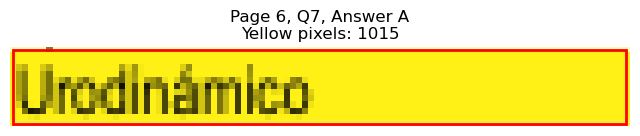

Page 6, Q7 - B: Detected box: x0=85.0, y0=506.8, x1=113.7, y1=518.9
Page 6, Q7, B: Yellow pixels: 80
Page 6, Q7, B: Total non-white pixels: 217
Page 6, Q7, B: Yellow percentage: 36.9%


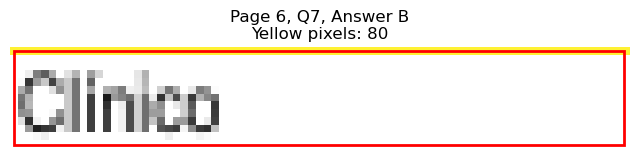

Page 6, Q7 - C: Detected box: x0=85.0, y0=518.8, x1=133.3, y1=530.9
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 259
Page 6, Q7, C: Yellow percentage: 0.0%


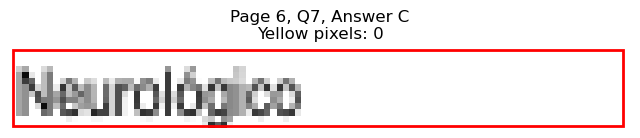

Page 6, Q7 - D: Detected box: x0=336.7, y0=494.7, x1=387.9, y1=506.8
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 262
Page 6, Q7, D: Yellow percentage: 0.0%


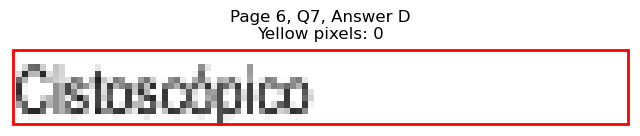

Page 6, Q7 - E: Detected box: x0=336.7, y0=506.8, x1=379.8, y1=518.9
Page 6, Q7, E: Yellow pixels: 0
Page 6, Q7, E: Total non-white pixels: 229
Page 6, Q7, E: Yellow percentage: 0.0%


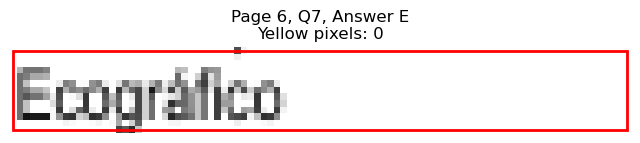


Page 6, Q7 - Selected Answer: A (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=85.0, y0=567.1, x1=147.3, y1=579.2
Page 6, Q8, A: Yellow pixels: 1116
Page 6, Q8, A: Total non-white pixels: 1482
Page 6, Q8, A: Yellow percentage: 75.3%


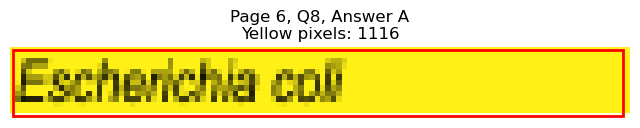

Page 6, Q8 - B: Detected box: x0=85.0, y0=579.1, x1=151.0, y1=591.2
Page 6, Q8, B: Yellow pixels: 0
Page 6, Q8, B: Total non-white pixels: 460
Page 6, Q8, B: Yellow percentage: 0.0%


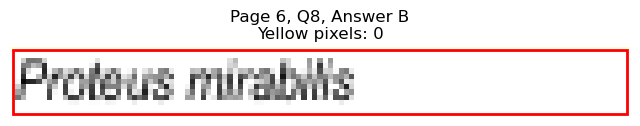

Page 6, Q8 - C: Detected box: x0=85.0, y0=591.2, x1=166.3, y1=603.3
Page 6, Q8, C: Yellow pixels: 0
Page 6, Q8, C: Total non-white pixels: 415
Page 6, Q8, C: Yellow percentage: 0.0%


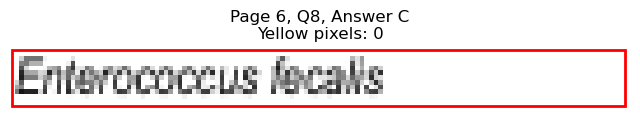

Page 6, Q8 - D: Detected box: x0=336.7, y0=567.1, x1=411.8, y1=579.2
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 416
Page 6, Q8, D: Yellow percentage: 0.0%


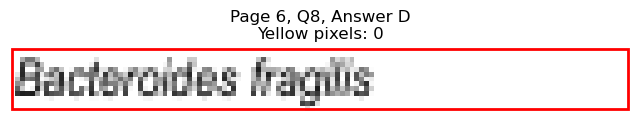

Page 6, Q8 - E: Detected box: x0=336.7, y0=579.1, x1=405.2, y1=591.2
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 365
Page 6, Q8, E: Yellow percentage: 0.0%


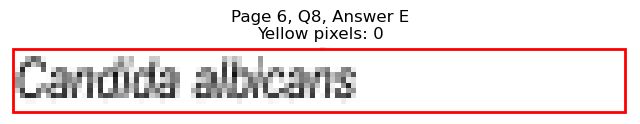


Page 6, Q8 - Selected Answer: A (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=85.0, y0=627.3, x1=172.6, y1=639.4
Page 6, Q9, A: Yellow pixels: 1281
Page 6, Q9, A: Total non-white pixels: 1807
Page 6, Q9, A: Yellow percentage: 70.9%


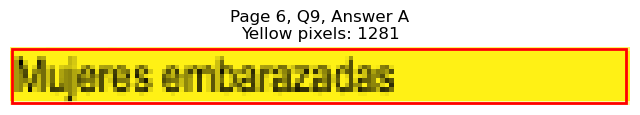

Page 6, Q9 - B: Detected box: x0=85.0, y0=639.3, x1=154.9, y1=651.4
Page 6, Q9, B: Yellow pixels: 1
Page 6, Q9, B: Total non-white pixels: 455
Page 6, Q9, B: Yellow percentage: 0.2%


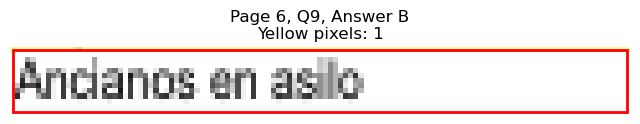

Page 6, Q9 - C: Detected box: x0=85.0, y0=651.4, x1=174.0, y1=663.5
Page 6, Q9, C: Yellow pixels: 0
Page 6, Q9, C: Total non-white pixels: 447
Page 6, Q9, C: Yellow percentage: 0.0%


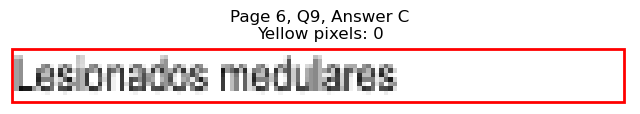

Page 6, Q9 - D: Detected box: x0=336.7, y0=627.3, x1=439.6, y1=639.4
Page 6, Q9, D: Yellow pixels: 0
Page 6, Q9, D: Total non-white pixels: 521
Page 6, Q9, D: Yellow percentage: 0.0%


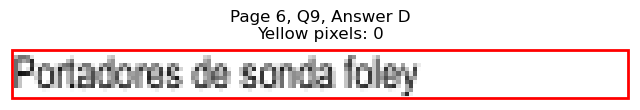

Page 6, Q9 - E: Detected box: x0=336.7, y0=639.3, x1=416.6, y1=651.4
Page 6, Q9, E: Yellow pixels: 0
Page 6, Q9, E: Total non-white pixels: 434
Page 6, Q9, E: Yellow percentage: 0.0%


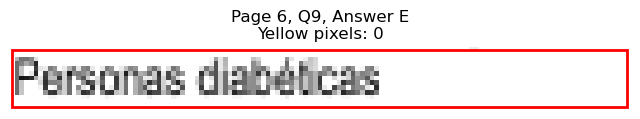


Page 6, Q9 - Selected Answer: A (based on yellow pixel count)




Page 6, Q10 - A: Detected box: x0=85.0, y0=699.5, x1=99.4, y1=711.7
Page 6, Q10, A: Yellow pixels: 796
Page 6, Q10, A: Total non-white pixels: 858
Page 6, Q10, A: Yellow percentage: 92.8%


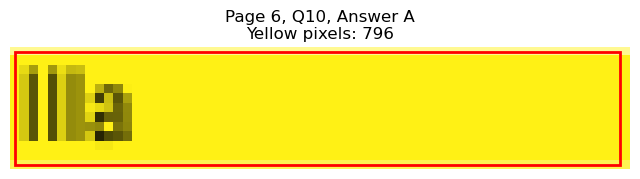

Page 6, Q10 - B: Detected box: x0=85.0, y0=711.7, x1=97.0, y1=723.8
Page 6, Q10, B: Yellow pixels: 63
Page 6, Q10, B: Total non-white pixels: 123
Page 6, Q10, B: Yellow percentage: 51.2%


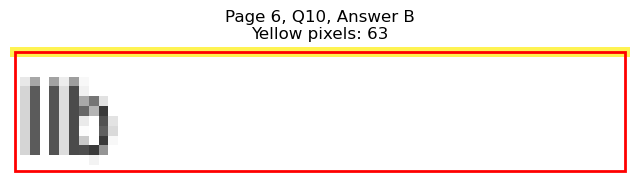

Page 6, Q10 - C: Detected box: x0=85.0, y0=723.7, x1=97.0, y1=735.8
Page 6, Q10, C: Yellow pixels: 0
Page 6, Q10, C: Total non-white pixels: 57
Page 6, Q10, C: Yellow percentage: 0.0%


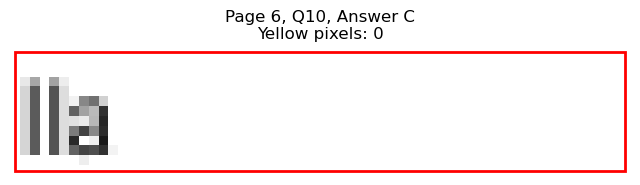

Page 6, Q10 - D: Detected box: x0=336.7, y0=699.5, x1=351.1, y1=711.7
Page 6, Q10, D: Yellow pixels: 0
Page 6, Q10, D: Total non-white pixels: 76
Page 6, Q10, D: Yellow percentage: 0.0%


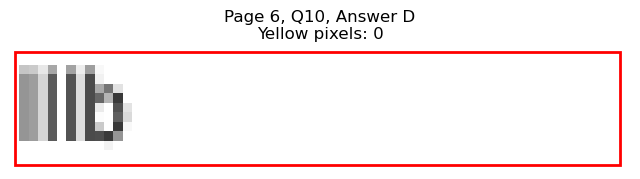

Page 6, Q10 - E: Detected box: x0=336.7, y0=711.7, x1=347.2, y1=723.8
Page 6, Q10, E: Yellow pixels: 0
Page 6, Q10, E: Total non-white pixels: 44
Page 6, Q10, E: Yellow percentage: 0.0%


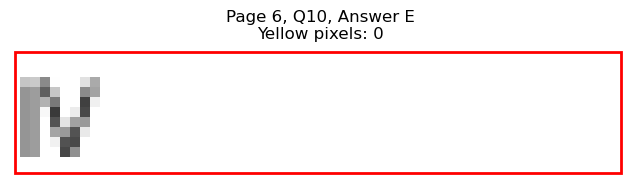


Page 6, Q10 - Selected Answer: A (based on yellow pixel count)





Page 7: Found 11 questions
Page 7, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=150.1, y1=109.2
Page 7, Q1, A: Yellow pixels: 0
Page 7, Q1, A: Total non-white pixels: 329
Page 7, Q1, A: Yellow percentage: 0.0%


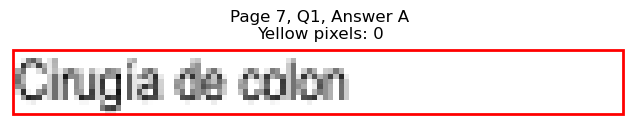

Page 7, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=139.6, y1=121.3
Page 7, Q1, B: Yellow pixels: 0
Page 7, Q1, B: Total non-white pixels: 289
Page 7, Q1, B: Yellow percentage: 0.0%


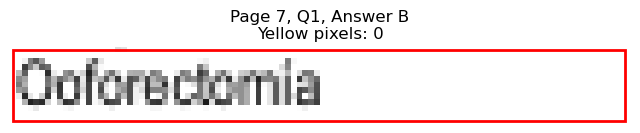

Page 7, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=174.0, y1=133.3
Page 7, Q1, C: Yellow pixels: 0
Page 7, Q1, C: Total non-white pixels: 481
Page 7, Q1, C: Yellow percentage: 0.0%


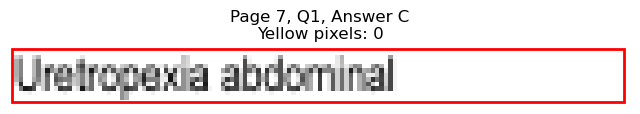

Page 7, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=392.2, y1=109.2
Page 7, Q1, D: Yellow pixels: 1042
Page 7, Q1, D: Total non-white pixels: 1391
Page 7, Q1, D: Yellow percentage: 74.9%


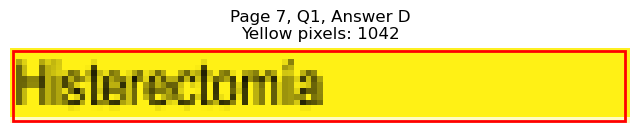

Page 7, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=421.4, y1=121.3
Page 7, Q1, E: Yellow pixels: 0
Page 7, Q1, E: Total non-white pixels: 563
Page 7, Q1, E: Yellow percentage: 0.0%


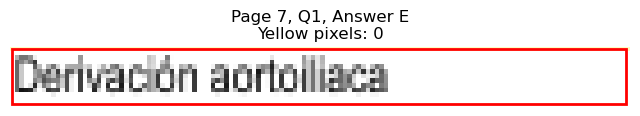


Page 7, Q1 - Selected Answer: D (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=85.0, y0=157.3, x1=194.6, y1=169.4
Page 7, Q2, A: Yellow pixels: 1665
Page 7, Q2, A: Total non-white pixels: 2093
Page 7, Q2, A: Yellow percentage: 79.6%


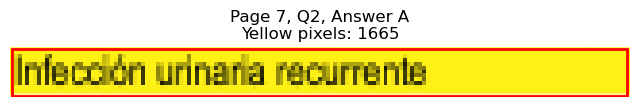

Page 7, Q2 - B: Detected box: x0=85.0, y0=169.4, x1=148.7, y1=181.5
Page 7, Q2, B: Yellow pixels: 115
Page 7, Q2, B: Total non-white pixels: 453
Page 7, Q2, B: Yellow percentage: 25.4%


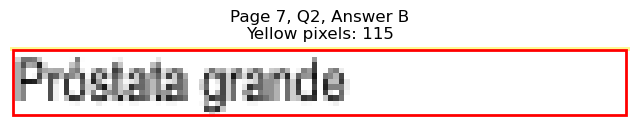

Page 7, Q2 - C: Detected box: x0=85.0, y0=181.4, x1=163.9, y1=193.5
Page 7, Q2, C: Yellow pixels: 0
Page 7, Q2, C: Total non-white pixels: 389
Page 7, Q2, C: Yellow percentage: 0.0%


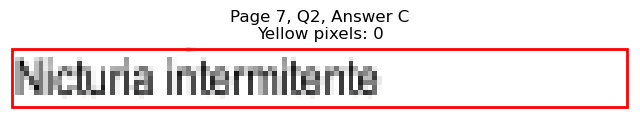

Page 7, Q2 - D: Detected box: x0=336.7, y0=157.3, x1=404.6, y1=169.4
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 347
Page 7, Q2, D: Yellow percentage: 0.0%


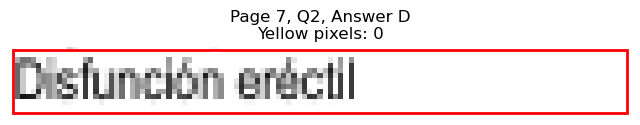

Page 7, Q2 - E: Detected box: x0=336.7, y0=169.4, x1=427.6, y1=181.5
Page 7, Q2, E: Yellow pixels: 0
Page 7, Q2, E: Total non-white pixels: 481
Page 7, Q2, E: Yellow percentage: 0.0%


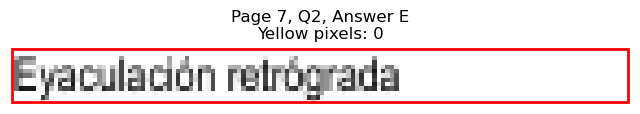


Page 7, Q2 - Selected Answer: A (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=85.0, y0=217.5, x1=195.1, y1=229.7
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 600
Page 7, Q3, A: Yellow percentage: 0.0%


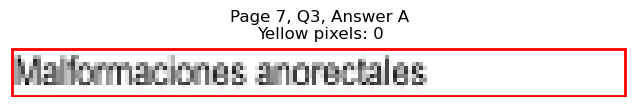

Page 7, Q3 - B: Detected box: x0=85.0, y0=229.7, x1=155.8, y1=241.8
Page 7, Q3, B: Yellow pixels: 0
Page 7, Q3, B: Total non-white pixels: 329
Page 7, Q3, B: Yellow percentage: 0.0%


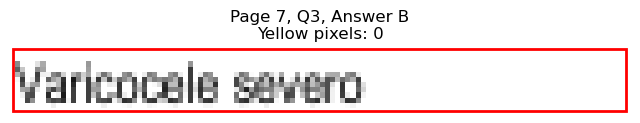

Page 7, Q3 - C: Detected box: x0=85.0, y0=241.7, x1=163.5, y1=253.8
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 417
Page 7, Q3, C: Yellow percentage: 0.0%


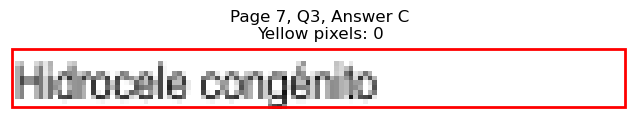

Page 7, Q3 - D: Detected box: x0=336.7, y0=217.5, x1=425.2, y1=229.7
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 482
Page 7, Q3, D: Yellow percentage: 0.0%


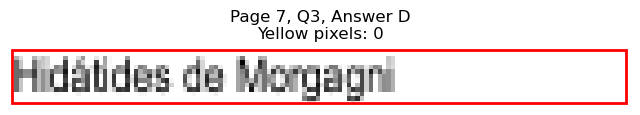

Page 7, Q3 - E: Detected box: x0=336.7, y0=229.7, x1=446.9, y1=241.8
Page 7, Q3, E: Yellow pixels: 1512
Page 7, Q3, E: Total non-white pixels: 2093
Page 7, Q3, E: Yellow percentage: 72.2%


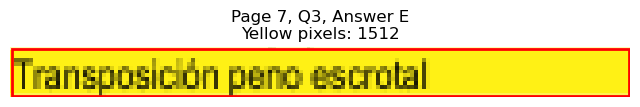


Page 7, Q3 - Selected Answer: E (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=85.0, y0=277.8, x1=114.1, y1=289.9
Page 7, Q4, A: Yellow pixels: 0
Page 7, Q4, A: Total non-white pixels: 155
Page 7, Q4, A: Yellow percentage: 0.0%


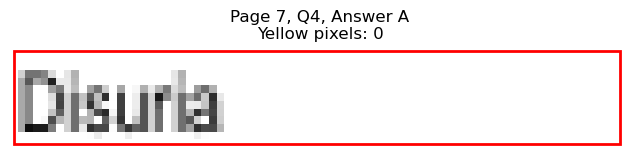

Page 7, Q4 - B: Detected box: x0=85.0, y0=289.9, x1=138.1, y1=302.0
Page 7, Q4, B: Yellow pixels: 1024
Page 7, Q4, B: Total non-white pixels: 1367
Page 7, Q4, B: Yellow percentage: 74.9%


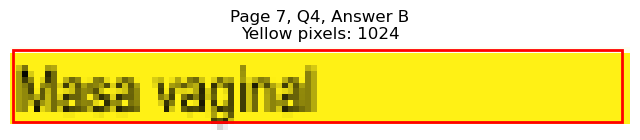

Page 7, Q4 - C: Detected box: x0=85.0, y0=301.9, x1=142.5, y1=314.0
Page 7, Q4, C: Yellow pixels: 105
Page 7, Q4, C: Total non-white pixels: 400
Page 7, Q4, C: Yellow percentage: 26.2%


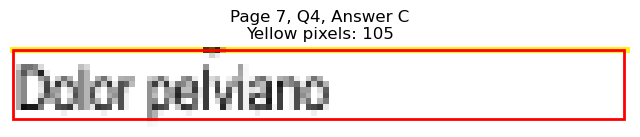

Page 7, Q4 - D: Detected box: x0=336.7, y0=277.8, x1=414.7, y1=289.9
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 380
Page 7, Q4, D: Yellow percentage: 0.0%


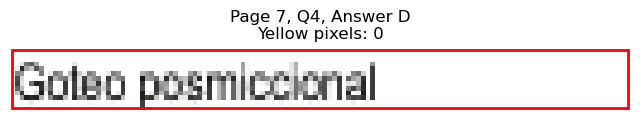

Page 7, Q4 - E: Detected box: x0=336.7, y0=289.9, x1=403.6, y1=302.0
Page 7, Q4, E: Yellow pixels: 0
Page 7, Q4, E: Total non-white pixels: 310
Page 7, Q4, E: Yellow percentage: 0.0%


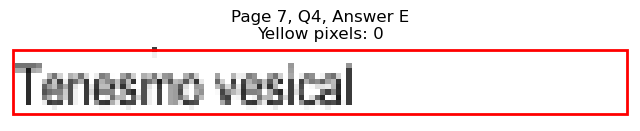


Page 7, Q4 - Selected Answer: B (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=85.0, y0=338.1, x1=132.4, y1=350.2
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 250
Page 7, Q5, A: Yellow percentage: 0.0%


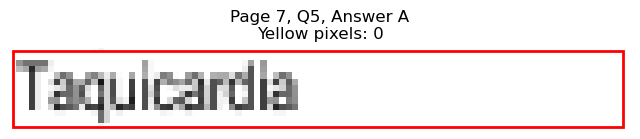

Page 7, Q5 - B: Detected box: x0=85.0, y0=350.2, x1=137.7, y1=362.3
Page 7, Q5, B: Yellow pixels: 0
Page 7, Q5, B: Total non-white pixels: 292
Page 7, Q5, B: Yellow percentage: 0.0%


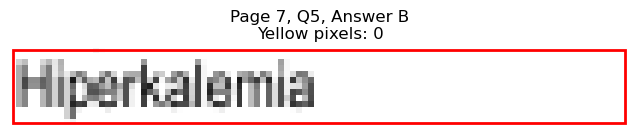

Page 7, Q5 - C: Detected box: x0=85.0, y0=362.2, x1=133.3, y1=374.3
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 272
Page 7, Q5, C: Yellow percentage: 0.0%


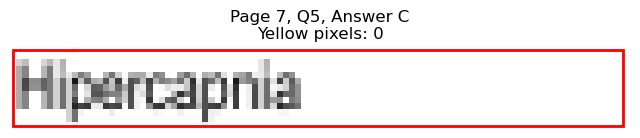

Page 7, Q5 - D: Detected box: x0=336.7, y0=338.1, x1=406.0, y1=350.2
Page 7, Q5, D: Yellow pixels: 1165
Page 7, Q5, D: Total non-white pixels: 1573
Page 7, Q5, D: Yellow percentage: 74.1%


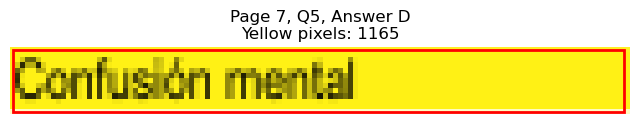

Page 7, Q5 - E: Detected box: x0=336.7, y0=350.2, x1=373.0, y1=362.3
Page 7, Q5, E: Yellow pixels: 0
Page 7, Q5, E: Total non-white pixels: 275
Page 7, Q5, E: Yellow percentage: 0.0%


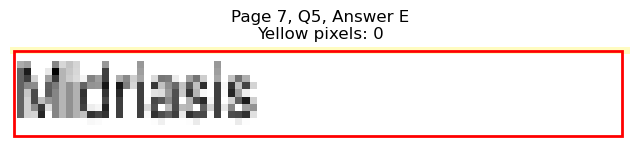


Page 7, Q5 - Selected Answer: D (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=85.0, y0=398.3, x1=121.3, y1=410.4
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 195
Page 7, Q6, A: Yellow percentage: 0.0%


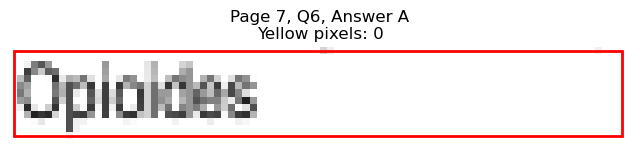

Page 7, Q6 - B: Detected box: x0=85.0, y0=410.4, x1=221.0, y1=422.5
Page 7, Q6, B: Yellow pixels: 187
Page 7, Q6, B: Total non-white pixels: 860
Page 7, Q6, B: Yellow percentage: 21.7%


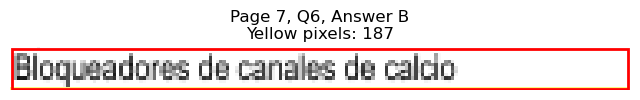

Page 7, Q6 - C: Detected box: x0=85.0, y0=422.4, x1=113.2, y1=434.5
Page 7, Q6, C: Yellow pixels: 922
Page 7, Q6, C: Total non-white pixels: 1040
Page 7, Q6, C: Yellow percentage: 88.7%


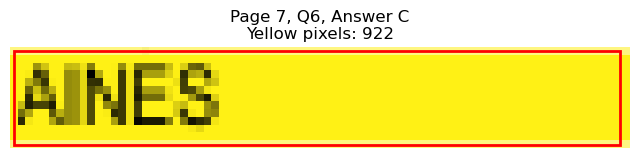

Page 7, Q6 - D: Detected box: x0=336.7, y0=398.3, x1=401.2, y1=410.4
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 338
Page 7, Q6, D: Yellow percentage: 0.0%


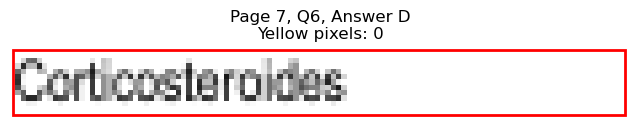

Page 7, Q6 - E: Detected box: x0=336.7, y0=410.4, x1=399.4, y1=422.5
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 334
Page 7, Q6, E: Yellow percentage: 0.0%


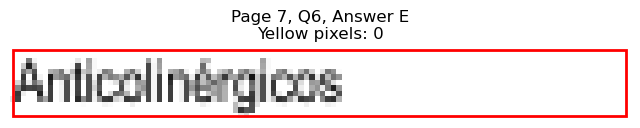


Page 7, Q6 - Selected Answer: C (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=85.0, y0=482.7, x1=180.3, y1=494.8
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 482
Page 7, Q7, A: Yellow percentage: 0.0%


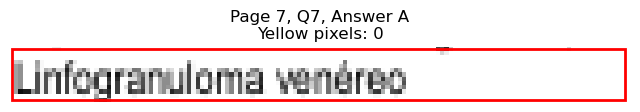

Page 7, Q7 - B: Detected box: x0=85.0, y0=494.7, x1=152.4, y1=506.8
Page 7, Q7, B: Yellow pixels: 0
Page 7, Q7, B: Total non-white pixels: 348
Page 7, Q7, B: Yellow percentage: 0.0%


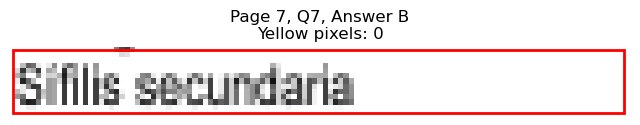

Page 7, Q7 - C: Detected box: x0=85.0, y0=506.8, x1=131.4, y1=518.9
Page 7, Q7, C: Yellow pixels: 0
Page 7, Q7, C: Total non-white pixels: 233
Page 7, Q7, C: Yellow percentage: 0.0%


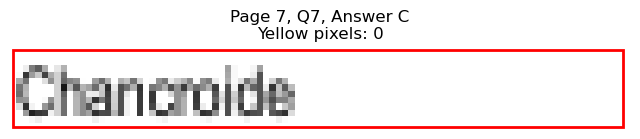

Page 7, Q7 - D: Detected box: x0=336.7, y0=482.7, x1=402.7, y1=494.8
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 504
Page 7, Q7, D: Yellow percentage: 0.0%


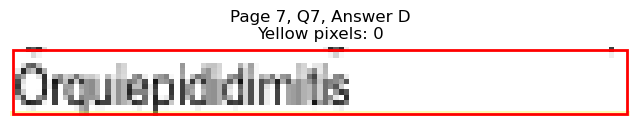

Page 7, Q7 - E: Detected box: x0=336.7, y0=494.7, x1=415.6, y1=506.8
Page 7, Q7, E: Yellow pixels: 1240
Page 7, Q7, E: Total non-white pixels: 1690
Page 7, Q7, E: Yellow percentage: 73.4%


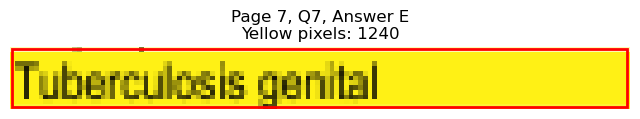


Page 7, Q7 - Selected Answer: E (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=85.0, y0=542.9, x1=215.2, y1=555.0
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 655
Page 7, Q8, A: Yellow percentage: 0.0%


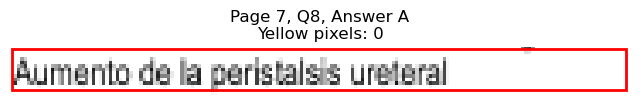

Page 7, Q8 - B: Detected box: x0=85.0, y0=554.9, x1=214.3, y1=567.0
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 691
Page 7, Q8, B: Yellow percentage: 0.0%


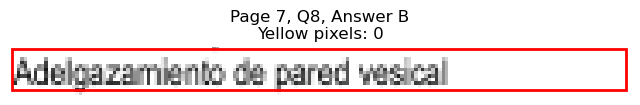

Page 7, Q8 - C: Detected box: x0=85.0, y0=567.1, x1=218.6, y1=579.2
Page 7, Q8, C: Yellow pixels: 0
Page 7, Q8, C: Total non-white pixels: 672
Page 7, Q8, C: Yellow percentage: 0.0%


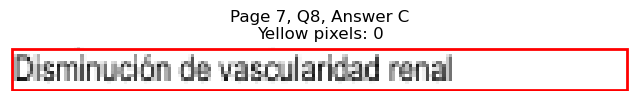

Page 7, Q8 - D: Detected box: x0=336.7, y0=542.9, x1=467.4, y1=555.0
Page 7, Q8, D: Yellow pixels: 182
Page 7, Q8, D: Total non-white pixels: 989
Page 7, Q8, D: Yellow percentage: 18.4%


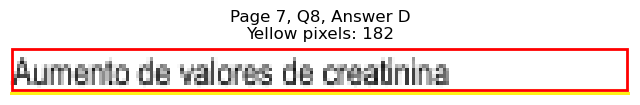

Page 7, Q8 - E: Detected box: x0=336.7, y0=554.9, x1=480.7, y1=567.0
Page 7, Q8, E: Yellow pixels: 1675
Page 7, Q8, E: Total non-white pixels: 2660
Page 7, Q8, E: Yellow percentage: 63.0%


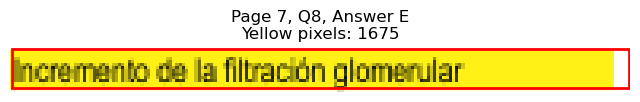


Page 7, Q8 - Selected Answer: E (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=85.0, y0=603.2, x1=140.1, y1=615.3
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 298
Page 7, Q9, A: Yellow percentage: 0.0%


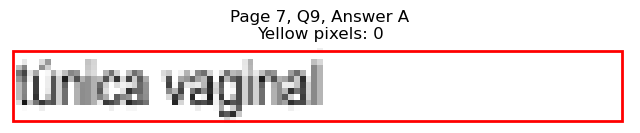

Page 7, Q9 - B: Detected box: x0=85.0, y0=615.2, x1=151.6, y1=627.3
Page 7, Q9, B: Yellow pixels: 0
Page 7, Q9, B: Total non-white pixels: 340
Page 7, Q9, B: Yellow percentage: 0.0%


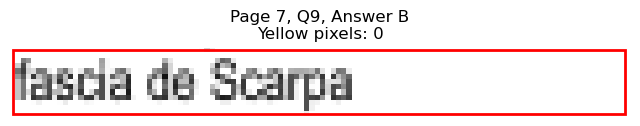

Page 7, Q9 - C: Detected box: x0=85.0, y0=627.3, x1=143.4, y1=639.4
Page 7, Q9, C: Yellow pixels: 0
Page 7, Q9, C: Total non-white pixels: 295
Page 7, Q9, C: Yellow percentage: 0.0%


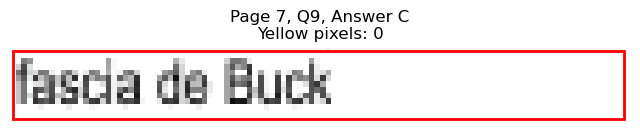

Page 7, Q9 - D: Detected box: x0=336.7, y0=603.2, x1=402.3, y1=615.3
Page 7, Q9, D: Yellow pixels: 1129
Page 7, Q9, D: Total non-white pixels: 1521
Page 7, Q9, D: Yellow percentage: 74.2%


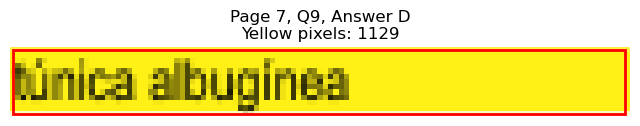

Page 7, Q9 - E: Detected box: x0=336.7, y0=615.2, x1=399.9, y1=627.3
Page 7, Q9, E: Yellow pixels: 0
Page 7, Q9, E: Total non-white pixels: 422
Page 7, Q9, E: Yellow percentage: 0.0%


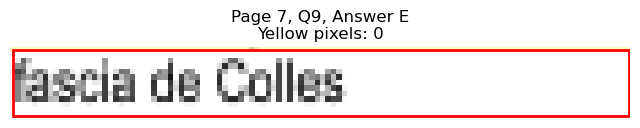


Page 7, Q9 - Selected Answer: D (based on yellow pixel count)




Page 7, Q10 - A: Detected box: x0=85.0, y0=675.4, x1=131.9, y1=687.5
Page 7, Q10, A: Yellow pixels: 0
Page 7, Q10, A: Total non-white pixels: 252
Page 7, Q10, A: Yellow percentage: 0.0%


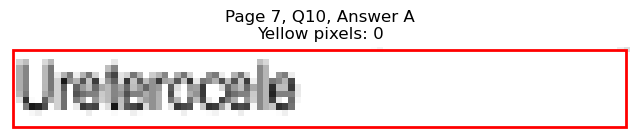

Page 7, Q10 - B: Detected box: x0=85.0, y0=687.5, x1=154.8, y1=699.7
Page 7, Q10, B: Yellow pixels: 0
Page 7, Q10, B: Total non-white pixels: 362
Page 7, Q10, B: Yellow percentage: 0.0%


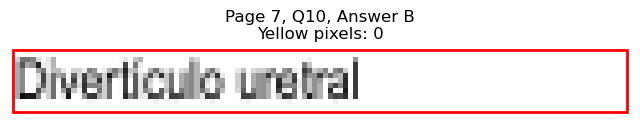

Page 7, Q10 - C: Detected box: x0=85.0, y0=699.5, x1=146.8, y1=711.7
Page 7, Q10, C: Yellow pixels: 0
Page 7, Q10, C: Total non-white pixels: 323
Page 7, Q10, C: Yellow percentage: 0.0%


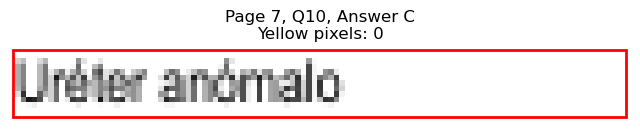

Page 7, Q10 - D: Detected box: x0=336.7, y0=675.4, x1=397.5, y1=687.5
Page 7, Q10, D: Yellow pixels: 1205
Page 7, Q10, D: Total non-white pixels: 1456
Page 7, Q10, D: Yellow percentage: 82.8%


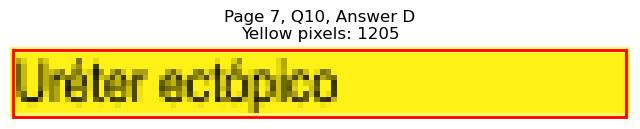

Page 7, Q10 - E: Detected box: x0=336.7, y0=687.5, x1=390.8, y1=699.7
Page 7, Q10, E: Yellow pixels: 105
Page 7, Q10, E: Total non-white pixels: 371
Page 7, Q10, E: Yellow percentage: 28.3%


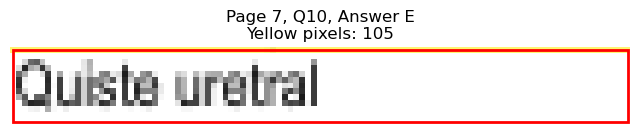


Page 7, Q10 - Selected Answer: D (based on yellow pixel count)




Page 7, Q11 - A: Detected box: x0=85.0, y0=735.8, x1=138.1, y1=747.9
Page 7, Q11, A: Yellow pixels: 0
Page 7, Q11, A: Total non-white pixels: 280
Page 7, Q11, A: Yellow percentage: 0.0%


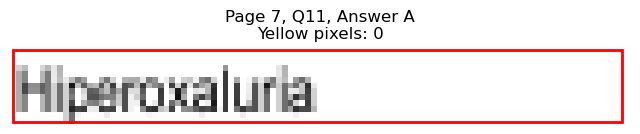

Page 7, Q11 - B: Detected box: x0=85.0, y0=747.8, x1=142.0, y1=759.9
Page 7, Q11, B: Yellow pixels: 0
Page 7, Q11, B: Total non-white pixels: 425
Page 7, Q11, B: Yellow percentage: 0.0%


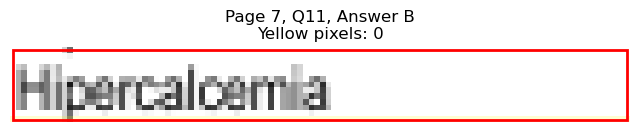

Page 7, Q11 - C: Detected box: x0=85.0, y0=759.8, x1=139.6, y1=771.9
Page 7, Q11, C: Yellow pixels: 1039
Page 7, Q11, C: Total non-white pixels: 1378
Page 7, Q11, C: Yellow percentage: 75.4%


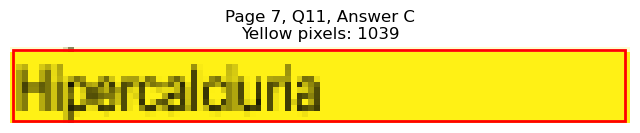

Page 7, Q11 - D: Detected box: x0=336.7, y0=735.8, x1=396.9, y1=747.9
Page 7, Q11, D: Yellow pixels: 0
Page 7, Q11, D: Total non-white pixels: 315
Page 7, Q11, D: Yellow percentage: 0.0%


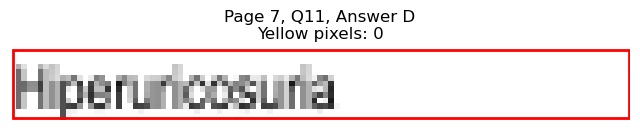

Page 7, Q11 - E: Detected box: x0=336.7, y0=747.8, x1=389.8, y1=759.9
Page 7, Q11, E: Yellow pixels: 0
Page 7, Q11, E: Total non-white pixels: 300
Page 7, Q11, E: Yellow percentage: 0.0%


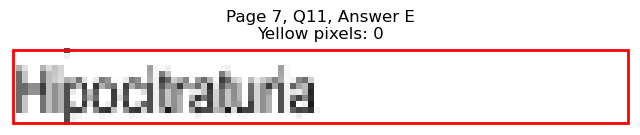


Page 7, Q11 - Selected Answer: C (based on yellow pixel count)





Page 8: Found 10 questions
Page 8, Q1 - A: Detected box: x0=85.0, y0=121.2, x1=100.4, y1=133.3
Page 8, Q1, A: Yellow pixels: 67
Page 8, Q1, A: Total non-white pixels: 158
Page 8, Q1, A: Yellow percentage: 42.4%


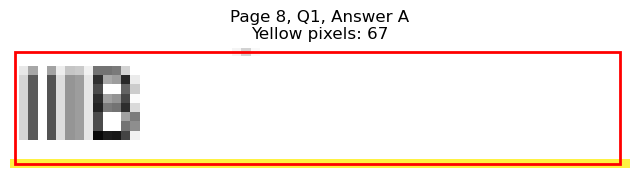

Page 8, Q1 - B: Detected box: x0=85.0, y0=133.2, x1=100.4, y1=145.3
Page 8, Q1, B: Yellow pixels: 739
Page 8, Q1, B: Total non-white pixels: 871
Page 8, Q1, B: Yellow percentage: 84.8%


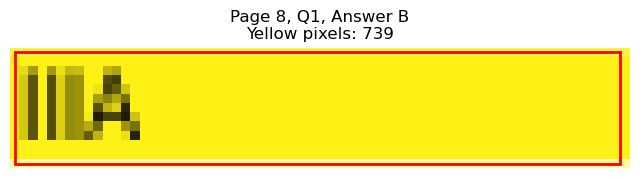

Page 8, Q1 - C: Detected box: x0=85.0, y0=145.3, x1=98.0, y1=157.4
Page 8, Q1, C: Yellow pixels: 0
Page 8, Q1, C: Total non-white pixels: 124
Page 8, Q1, C: Yellow percentage: 0.0%


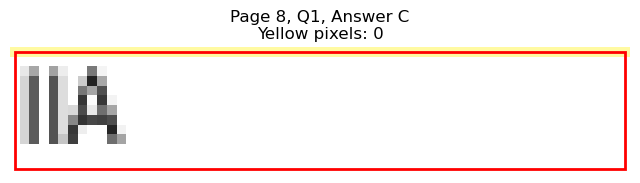

Page 8, Q1 - D: Detected box: x0=336.7, y0=121.2, x1=349.6, y1=133.3
Page 8, Q1, D: Yellow pixels: 0
Page 8, Q1, D: Total non-white pixels: 65
Page 8, Q1, D: Yellow percentage: 0.0%


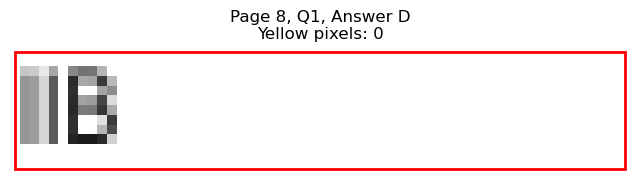

Page 8, Q1 - E: Detected box: x0=336.7, y0=133.2, x1=347.2, y1=145.3
Page 8, Q1, E: Yellow pixels: 0
Page 8, Q1, E: Total non-white pixels: 44
Page 8, Q1, E: Yellow percentage: 0.0%


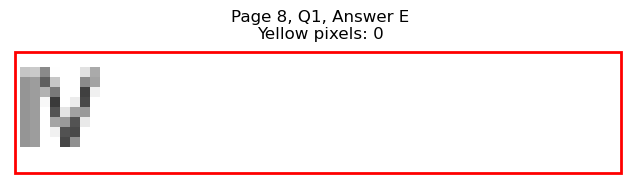


Page 8, Q1 - Selected Answer: B (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=143.9, y1=193.5
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 322
Page 8, Q2, A: Yellow percentage: 0.0%


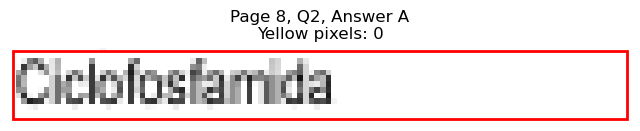

Page 8, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=130.5, y1=205.5
Page 8, Q2, B: Yellow pixels: 0
Page 8, Q2, B: Total non-white pixels: 242
Page 8, Q2, B: Yellow percentage: 0.0%


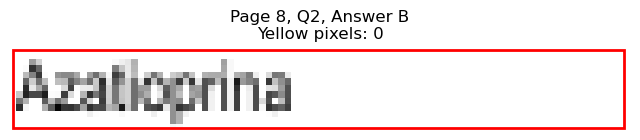

Page 8, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=149.5, y1=217.7
Page 8, Q2, C: Yellow pixels: 1230
Page 8, Q2, C: Total non-white pixels: 1508
Page 8, Q2, C: Yellow percentage: 81.6%


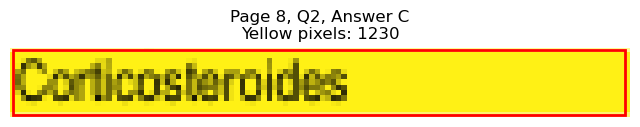

Page 8, Q2 - D: Detected box: x0=336.7, y0=181.4, x1=378.8, y1=193.5
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 223
Page 8, Q2, D: Yellow percentage: 0.0%


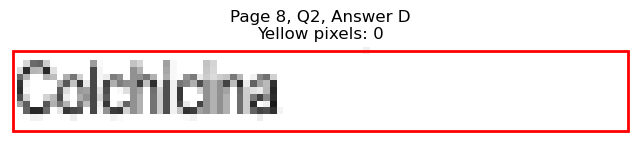

Page 8, Q2 - E: Detected box: x0=336.7, y0=193.4, x1=386.5, y1=205.5
Page 8, Q2, E: Yellow pixels: 0
Page 8, Q2, E: Total non-white pixels: 266
Page 8, Q2, E: Yellow percentage: 0.0%


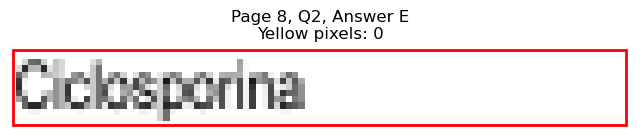


Page 8, Q2 - Selected Answer: C (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=85.0, y0=253.7, x1=160.6, y1=265.8
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 415
Page 8, Q3, A: Yellow percentage: 0.0%


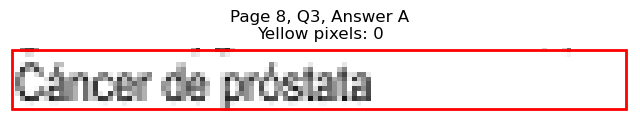

Page 8, Q3 - B: Detected box: x0=85.0, y0=265.8, x1=155.3, y1=277.9
Page 8, Q3, B: Yellow pixels: 0
Page 8, Q3, B: Total non-white pixels: 502
Page 8, Q3, B: Yellow percentage: 0.0%


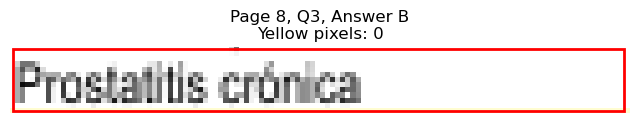

Page 8, Q3 - C: Detected box: x0=85.0, y0=277.8, x1=175.9, y1=289.9
Page 8, Q3, C: Yellow pixels: 1314
Page 8, Q3, C: Total non-white pixels: 1846
Page 8, Q3, C: Yellow percentage: 71.2%


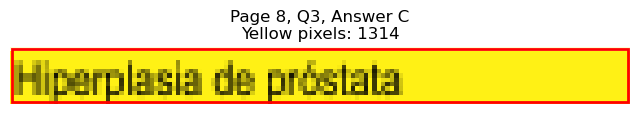

Page 8, Q3 - D: Detected box: x0=336.7, y0=253.7, x1=408.9, y1=265.8
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 400
Page 8, Q3, D: Yellow percentage: 0.0%


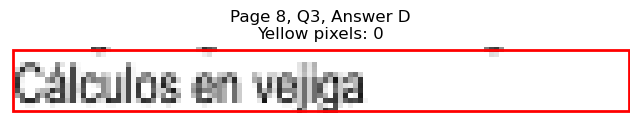

Page 8, Q3 - E: Detected box: x0=336.7, y0=265.8, x1=407.0, y1=277.9
Page 8, Q3, E: Yellow pixels: 0
Page 8, Q3, E: Total non-white pixels: 396
Page 8, Q3, E: Yellow percentage: 0.0%


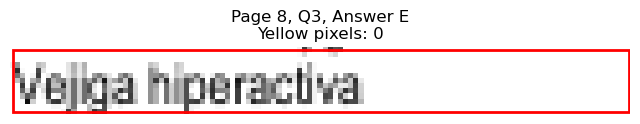


Page 8, Q3 - Selected Answer: C (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=85.0, y0=326.1, x1=102.3, y1=338.2
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 81
Page 8, Q4, A: Yellow percentage: 0.0%


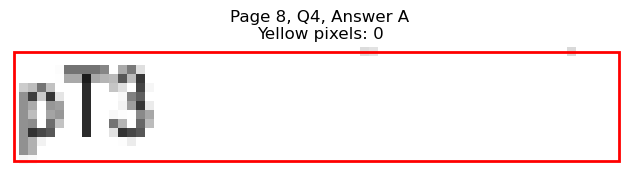

Page 8, Q4 - B: Detected box: x0=85.0, y0=338.1, x1=102.3, y1=350.2
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 69
Page 8, Q4, B: Yellow percentage: 0.0%


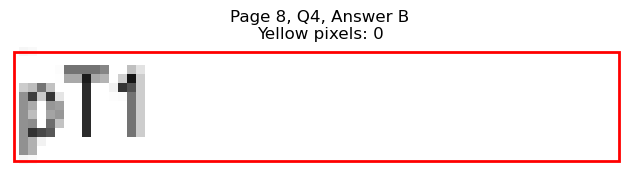

Page 8, Q4 - C: Detected box: x0=85.0, y0=350.2, x1=102.3, y1=362.3
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 76
Page 8, Q4, C: Yellow percentage: 0.0%


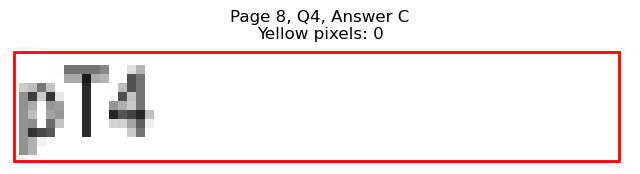

Page 8, Q4 - D: Detected box: x0=336.7, y0=326.1, x1=354.0, y1=338.2
Page 8, Q4, D: Yellow pixels: 755
Page 8, Q4, D: Total non-white pixels: 884
Page 8, Q4, D: Yellow percentage: 85.4%


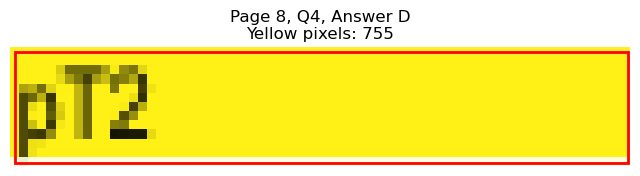

Page 8, Q4 - E: Detected box: x0=336.7, y0=338.1, x1=355.4, y1=350.2
Page 8, Q4, E: Yellow pixels: 0
Page 8, Q4, E: Total non-white pixels: 162
Page 8, Q4, E: Yellow percentage: 0.0%


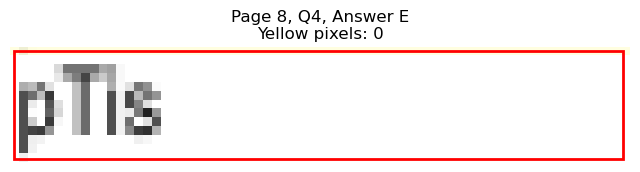


Page 8, Q4 - Selected Answer: D (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=85.0, y0=386.3, x1=152.5, y1=398.4
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 338
Page 8, Q5, A: Yellow percentage: 0.0%


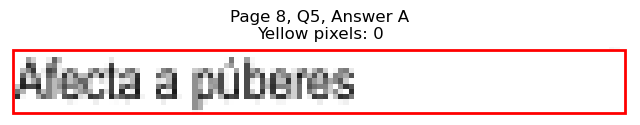

Page 8, Q5 - B: Detected box: x0=85.0, y0=398.3, x1=195.5, y1=410.4
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 598
Page 8, Q5, B: Yellow percentage: 0.0%


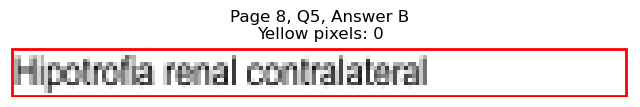

Page 8, Q5 - C: Detected box: x0=85.0, y0=410.4, x1=156.3, y1=422.5
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 365
Page 8, Q5, C: Yellow percentage: 0.0%


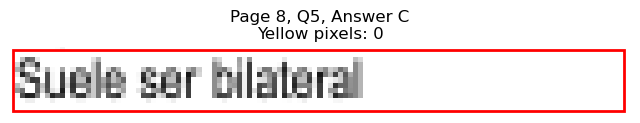

Page 8, Q5 - D: Detected box: x0=336.7, y0=386.3, x1=425.7, y1=398.4
Page 8, Q5, D: Yellow pixels: 1337
Page 8, Q5, D: Total non-white pixels: 1820
Page 8, Q5, D: Yellow percentage: 73.5%


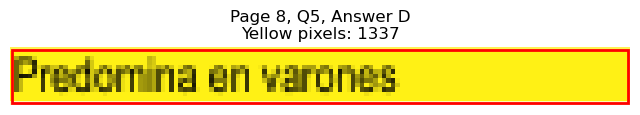

Page 8, Q5 - E: Detected box: x0=336.7, y0=398.3, x1=439.6, y1=410.4
Page 8, Q5, E: Yellow pixels: 0
Page 8, Q5, E: Total non-white pixels: 680
Page 8, Q5, E: Yellow percentage: 0.0%


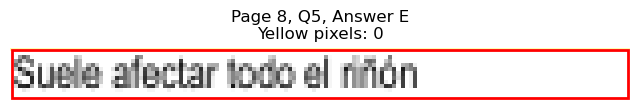


Page 8, Q5 - Selected Answer: D (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=85.0, y0=446.6, x1=169.2, y1=458.7
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 429
Page 8, Q6, A: Yellow percentage: 0.0%


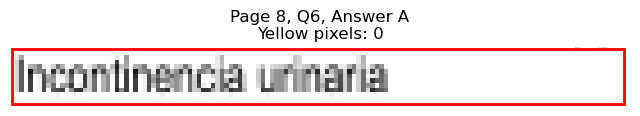

Page 8, Q6 - B: Detected box: x0=85.0, y0=458.6, x1=151.9, y1=470.7
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 332
Page 8, Q6, B: Yellow percentage: 0.0%


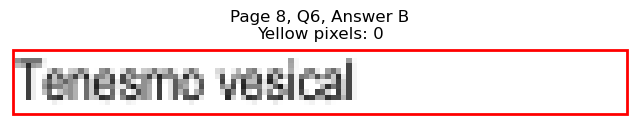

Page 8, Q6 - C: Detected box: x0=85.0, y0=470.7, x1=134.3, y1=482.8
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 247
Page 8, Q6, C: Yellow percentage: 0.0%


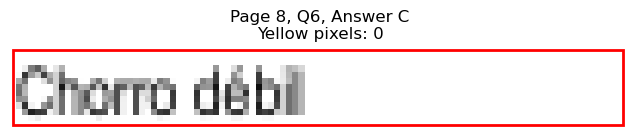

Page 8, Q6 - D: Detected box: x0=336.7, y0=446.6, x1=404.6, y1=458.7
Page 8, Q6, D: Yellow pixels: 119
Page 8, Q6, D: Total non-white pixels: 461
Page 8, Q6, D: Yellow percentage: 25.8%


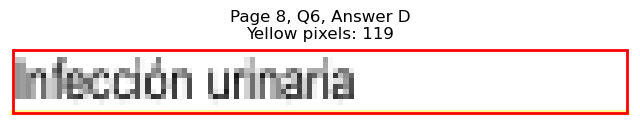

Page 8, Q6 - E: Detected box: x0=336.7, y0=458.6, x1=411.8, y1=470.7
Page 8, Q6, E: Yellow pixels: 1342
Page 8, Q6, E: Total non-white pixels: 1638
Page 8, Q6, E: Yellow percentage: 81.9%


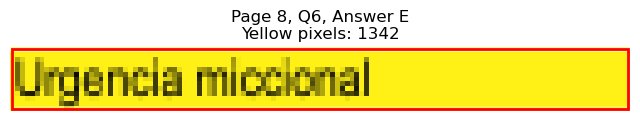


Page 8, Q6 - Selected Answer: E (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=85.0, y0=518.8, x1=239.6, y1=530.9
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 806
Page 8, Q7, A: Yellow percentage: 0.0%


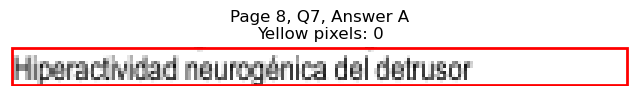

Page 8, Q7 - B: Detected box: x0=85.0, y0=530.9, x1=228.5, y1=543.0
Page 8, Q7, B: Yellow pixels: 1665
Page 8, Q7, B: Total non-white pixels: 2484
Page 8, Q7, B: Yellow percentage: 67.0%


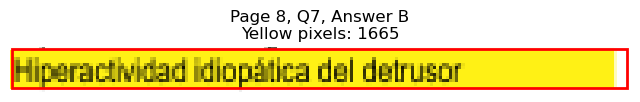

Page 8, Q7 - C: Detected box: x0=85.0, y0=542.9, x1=227.1, y1=555.0
Page 8, Q7, C: Yellow pixels: 187
Page 8, Q7, C: Total non-white pixels: 938
Page 8, Q7, C: Yellow percentage: 19.9%


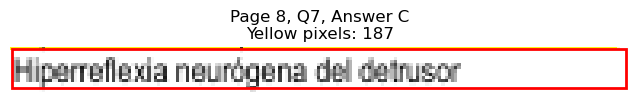

Page 8, Q7 - D: Detected box: x0=336.7, y0=518.8, x1=491.3, y1=530.9
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 841
Page 8, Q7, D: Yellow percentage: 0.0%


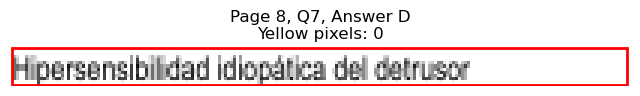

Page 8, Q7 - E: Detected box: x0=336.7, y0=530.9, x1=474.1, y1=543.0
Page 8, Q7, E: Yellow pixels: 0
Page 8, Q7, E: Total non-white pixels: 735
Page 8, Q7, E: Yellow percentage: 0.0%


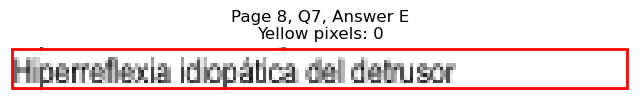


Page 8, Q7 - Selected Answer: B (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=85.0, y0=579.1, x1=190.4, y1=591.2
Page 8, Q8, A: Yellow pixels: 1454
Page 8, Q8, A: Total non-white pixels: 2041
Page 8, Q8, A: Yellow percentage: 71.2%


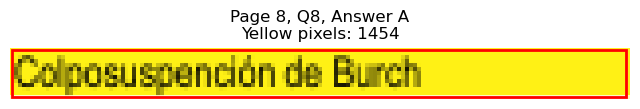

Page 8, Q8 - B: Detected box: x0=85.0, y0=591.2, x1=238.1, y1=603.3
Page 8, Q8, B: Yellow pixels: 0
Page 8, Q8, B: Total non-white pixels: 992
Page 8, Q8, B: Yellow percentage: 0.0%


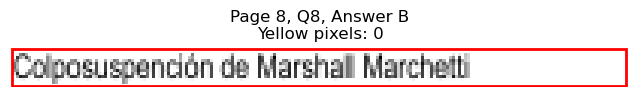

Page 8, Q8 - C: Detected box: x0=85.0, y0=603.2, x1=218.6, y1=615.3
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 722
Page 8, Q8, C: Yellow percentage: 0.0%


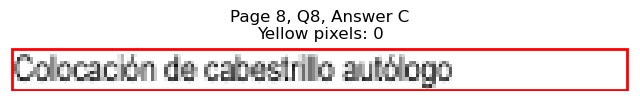

Page 8, Q8 - D: Detected box: x0=336.7, y0=579.1, x1=438.7, y1=591.2
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 522
Page 8, Q8, D: Yellow percentage: 0.0%


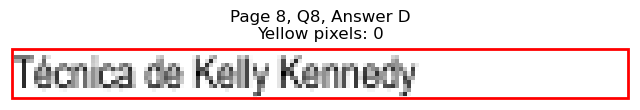

Page 8, Q8 - E: Detected box: x0=336.7, y0=591.2, x1=459.7, y1=603.3
Page 8, Q8, E: Yellow pixels: 0
Page 8, Q8, E: Total non-white pixels: 621
Page 8, Q8, E: Yellow percentage: 0.0%


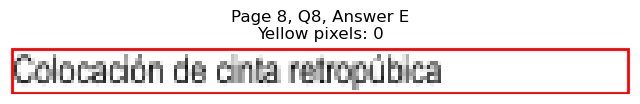


Page 8, Q8 - Selected Answer: A (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=85.0, y0=639.3, x1=172.6, y1=651.4
Page 8, Q9, A: Yellow pixels: 0
Page 8, Q9, A: Total non-white pixels: 387
Page 8, Q9, A: Yellow percentage: 0.0%


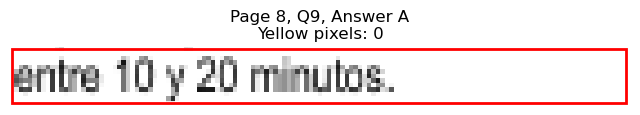

Page 8, Q9 - B: Detected box: x0=85.0, y0=651.4, x1=170.2, y1=663.5
Page 8, Q9, B: Yellow pixels: 0
Page 8, Q9, B: Total non-white pixels: 401
Page 8, Q9, B: Yellow percentage: 0.0%


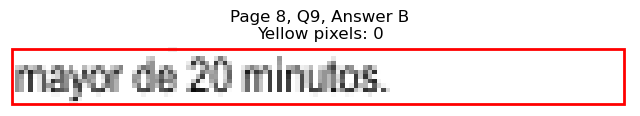

Page 8, Q9 - C: Detected box: x0=85.0, y0=663.4, x1=172.6, y1=675.5
Page 8, Q9, C: Yellow pixels: 0
Page 8, Q9, C: Total non-white pixels: 394
Page 8, Q9, C: Yellow percentage: 0.0%


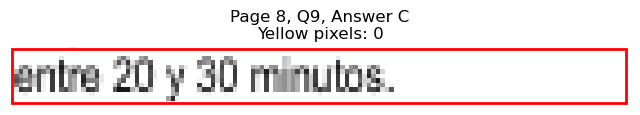

Page 8, Q9 - D: Detected box: x0=336.7, y0=639.3, x1=422.4, y1=651.4
Page 8, Q9, D: Yellow pixels: 0
Page 8, Q9, D: Total non-white pixels: 395
Page 8, Q9, D: Yellow percentage: 0.0%


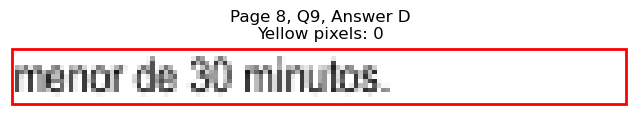

Page 8, Q9 - E: Detected box: x0=336.7, y0=651.4, x1=422.4, y1=663.5
Page 8, Q9, E: Yellow pixels: 1484
Page 8, Q9, E: Total non-white pixels: 1781
Page 8, Q9, E: Yellow percentage: 83.3%


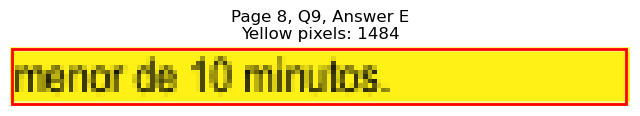


Page 8, Q9 - Selected Answer: E (based on yellow pixel count)




Page 8, Q10 - A: Detected box: x0=85.0, y0=711.7, x1=177.9, y1=723.8
Page 8, Q10, A: Yellow pixels: 0
Page 8, Q10, A: Total non-white pixels: 463
Page 8, Q10, A: Yellow percentage: 0.0%


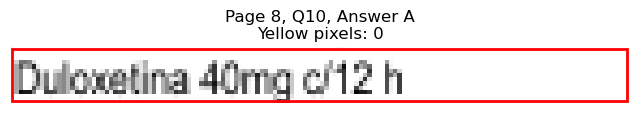

Page 8, Q10 - B: Detected box: x0=85.0, y0=723.7, x1=218.6, y1=735.8
Page 8, Q10, B: Yellow pixels: 0
Page 8, Q10, B: Total non-white pixels: 654
Page 8, Q10, B: Yellow percentage: 0.0%


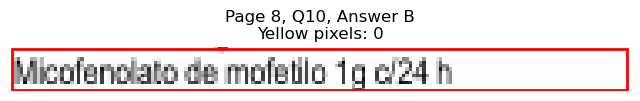

Page 8, Q10 - C: Detected box: x0=85.0, y0=735.8, x1=181.7, y1=747.9
Page 8, Q10, C: Yellow pixels: 1365
Page 8, Q10, C: Total non-white pixels: 1924
Page 8, Q10, C: Yellow percentage: 70.9%


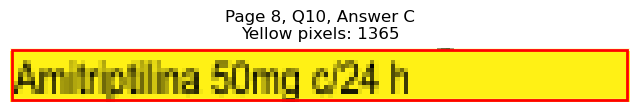

Page 8, Q10 - D: Detected box: x0=336.7, y0=711.7, x1=434.8, y1=723.8
Page 8, Q10, D: Yellow pixels: 0
Page 8, Q10, D: Total non-white pixels: 467
Page 8, Q10, D: Yellow percentage: 0.0%


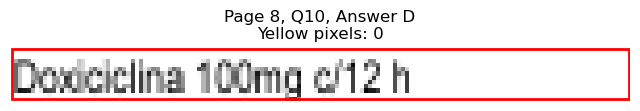

Page 8, Q10 - E: Detected box: x0=336.7, y0=723.7, x1=427.2, y1=735.8
Page 8, Q10, E: Yellow pixels: 0
Page 8, Q10, E: Total non-white pixels: 459
Page 8, Q10, E: Yellow percentage: 0.0%


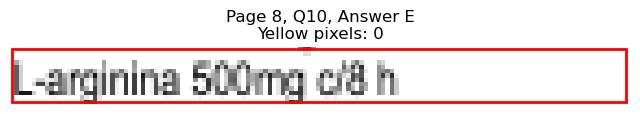


Page 8, Q10 - Selected Answer: C (based on yellow pixel count)





Page 9: Found 10 questions
Page 9, Q1 - A: Detected box: x0=85.0, y0=121.2, x1=256.4, y1=133.3
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 864
Page 9, Q1, A: Yellow percentage: 0.0%


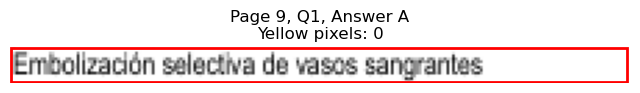

Page 9, Q1 - B: Detected box: x0=85.0, y0=133.2, x1=202.3, y1=145.3
Page 9, Q1, B: Yellow pixels: 0
Page 9, Q1, B: Total non-white pixels: 600
Page 9, Q1, B: Yellow percentage: 0.0%


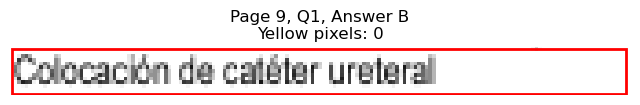

Page 9, Q1 - C: Detected box: x0=85.0, y0=145.3, x1=226.1, y1=157.4
Page 9, Q1, C: Yellow pixels: 0
Page 9, Q1, C: Total non-white pixels: 685
Page 9, Q1, C: Yellow percentage: 0.0%


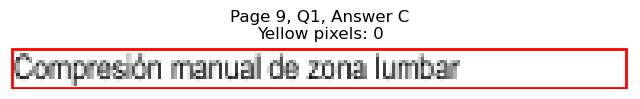

Page 9, Q1 - D: Detected box: x0=336.7, y0=121.2, x1=445.8, y1=133.3
Page 9, Q1, D: Yellow pixels: 1449
Page 9, Q1, D: Total non-white pixels: 2080
Page 9, Q1, D: Yellow percentage: 69.7%


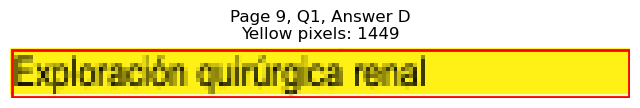

Page 9, Q1 - E: Detected box: x0=336.7, y0=133.2, x1=439.2, y1=145.3
Page 9, Q1, E: Yellow pixels: 0
Page 9, Q1, E: Total non-white pixels: 677
Page 9, Q1, E: Yellow percentage: 0.0%


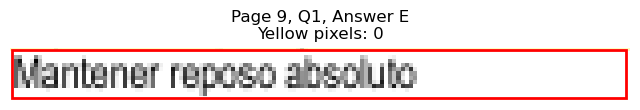


Page 9, Q1 - Selected Answer: D (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=136.7, y1=193.5
Page 9, Q2, A: Yellow pixels: 1122
Page 9, Q2, A: Total non-white pixels: 1339
Page 9, Q2, A: Yellow percentage: 83.8%


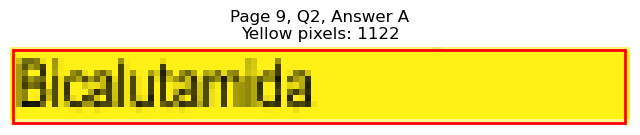

Page 9, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=125.2, y1=205.5
Page 9, Q2, B: Yellow pixels: 92
Page 9, Q2, B: Total non-white pixels: 305
Page 9, Q2, B: Yellow percentage: 30.2%


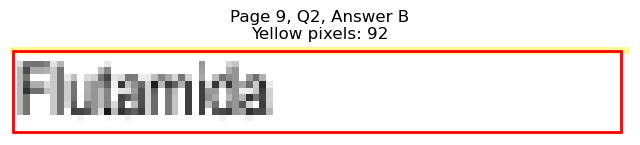

Page 9, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=128.1, y1=217.7
Page 9, Q2, C: Yellow pixels: 0
Page 9, Q2, C: Total non-white pixels: 254
Page 9, Q2, C: Yellow percentage: 0.0%


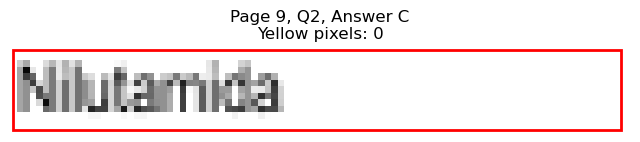

Page 9, Q2 - D: Detected box: x0=336.7, y0=181.4, x1=395.1, y1=193.5
Page 9, Q2, D: Yellow pixels: 0
Page 9, Q2, D: Total non-white pixels: 353
Page 9, Q2, D: Yellow percentage: 0.0%


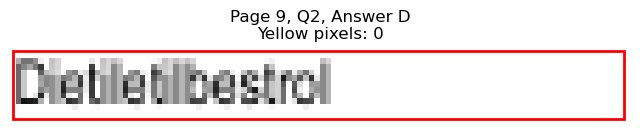

Page 9, Q2 - E: Detected box: x0=336.7, y0=193.4, x1=384.1, y1=205.5
Page 9, Q2, E: Yellow pixels: 0
Page 9, Q2, E: Total non-white pixels: 239
Page 9, Q2, E: Yellow percentage: 0.0%


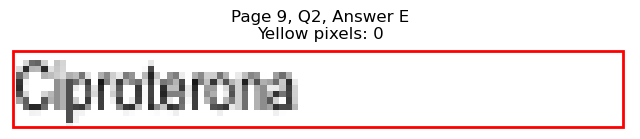


Page 9, Q2 - Selected Answer: A (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=85.0, y0=241.7, x1=128.5, y1=253.8
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 225
Page 9, Q3, A: Yellow percentage: 0.0%


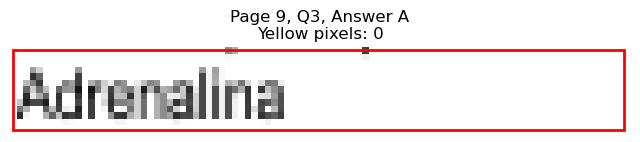

Page 9, Q3 - B: Detected box: x0=85.0, y0=253.7, x1=141.5, y1=265.8
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 298
Page 9, Q3, B: Yellow percentage: 0.0%


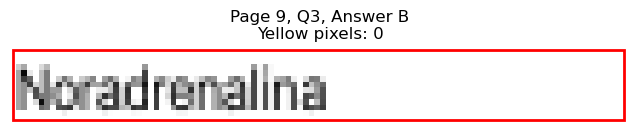

Page 9, Q3 - C: Detected box: x0=85.0, y0=265.8, x1=135.7, y1=277.9
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 251
Page 9, Q3, C: Yellow percentage: 0.0%


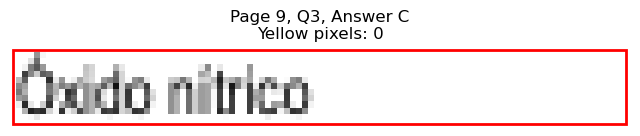

Page 9, Q3 - D: Detected box: x0=336.7, y0=241.7, x1=382.6, y1=253.8
Page 9, Q3, D: Yellow pixels: 977
Page 9, Q3, D: Total non-white pixels: 1261
Page 9, Q3, D: Yellow percentage: 77.5%


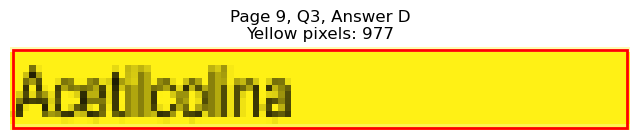

Page 9, Q3 - E: Detected box: x0=336.7, y0=253.7, x1=380.7, y1=265.8
Page 9, Q3, E: Yellow pixels: 95
Page 9, Q3, E: Total non-white pixels: 324
Page 9, Q3, E: Yellow percentage: 29.3%


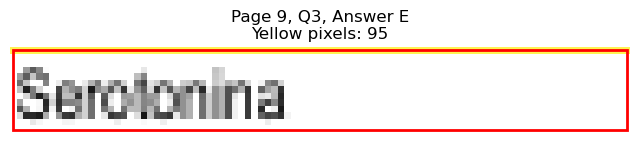


Page 9, Q3 - Selected Answer: D (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=85.0, y0=313.9, x1=180.7, y1=326.0
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 557
Page 9, Q4, A: Yellow percentage: 0.0%


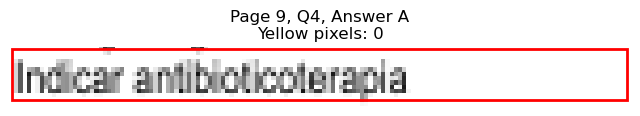

Page 9, Q4 - B: Detected box: x0=85.0, y0=326.1, x1=196.6, y1=338.2
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 544
Page 9, Q4, B: Yellow percentage: 0.0%


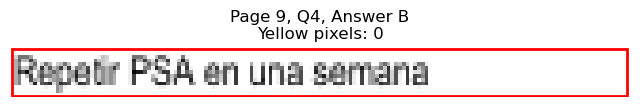

Page 9, Q4 - C: Detected box: x0=85.0, y0=338.1, x1=175.0, y1=350.2
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 448
Page 9, Q4, C: Yellow percentage: 0.0%


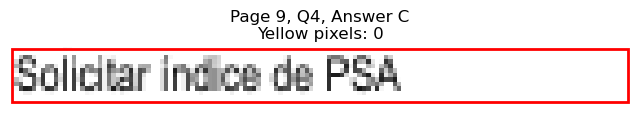

Page 9, Q4 - D: Detected box: x0=336.7, y0=313.9, x1=473.1, y1=326.0
Page 9, Q4, D: Yellow pixels: 0
Page 9, Q4, D: Total non-white pixels: 696
Page 9, Q4, D: Yellow percentage: 0.0%


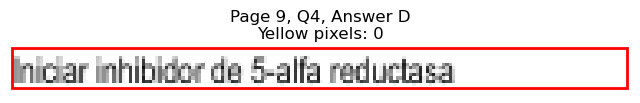

Page 9, Q4 - E: Detected box: x0=336.7, y0=326.1, x1=444.9, y1=338.2
Page 9, Q4, E: Yellow pixels: 1479
Page 9, Q4, E: Total non-white pixels: 2067
Page 9, Q4, E: Yellow percentage: 71.6%


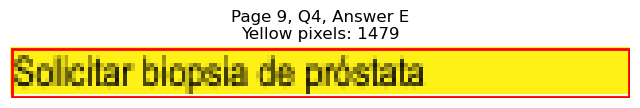


Page 9, Q4 - Selected Answer: E (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=85.0, y0=386.3, x1=139.6, y1=398.4
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 302
Page 9, Q5, A: Yellow percentage: 0.0%


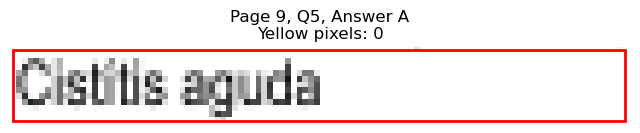

Page 9, Q5 - B: Detected box: x0=85.0, y0=398.3, x1=157.7, y1=410.4
Page 9, Q5, B: Yellow pixels: 0
Page 9, Q5, B: Total non-white pixels: 362
Page 9, Q5, B: Yellow percentage: 0.0%


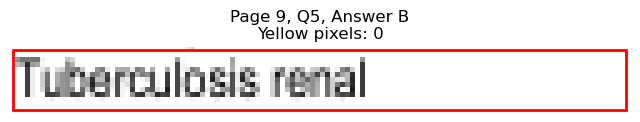

Page 9, Q5 - C: Detected box: x0=85.0, y0=410.4, x1=165.4, y1=422.5
Page 9, Q5, C: Yellow pixels: 0
Page 9, Q5, C: Total non-white pixels: 416
Page 9, Q5, C: Yellow percentage: 0.0%


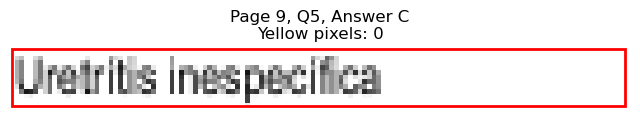

Page 9, Q5 - D: Detected box: x0=336.7, y0=386.3, x1=404.6, y1=398.4
Page 9, Q5, D: Yellow pixels: 119
Page 9, Q5, D: Total non-white pixels: 472
Page 9, Q5, D: Yellow percentage: 25.2%


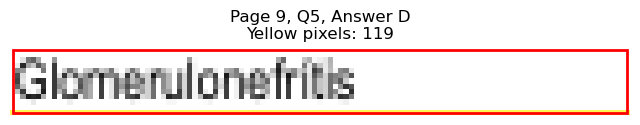

Page 9, Q5 - E: Detected box: x0=336.7, y0=398.3, x1=410.4, y1=410.4
Page 9, Q5, E: Yellow pixels: 1302
Page 9, Q5, E: Total non-white pixels: 1625
Page 9, Q5, E: Yellow percentage: 80.1%


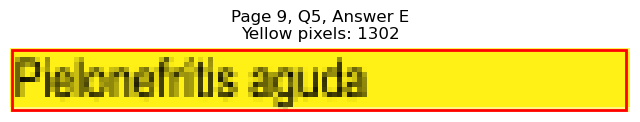


Page 9, Q5 - Selected Answer: E (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=85.0, y0=458.6, x1=271.3, y1=470.7
Page 9, Q6, A: Yellow pixels: 1722
Page 9, Q6, A: Total non-white pixels: 2483
Page 9, Q6, A: Yellow percentage: 69.4%


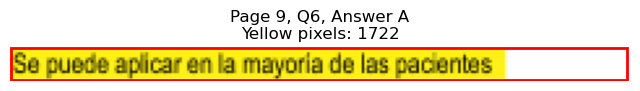

Page 9, Q6 - B: Detected box: x0=85.0, y0=470.7, x1=227.7, y1=482.8
Page 9, Q6, B: Yellow pixels: 190
Page 9, Q6, B: Total non-white pixels: 892
Page 9, Q6, B: Yellow percentage: 21.3%


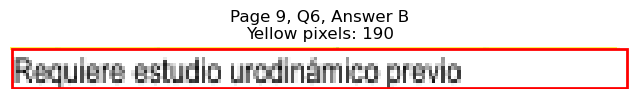

Page 9, Q6 - C: Detected box: x0=85.0, y0=482.7, x1=258.3, y1=494.8
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 890
Page 9, Q6, C: Yellow percentage: 0.0%


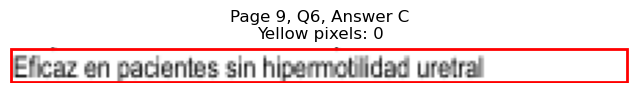

Page 9, Q6 - D: Detected box: x0=336.7, y0=458.6, x1=510.9, y1=470.7
Page 9, Q6, D: Yellow pixels: 0
Page 9, Q6, D: Total non-white pixels: 905
Page 9, Q6, D: Yellow percentage: 0.0%


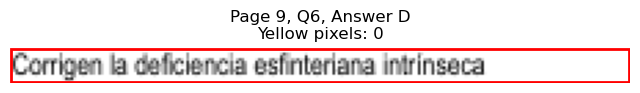

Page 9, Q6 - E: Detected box: x0=336.7, y0=470.7, x1=514.3, y1=482.8
Page 9, Q6, E: Yellow pixels: 0
Page 9, Q6, E: Total non-white pixels: 891
Page 9, Q6, E: Yellow percentage: 0.0%


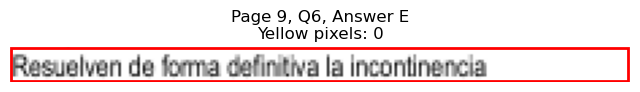


Page 9, Q6 - Selected Answer: A (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=85.0, y0=530.9, x1=153.5, y1=543.0
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 343
Page 9, Q7, A: Yellow percentage: 0.0%


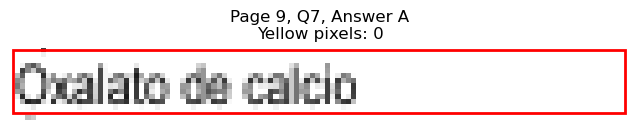

Page 9, Q7 - B: Detected box: x0=85.0, y0=542.9, x1=130.0, y1=555.0
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 225
Page 9, Q7, B: Yellow percentage: 0.0%


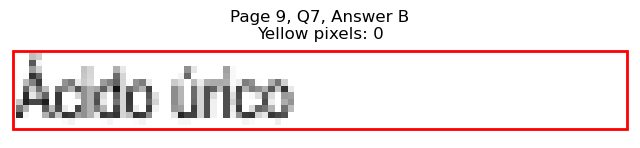

Page 9, Q7 - C: Detected box: x0=85.0, y0=554.9, x1=190.9, y1=567.0
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 530
Page 9, Q7, C: Yellow percentage: 0.0%


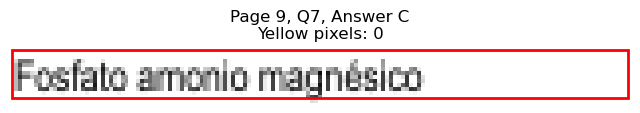

Page 9, Q7 - D: Detected box: x0=336.7, y0=530.9, x1=404.2, y1=543.0
Page 9, Q7, D: Yellow pixels: 1160
Page 9, Q7, D: Total non-white pixels: 1547
Page 9, Q7, D: Yellow percentage: 75.0%


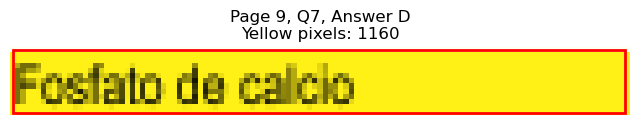

Page 9, Q7 - E: Detected box: x0=336.7, y0=542.9, x1=407.6, y1=555.0
Page 9, Q7, E: Yellow pixels: 122
Page 9, Q7, E: Total non-white pixels: 503
Page 9, Q7, E: Yellow percentage: 24.3%


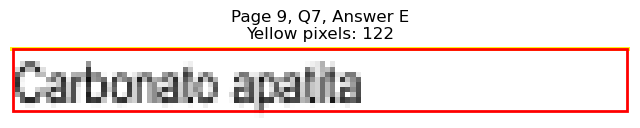


Page 9, Q7 - Selected Answer: D (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=85.0, y0=603.2, x1=202.4, y1=615.3
Page 9, Q8, A: Yellow pixels: 1536
Page 9, Q8, A: Total non-white pixels: 2197
Page 9, Q8, A: Yellow percentage: 69.9%


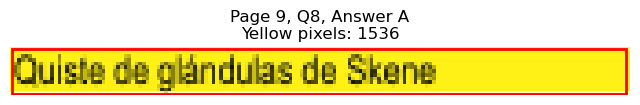

Page 9, Q8 - B: Detected box: x0=85.0, y0=615.2, x1=154.8, y1=627.3
Page 9, Q8, B: Yellow pixels: 0
Page 9, Q8, B: Total non-white pixels: 483
Page 9, Q8, B: Yellow percentage: 0.0%


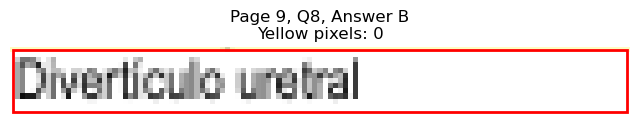

Page 9, Q8 - C: Detected box: x0=85.0, y0=627.3, x1=218.6, y1=639.4
Page 9, Q8, C: Yellow pixels: 0
Page 9, Q8, C: Total non-white pixels: 620
Page 9, Q8, C: Yellow percentage: 0.0%


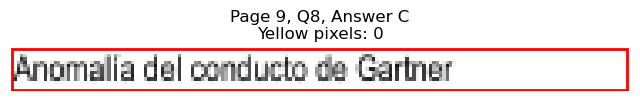

Page 9, Q8 - D: Detected box: x0=336.7, y0=603.2, x1=405.1, y1=615.3
Page 9, Q8, D: Yellow pixels: 0
Page 9, Q8, D: Total non-white pixels: 340
Page 9, Q8, D: Yellow percentage: 0.0%


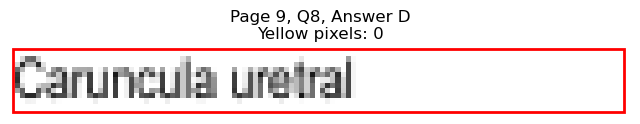

Page 9, Q8 - E: Detected box: x0=336.7, y0=615.2, x1=444.5, y1=627.3
Page 9, Q8, E: Yellow pixels: 0
Page 9, Q8, E: Total non-white pixels: 521
Page 9, Q8, E: Yellow percentage: 0.0%


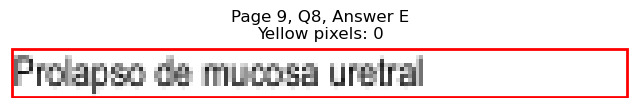


Page 9, Q8 - Selected Answer: A (based on yellow pixel count)




Page 9, Q9 - A: Detected box: x0=85.0, y0=663.4, x1=176.4, y1=675.5
Page 9, Q9, A: Yellow pixels: 0
Page 9, Q9, A: Total non-white pixels: 465
Page 9, Q9, A: Yellow percentage: 0.0%


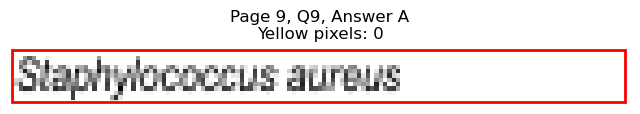

Page 9, Q9 - B: Detected box: x0=85.0, y0=675.4, x1=140.5, y1=687.5
Page 9, Q9, B: Yellow pixels: 0
Page 9, Q9, B: Total non-white pixels: 312
Page 9, Q9, B: Yellow percentage: 0.0%


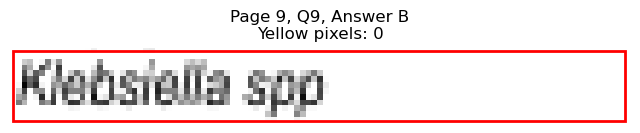

Page 9, Q9 - C: Detected box: x0=85.0, y0=687.5, x1=147.3, y1=699.7
Page 9, Q9, C: Yellow pixels: 1230
Page 9, Q9, C: Total non-white pixels: 1482
Page 9, Q9, C: Yellow percentage: 83.0%


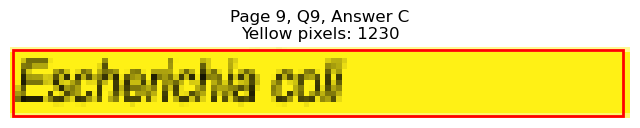

Page 9, Q9 - D: Detected box: x0=336.7, y0=663.4, x1=440.1, y1=675.5
Page 9, Q9, D: Yellow pixels: 0
Page 9, Q9, D: Total non-white pixels: 557
Page 9, Q9, D: Yellow percentage: 0.0%


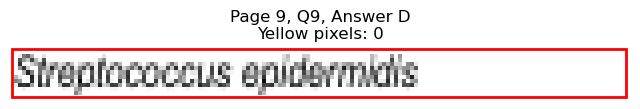

Page 9, Q9 - E: Detected box: x0=336.7, y0=675.4, x1=385.5, y1=687.5
Page 9, Q9, E: Yellow pixels: 0
Page 9, Q9, E: Total non-white pixels: 263
Page 9, Q9, E: Yellow percentage: 0.0%


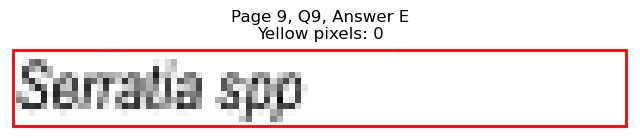


Page 9, Q9 - Selected Answer: C (based on yellow pixel count)




Page 9, Q10 - A: Detected box: x0=85.0, y0=723.7, x1=128.1, y1=735.8
Page 9, Q10, A: Yellow pixels: 0
Page 9, Q10, A: Total non-white pixels: 203
Page 9, Q10, A: Yellow percentage: 0.0%


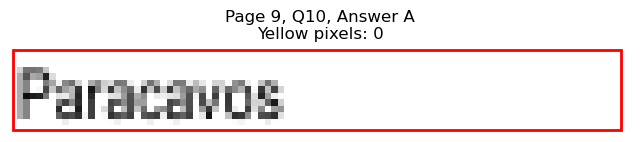

Page 9, Q10 - B: Detected box: x0=85.0, y0=735.8, x1=152.9, y1=747.9
Page 9, Q10, B: Yellow pixels: 1155
Page 9, Q10, B: Total non-white pixels: 1547
Page 9, Q10, B: Yellow percentage: 74.7%


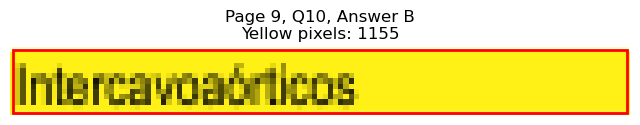

Page 9, Q10 - C: Detected box: x0=85.0, y0=747.8, x1=135.7, y1=759.9
Page 9, Q10, C: Yellow pixels: 102
Page 9, Q10, C: Total non-white pixels: 368
Page 9, Q10, C: Yellow percentage: 27.7%


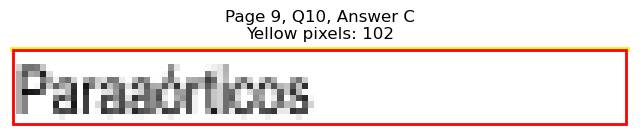

Page 9, Q10 - D: Detected box: x0=336.7, y0=723.7, x1=390.3, y1=735.8
Page 9, Q10, D: Yellow pixels: 0
Page 9, Q10, D: Total non-white pixels: 302
Page 9, Q10, D: Yellow percentage: 0.0%


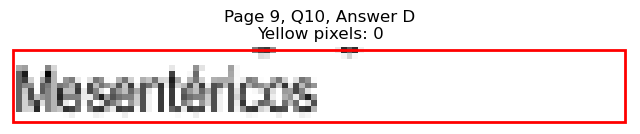

Page 9, Q10 - E: Detected box: x0=336.7, y0=735.8, x1=391.3, y1=747.9
Page 9, Q10, E: Yellow pixels: 0
Page 9, Q10, E: Total non-white pixels: 294
Page 9, Q10, E: Yellow percentage: 0.0%


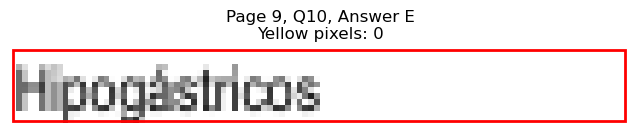


Page 9, Q10 - Selected Answer: B (based on yellow pixel count)





Page 10: Found 7 questions
Page 10, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=165.9, y1=109.2
Page 10, Q1, A: Yellow pixels: 0
Page 10, Q1, A: Total non-white pixels: 443
Page 10, Q1, A: Yellow percentage: 0.0%


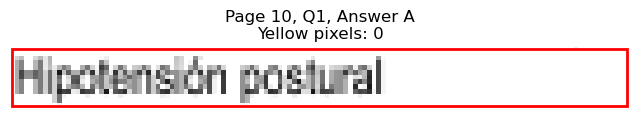

Page 10, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=176.4, y1=121.3
Page 10, Q1, B: Yellow pixels: 1372
Page 10, Q1, B: Total non-white pixels: 1859
Page 10, Q1, B: Yellow percentage: 73.8%


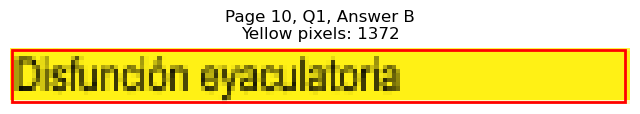

Page 10, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=140.1, y1=133.3
Page 10, Q1, C: Yellow pixels: 0
Page 10, Q1, C: Total non-white pixels: 405
Page 10, Q1, C: Yellow percentage: 0.0%


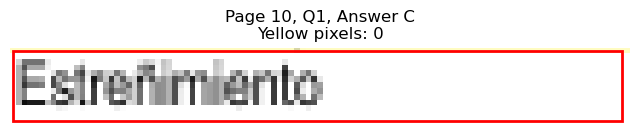

Page 10, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=394.2, y1=109.2
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 269
Page 10, Q1, D: Yellow percentage: 0.0%


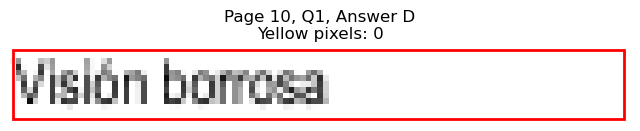

Page 10, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=407.0, y1=121.3
Page 10, Q1, E: Yellow pixels: 0
Page 10, Q1, E: Total non-white pixels: 390
Page 10, Q1, E: Yellow percentage: 0.0%


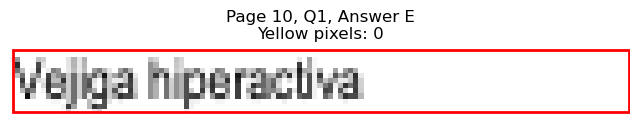


Page 10, Q1 - Selected Answer: B (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=85.0, y0=157.3, x1=130.9, y1=169.4
Page 10, Q2, A: Yellow pixels: 0
Page 10, Q2, A: Total non-white pixels: 231
Page 10, Q2, A: Yellow percentage: 0.0%


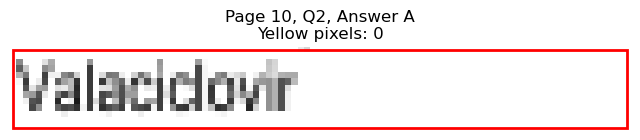

Page 10, Q2 - B: Detected box: x0=85.0, y0=169.4, x1=131.4, y1=181.5
Page 10, Q2, B: Yellow pixels: 0
Page 10, Q2, B: Total non-white pixels: 217
Page 10, Q2, B: Yellow percentage: 0.0%


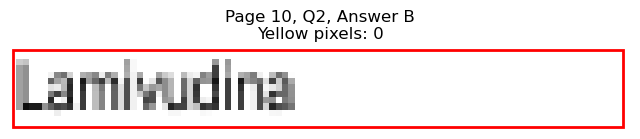

Page 10, Q2 - C: Detected box: x0=85.0, y0=181.4, x1=120.9, y1=193.5
Page 10, Q2, C: Yellow pixels: 0
Page 10, Q2, C: Total non-white pixels: 179
Page 10, Q2, C: Yellow percentage: 0.0%


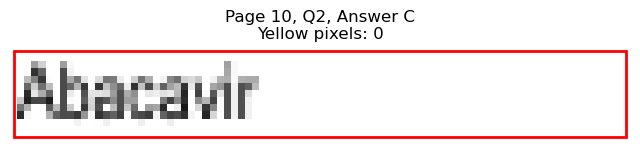

Page 10, Q2 - D: Detected box: x0=336.7, y0=157.3, x1=375.0, y1=169.4
Page 10, Q2, D: Yellow pixels: 0
Page 10, Q2, D: Total non-white pixels: 173
Page 10, Q2, D: Yellow percentage: 0.0%


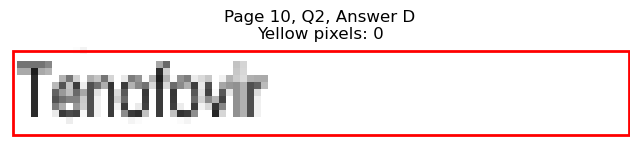

Page 10, Q2 - E: Detected box: x0=336.7, y0=169.4, x1=371.6, y1=181.5
Page 10, Q2, E: Yellow pixels: 978
Page 10, Q2, E: Total non-white pixels: 1118
Page 10, Q2, E: Yellow percentage: 87.5%


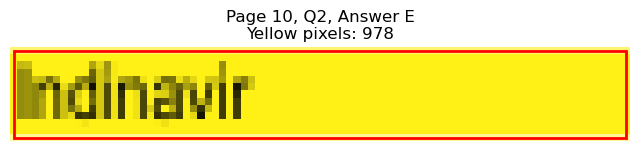


Page 10, Q2 - Selected Answer: E (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=85.0, y0=217.5, x1=133.8, y1=229.7
Page 10, Q3, A: Yellow pixels: 1093
Page 10, Q3, A: Total non-white pixels: 1300
Page 10, Q3, A: Yellow percentage: 84.1%


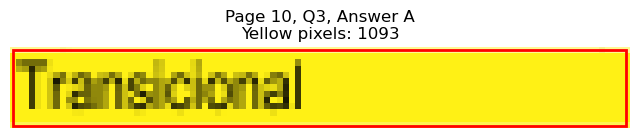

Page 10, Q3 - B: Detected box: x0=85.0, y0=229.7, x1=123.7, y1=241.8
Page 10, Q3, B: Yellow pixels: 90
Page 10, Q3, B: Total non-white pixels: 274
Page 10, Q3, B: Yellow percentage: 32.8%


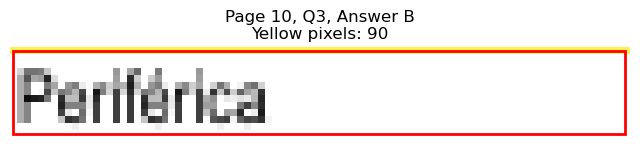

Page 10, Q3 - C: Detected box: x0=85.0, y0=241.7, x1=115.1, y1=253.8
Page 10, Q3, C: Yellow pixels: 0
Page 10, Q3, C: Total non-white pixels: 162
Page 10, Q3, C: Yellow percentage: 0.0%


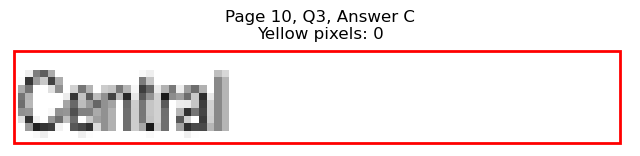

Page 10, Q3 - D: Detected box: x0=336.7, y0=217.5, x1=364.9, y1=229.7
Page 10, Q3, D: Yellow pixels: 0
Page 10, Q3, D: Total non-white pixels: 145
Page 10, Q3, D: Yellow percentage: 0.0%


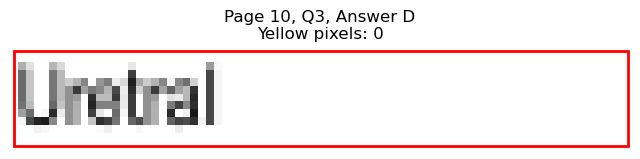

Page 10, Q3 - E: Detected box: x0=336.7, y0=229.7, x1=392.2, y1=241.8
Page 10, Q3, E: Yellow pixels: 0
Page 10, Q3, E: Total non-white pixels: 276
Page 10, Q3, E: Yellow percentage: 0.0%


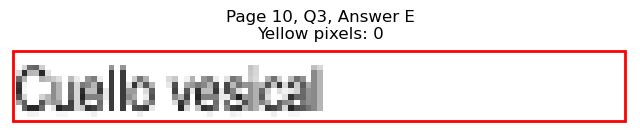


Page 10, Q3 - Selected Answer: A (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=85.0, y0=277.8, x1=178.8, y1=289.9
Page 10, Q4, A: Yellow pixels: 1363
Page 10, Q4, A: Total non-white pixels: 1885
Page 10, Q4, A: Yellow percentage: 72.3%


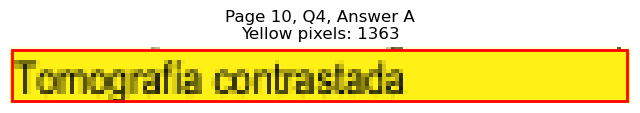

Page 10, Q4 - B: Detected box: x0=85.0, y0=289.9, x1=155.3, y1=302.0
Page 10, Q4, B: Yellow pixels: 118
Page 10, Q4, B: Total non-white pixels: 495
Page 10, Q4, B: Yellow percentage: 23.8%


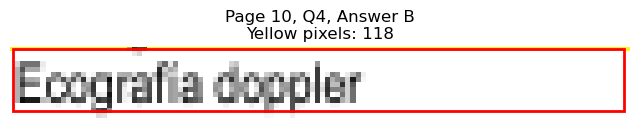

Page 10, Q4 - C: Detected box: x0=85.0, y0=301.9, x1=156.3, y1=314.0
Page 10, Q4, C: Yellow pixels: 0
Page 10, Q4, C: Total non-white pixels: 384
Page 10, Q4, C: Yellow percentage: 0.0%


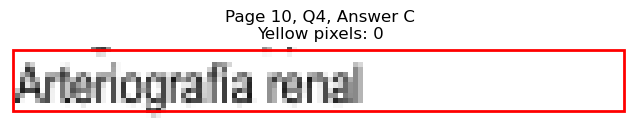

Page 10, Q4 - D: Detected box: x0=336.7, y0=277.8, x1=380.2, y1=289.9
Page 10, Q4, D: Yellow pixels: 0
Page 10, Q4, D: Total non-white pixels: 239
Page 10, Q4, D: Yellow percentage: 0.0%


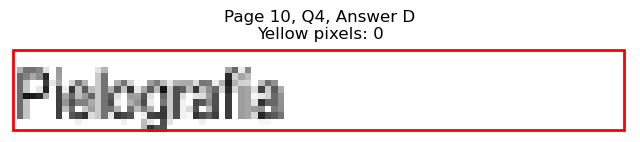

Page 10, Q4 - E: Detected box: x0=336.7, y0=289.9, x1=426.7, y1=302.0
Page 10, Q4, E: Yellow pixels: 0
Page 10, Q4, E: Total non-white pixels: 468
Page 10, Q4, E: Yellow percentage: 0.0%


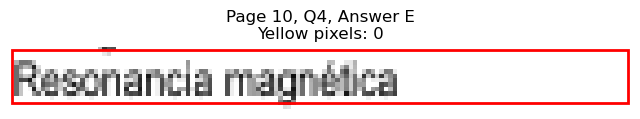


Page 10, Q4 - Selected Answer: A (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=85.0, y0=338.1, x1=254.9, y1=350.2
Page 10, Q5, A: Yellow pixels: 1588
Page 10, Q5, A: Total non-white pixels: 2483
Page 10, Q5, A: Yellow percentage: 64.0%


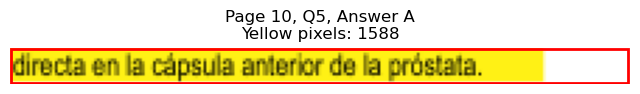

Page 10, Q5 - B: Detected box: x0=85.0, y0=350.2, x1=262.6, y1=362.3
Page 10, Q5, B: Yellow pixels: 0
Page 10, Q5, B: Total non-white pixels: 1076
Page 10, Q5, B: Yellow percentage: 0.0%


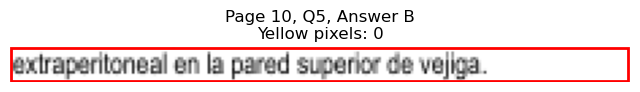

Page 10, Q5 - C: Detected box: x0=85.0, y0=362.2, x1=253.5, y1=374.3
Page 10, Q5, C: Yellow pixels: 0
Page 10, Q5, C: Total non-white pixels: 867
Page 10, Q5, C: Yellow percentage: 0.0%


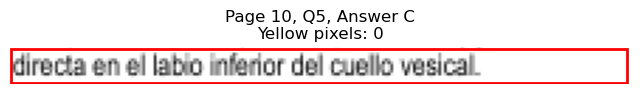

Page 10, Q5 - D: Detected box: x0=336.7, y0=338.1, x1=518.6, y1=350.2
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 921
Page 10, Q5, D: Yellow percentage: 0.0%


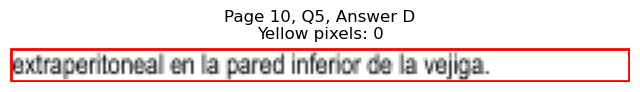

Page 10, Q5 - E: Detected box: x0=336.7, y0=350.2, x1=510.9, y1=362.3
Page 10, Q5, E: Yellow pixels: 0
Page 10, Q5, E: Total non-white pixels: 896
Page 10, Q5, E: Yellow percentage: 0.0%


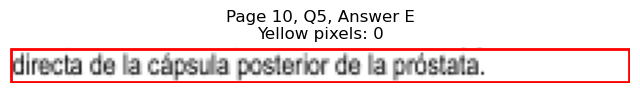


Page 10, Q5 - Selected Answer: A (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=85.0, y0=422.4, x1=141.5, y1=434.5
Page 10, Q6, A: Yellow pixels: 0
Page 10, Q6, A: Total non-white pixels: 298
Page 10, Q6, A: Yellow percentage: 0.0%


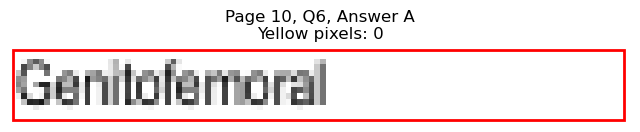

Page 10, Q6 - B: Detected box: x0=85.0, y0=434.4, x1=126.1, y1=446.5
Page 10, Q6, B: Yellow pixels: 0
Page 10, Q6, B: Total non-white pixels: 213
Page 10, Q6, B: Yellow percentage: 0.0%


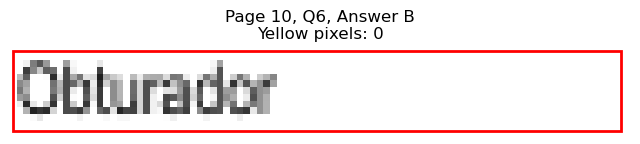

Page 10, Q6 - C: Detected box: x0=85.0, y0=446.6, x1=128.1, y1=458.7
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 239
Page 10, Q6, C: Yellow percentage: 0.0%


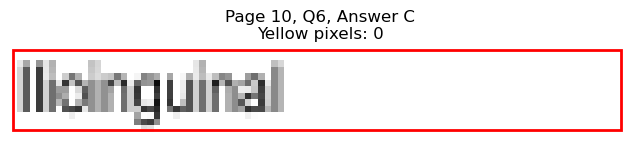

Page 10, Q6 - D: Detected box: x0=336.7, y0=422.4, x1=373.5, y1=434.5
Page 10, Q6, D: Yellow pixels: 999
Page 10, Q6, D: Total non-white pixels: 1144
Page 10, Q6, D: Yellow percentage: 87.3%


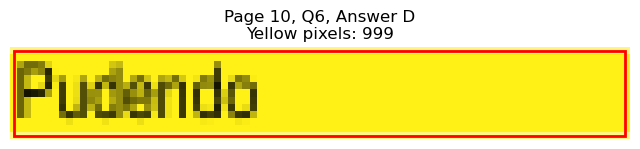

Page 10, Q6 - E: Detected box: x0=336.7, y0=434.4, x1=399.4, y1=446.5
Page 10, Q6, E: Yellow pixels: 114
Page 10, Q6, E: Total non-white pixels: 423
Page 10, Q6, E: Yellow percentage: 27.0%


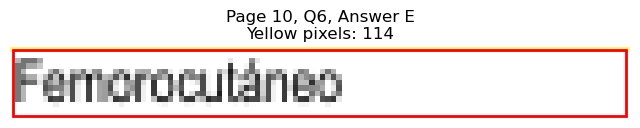


Page 10, Q6 - Selected Answer: D (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=85.0, y0=482.7, x1=138.1, y1=494.8
Page 10, Q7, A: Yellow pixels: 1038
Page 10, Q7, A: Total non-white pixels: 1365
Page 10, Q7, A: Yellow percentage: 76.0%


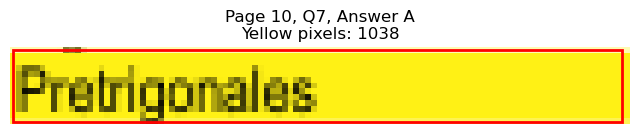

Page 10, Q7 - B: Detected box: x0=85.0, y0=494.7, x1=145.8, y1=506.8
Page 10, Q7, B: Yellow pixels: 108
Page 10, Q7, B: Total non-white pixels: 443
Page 10, Q7, B: Yellow percentage: 24.4%


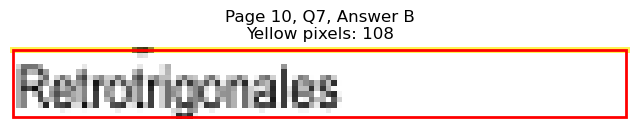

Page 10, Q7 - C: Detected box: x0=85.0, y0=506.8, x1=152.4, y1=518.9
Page 10, Q7, C: Yellow pixels: 0
Page 10, Q7, C: Total non-white pixels: 377
Page 10, Q7, C: Yellow percentage: 0.0%


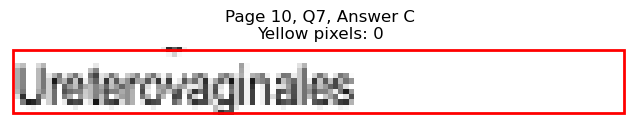

Page 10, Q7 - D: Detected box: x0=336.7, y0=482.7, x1=399.9, y1=494.8
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 336
Page 10, Q7, D: Yellow percentage: 0.0%


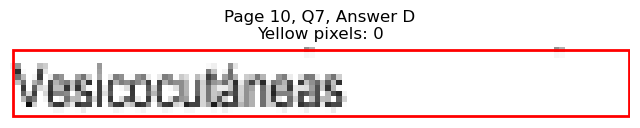

Page 10, Q7 - E: Detected box: x0=336.7, y0=494.7, x1=395.6, y1=506.8
Page 10, Q7, E: Yellow pixels: 0
Page 10, Q7, E: Total non-white pixels: 282
Page 10, Q7, E: Yellow percentage: 0.0%


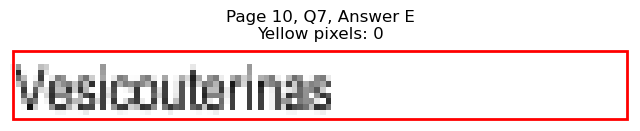


Page 10, Q7 - Selected Answer: A (based on yellow pixel count)





⚠️ The following questions were skipped due to missing options:
Page 3, Q10
Page 4, Q11


In [17]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [18]:
questions_df

,question
0,¿Cuál es el sitio más frecuente de metástasis ...
1,¿Cuál es el cálculo urinario con aspecto micro...
2,El músculo psoas mayor se origina a la altura ...
3,"Mujer de 20 años, sufre caída de altura, hemod..."
4,¿Cuál es una manifestación paraneoplásica comú...
...,...
95,¿En qué zona se desarrolla primero la hiperpla...
96,¿Cuál es la prueba de imágenes mas importante ...
97,"En la prostatectomía retropúbica, la enucleaci..."
98,"Varón de 50 años, diabético con manifestacione..."


In [19]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,Recto,Pulmón,Vejiga,Hígado,Hueso
1,Oxalato de calcio,Fosfato de calcio,Estruvita,Ácido úrico,Cistina
2,10a dorsal,2a lumbar,4a lumbar,12a dorsal,5a lumbar
3,I,III,IV,V,II
4,Hipotensión,Policitemia,Hiperuricemia,Hipocalcemia,Poliuria
...,...,...,...,...,...
94,Transicional,Periférica,Central,Uretral,Cuello vesical
95,Tomografía contrastada,Ecografía doppler,Arteriografía renal,Pielografía,Resonancia magnética
96,directa en la cápsula anterior de la próstata.,extraperitoneal en la pared superior de vejiga.,directa en el labio inferior del cuello vesical.,extraperitoneal en la pared inferior de la vej...,directa de la cápsula posterior de la próstata.
97,Genitofemoral,Obturador,Ilioinguinal,Pudendo,Femorocutáneo


In [20]:
correct_answers_df

,correct_answer
0,E
1,C
2,D
3,E
4,B
...,...
96,A
97,A
98,A
99,D


In [21]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,¿Cuál es el sitio más frecuente de metástasis ...,Recto,Pulmón,Vejiga,Hígado,Hueso,E
1,¿Cuál es el cálculo urinario con aspecto micro...,Oxalato de calcio,Fosfato de calcio,Estruvita,Ácido úrico,Cistina,C
2,El músculo psoas mayor se origina a la altura ...,10a dorsal,2a lumbar,4a lumbar,12a dorsal,5a lumbar,D
3,"Mujer de 20 años, sufre caída de altura, hemod...",I,III,IV,V,II,E
4,¿Cuál es una manifestación paraneoplásica comú...,Hipotensión,Policitemia,Hiperuricemia,Hipocalcemia,Poliuria,B
...,...,...,...,...,...,...,...
96,¿Cuál es la prueba de imágenes mas importante ...,directa en la cápsula anterior de la próstata.,extraperitoneal en la pared superior de vejiga.,directa en el labio inferior del cuello vesical.,extraperitoneal en la pared inferior de la vej...,directa de la cápsula posterior de la próstata.,A
97,"En la prostatectomía retropúbica, la enucleaci...",Genitofemoral,Obturador,Ilioinguinal,Pudendo,Femorocutáneo,A
98,"Varón de 50 años, diabético con manifestacione...",Pretrigonales,Retrotrigonales,Ureterovaginales,Vesicocutáneas,Vesicouterinas,A
99,¿Cómo suelen ser las fístulas vesicovaginales ...,NaN,NaN,NaN,NaN,NaN,D


In [22]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2019/UROLOGÍA.csv
